In [ ]:
from google.colab import drive
drive.mount('/content/gdrive')

Mounted at /content/gdrive


In [ ]:

import geopandas as gpd
import os

base = "/content/gdrive/MyDrive/lucknow_census_processed"

roads_path = os.path.join(base, "lucknow_osm_roads_raw.gpkg")
boundary_path = os.path.join(base, "lucknow_district_analytical.gpkg")
output_path = os.path.join(base, "lucknow_osm_roads_clipped.gpkg")

# Load road features and exact district boundary
roads = gpd.read_file(roads_path, layer="roads_raw")
district = gpd.read_file(
    boundary_path,
    layer="district_boundary_2011"
)

print("Road features before clipping:", len(roads))
print("Road CRS:", roads.crs)
print("District CRS:", district.crs)

# Match coordinate systems
if roads.crs != district.crs:
    district = district.to_crs(roads.crs)

# Keep road segments intersecting the actual district polygon
district_geom = district.geometry.union_all()
roads_clipped = roads[
    roads.geometry.intersects(district_geom)
].copy()

# Clip the geometries to the district boundary
roads_clipped["geometry"] = roads_clipped.geometry.intersection(
    district_geom
)
roads_clipped = roads_clipped[
    roads_clipped.geometry.notna()
    & ~roads_clipped.geometry.is_empty
].copy()

# Keep only line geometries
roads_clipped = roads_clipped[
    roads_clipped.geom_type.isin(["LineString", "MultiLineString"])
].copy()

roads_clipped.to_file(
    output_path,
    layer="roads_clipped",
    driver="GPKG"
)

print("\nRoad features after clipping:", len(roads_clipped))
print("\nMost common highway classes:")
print(roads_clipped["highway"].value_counts().head(15))
print("\nSaved:", output_path)
print("Output size (MB):", round(os.path.getsize(output_path) / (1024**2), 2))


/usr/local/lib/python3.13/dist-packages/pyogrio/raw.py:200: RuntimeWarning: Table/view villages_towns_2011_corrected is referenced in gpkg_contents, but does not exist
  return ogr_read(


Road features before clipping: 64088
Road CRS: EPSG:4326
District CRS: EPSG:4326

Road features after clipping: 59417

Most common highway classes:
highway
residential      38895
service          10288
tertiary          2390
unclassified      1989
footway            879
living_street      575
trunk              547
secondary          382
primary            336
motorway           205
track              162
path               162
trunk_link         162
tertiary_link      135
motorway_link      119
Name: count, dtype: int64

Saved: /content/gdrive/MyDrive/lucknow_census_processed/lucknow_osm_roads_clipped.gpkg
Output size (MB): 16.54


In [ ]:

import geopandas as gpd
import os

base = "/content/gdrive/MyDrive/lucknow_census_processed"

roads_path = os.path.join(base, "lucknow_osm_roads_clipped.gpkg")
projected_path = os.path.join(base, "lucknow_osm_roads_projected.gpkg")

roads = gpd.read_file(roads_path, layer="roads_clipped")

print("Road features:", len(roads))
print("Geometry types:")
print(roads.geom_type.value_counts())
print("\nMissing geometries:", roads.geometry.isna().sum())
print("Empty geometries:", roads.geometry.is_empty.sum())
print("Invalid geometries:", (~roads.geometry.is_valid).sum())

# Project to UTM Zone 44N, appropriate for Lucknow
roads_m = roads.to_crs("EPSG:32644")

# Add road length in metres
roads_m["length_m"] = roads_m.geometry.length

print("\nProjected CRS:", roads_m.crs)
print("Total clipped road length (km):",
      round(roads_m["length_m"].sum() / 1000, 2))
print("Zero-length features:",
      (roads_m["length_m"] <= 0).sum())

roads_m.to_file(
    projected_path,
    layer="roads_projected",
    driver="GPKG"
)

print("\nSaved projected roads:", projected_path)
print("File size (MB):",
      round(os.path.getsize(projected_path) / (1024**2), 2))


Road features: 59417
Geometry types:
MultiLineString    59417
Name: count, dtype: int64

Missing geometries: 0
Empty geometries: 0
Invalid geometries: 0

Projected CRS: EPSG:32644
Total clipped road length (km): 14935.99
Zero-length features: 0

Saved projected roads: /content/gdrive/MyDrive/lucknow_census_processed/lucknow_osm_roads_projected.gpkg
File size (MB): 17.02


In [ ]:

!pip -q install osmnx networkx


In [ ]:

import osmnx as ox
import networkx as nx

print("OSMnx version:", ox.__version__)
print("NetworkX version:", nx.__version__)
print("Directed graph support:", hasattr(nx, "DiGraph"))
print("OSMnx graph conversion support:",
      hasattr(ox, "graph_from_gdfs"))


OSMnx version: 2.1.1
NetworkX version: 3.7
Directed graph support: True
OSMnx graph conversion support: True


In [ ]:

import geopandas as gpd
import pandas as pd

base = "/content/gdrive/MyDrive/lucknow_census_processed"
roads_path = f"{base}/lucknow_osm_roads_clipped.gpkg"

roads = gpd.read_file(roads_path, layer="roads_clipped")

print("Total road features:", len(roads))
print("\nAvailable columns:")
print(roads.columns.tolist())

print("\nHighway classifications:")
print(roads["highway"].value_counts(dropna=False).head(25))

for col in ["oneway", "maxspeed", "access", "motor_vehicle", "service"]:
    if col in roads.columns:
        print(f"\n{col} values:")
        print(roads[col].value_counts(dropna=False).head(15))

print("\nSample road records:")
display(
    roads.drop(columns="geometry")
    .head(8)
)


Total road features: 59417

Available columns:
['osm_id', 'name', 'highway', 'waterway', 'aerialway', 'barrier', 'man_made', 'railway', 'z_order', 'other_tags', 'geometry']

Highway classifications:
highway
residential       38895
service           10288
tertiary           2390
unclassified       1989
None               1915
footway             879
living_street       575
trunk               547
secondary           382
primary             336
motorway            205
track               162
path                162
trunk_link          162
tertiary_link       135
motorway_link       119
steps               102
secondary_link       62
primary_link         56
construction         43
cycleway              6
corridor              5
services              1
pedestrian            1
Name: count, dtype: int64

Sample road records:


,osm_id,name,highway,waterway,aerialway,barrier,man_made,railway,z_order,other_tags
0,39997959,Gomtī,None,river,None,None,None,None,0,"""name:en""=>""Gomti River"",""name:hi""=>""गोमती"""
1,39998247,Indira Dam,None,canal,None,None,None,None,10,"""bridge""=>""aqueduct"",""layer""=>""1"""
2,42775548,None,tertiary,None,None,None,None,None,4,"""lanes""=>""2"",""oneway""=>""yes"",""surface""=>""asphalt"""
3,42775558,Lohia Path,secondary,None,None,None,None,None,6,"""lanes""=>""2"",""name:etymology:wikidata""=>""Q2759..."
4,42775560,Lohia Path Flyover,secondary,None,None,None,None,None,26,"""alt_name""=>""Lohia Path"",""bridge""=>""yes"",""lane..."
5,42775563,Lohia Path Flyover,secondary,None,None,None,None,None,26,"""alt_name""=>""Lohia Path"",""bridge""=>""yes"",""lane..."
6,42775567,Lohia Path Flyover,secondary,None,None,None,None,None,6,"""alt_name""=>""Lohia Path"",""lanes""=>""2"",""name:et..."
7,42775568,Lohia Path Flyover,secondary,None,None,None,None,None,6,"""alt_name""=>""Lohia Path"",""embankment""=>""yes"",""..."


In [ ]:

import geopandas as gpd
import pandas as pd
import re
import os

base = "/content/gdrive/MyDrive/lucknow_census_processed"

input_path = f"{base}/lucknow_osm_roads_clipped.gpkg"
output_path = f"{base}/lucknow_osm_driving_roads.gpkg"

roads = gpd.read_file(input_path, layer="roads_clipped")

# Classes generally suitable for motor-vehicle routing.
# Access restrictions and one-way handling are retained for graph construction.
driving_classes = {
    "motorway", "motorway_link",
    "trunk", "trunk_link",
    "primary", "primary_link",
    "secondary", "secondary_link",
    "tertiary", "tertiary_link",
    "unclassified", "residential",
    "living_street", "service",
    "road"
}

roads = roads[roads["highway"].isin(driving_classes)].copy()

def get_osm_tag(tags, key):
    if not isinstance(tags, str):
        return None
    # OGR stores other_tags like "oneway"=>"yes","surface"=>"asphalt"
    match = re.search(
        r'"' + re.escape(key) + r'"=>"(.*?)"',
        tags
    )
    return match.group(1) if match else None

for tag in ["oneway", "access", "motor_vehicle", "maxspeed", "junction"]:
    roads[tag] = roads["other_tags"].apply(
        lambda x: get_osm_tag(x, tag)
    )

# Remove roads explicitly marked as construction.
roads = roads[roads["highway"] != "construction"].copy()

# Basic review counts
print("Driving-road features:", len(roads))
print("\nHighway classes retained:")
print(roads["highway"].value_counts())

for col in ["oneway", "access", "motor_vehicle"]:
    print(f"\n{col} values:")
    print(roads[col].fillna("not tagged").value_counts().head(10))

print("\nSample extracted tags:")
display(
    roads[["osm_id", "name", "highway",
           "oneway", "access", "motor_vehicle"]].head(10)
)

roads.to_file(
    output_path,
    layer="driving_roads",
    driver="GPKG"
)

print("\nSaved:", output_path)
print("Size (MB):", round(os.path.getsize(output_path) / (1024**2), 2))


Driving-road features: 56141

Highway classes retained:
highway
residential       38895
service           10288
tertiary           2390
unclassified       1989
living_street       575
trunk               547
secondary           382
primary             336
motorway            205
trunk_link          162
tertiary_link       135
motorway_link       119
secondary_link       62
primary_link         56
Name: count, dtype: int64

oneway values:
oneway
not tagged    52474
yes            3620
no               47
Name: count, dtype: int64

access values:
access
not tagged    52603
private        3073
permissive      389
no               34
military         27
yes              12
unknown           2
permit            1
Name: count, dtype: int64

motor_vehicle values:
motor_vehicle
not tagged    56047
no               60
private          20
yes              13
designated        1
Name: count, dtype: int64

Sample extracted tags:


,osm_id,name,highway,oneway,access,motor_vehicle
2,42775548,None,tertiary,yes,None,None
3,42775558,Lohia Path,secondary,yes,None,None
4,42775560,Lohia Path Flyover,secondary,yes,None,None
5,42775563,Lohia Path Flyover,secondary,yes,None,None
6,42775567,Lohia Path Flyover,secondary,yes,None,None
7,42775568,Lohia Path Flyover,secondary,yes,None,None
8,42775574,Lohia Path,secondary,yes,None,None
9,42852005,Lohia Path,secondary,yes,None,None
10,42852006,Lohia Path,secondary,yes,None,None
36,45828050,Gol Market Flyover,primary,yes,None,None



Saved: /content/gdrive/MyDrive/lucknow_census_processed/lucknow_osm_driving_roads.gpkg
Size (MB): 15.42


In [ ]:

import geopandas as gpd
import os

base = "/content/gdrive/MyDrive/lucknow_census_processed"
path = f"{base}/lucknow_osm_driving_roads.gpkg"

roads = gpd.read_file(path, layer="driving_roads")

print("Features:", len(roads))
print("CRS:", roads.crs)
print("Geometry types:")
print(roads.geom_type.value_counts())

print("\nMissing geometry:", roads.geometry.isna().sum())
print("Empty geometry:", roads.geometry.is_empty.sum())

# Project roads to metres
roads_m = roads.to_crs("EPSG:32644")

# Inspect multipart geometry sizes
print("\nTotal line parts:",
      roads_m.geometry.apply(
          lambda geom: len(geom.geoms)
          if geom.geom_type == "MultiLineString"
          else 1
      ).sum())

print("\nProjected bounds:")
print(roads_m.total_bounds)

print("\nRoad access summary:")
print(roads_m["access"].fillna("not tagged").value_counts())

print("\nGeometry and attribute inspection complete.")


Features: 56141
CRS: EPSG:4326
Geometry types:
MultiLineString    56141
Name: count, dtype: int64

Missing geometry: 0
Empty geometry: 0

Total line parts: 56404

Projected bounds:
[ 456400.55520627 2932482.80012331  521778.67026328 3003705.16688949]

Road access summary:
access
not tagged    52603
private        3073
permissive      389
no               34
military         27
yes              12
unknown           2
permit            1
Name: count, dtype: int64

Geometry and attribute inspection complete.


In [ ]:

import geopandas as gpd
import numpy as np

base = "/content/gdrive/MyDrive/lucknow_census_processed"
path = f"{base}/lucknow_osm_driving_roads.gpkg"

roads = gpd.read_file(path, layer="driving_roads").to_crs("EPSG:32644")

def count_vertices(geom):
    if geom is None or geom.is_empty:
        return 0
    if geom.geom_type == "LineString":
        return len(geom.coords)
    if geom.geom_type == "MultiLineString":
        return sum(len(part.coords) for part in geom.geoms)
    return 0

roads["vertex_count"] = roads.geometry.apply(count_vertices)

print("Road features:", len(roads))
print("Total coordinate vertices:", int(roads["vertex_count"].sum()))
print("Features with fewer than 2 vertices:",
      int((roads["vertex_count"] < 2).sum()))

print("\nSample road geometries:")
for geom in roads.geometry.head(3):
    if geom.geom_type == "MultiLineString":
        geom = next(iter(geom.geoms), None)
    if geom is not None:
        print(list(geom.coords)[:4])


Road features: 56141
Total coordinate vertices: 342944
Features with fewer than 2 vertices: 0

Sample road geometries:
[(495720.8668987232, 2972099.3419574387), (495717.70243502036, 2972111.448795101)]
[(499617.36195584136, 2972272.011024308), (499617.18244225276, 2972248.176082525), (499615.26219939353, 2972142.635623639), (499613.7684549648, 2972018.0449352018)]
[(499594.6107901369, 2971491.993528159), (499591.8488891912, 2971478.580934953), (499584.13943306706, 2971442.7734242533), (499565.6613757831, 2971385.136068636)]


In [ ]:
import geopandas as gpd
import pandas as pd
import ast

base = "/content/gdrive/MyDrive/lucknow_census_processed"
path = f"{base}/lucknow_osm_driving_roads.gpkg"

roads = gpd.read_file(path, layer="driving_roads")

print("Columns:")
print(roads.columns.tolist())

print("\nHighway classification:")
print(roads["highway"].value_counts(dropna=False).head(25))

for col in ["oneway", "access", "motor_vehicle", "junction", "layer", "bridge", "tunnel"]:
    if col in roads.columns:
        print(f"\n{col} values:")
        print(roads[col].fillna("missing").astype(str).value_counts().head(15))

Columns:
['osm_id', 'name', 'highway', 'waterway', 'aerialway', 'barrier', 'man_made', 'railway', 'z_order', 'other_tags', 'oneway', 'access', 'motor_vehicle', 'maxspeed', 'junction', 'geometry']

Highway classification:
highway
residential       38895
service           10288
tertiary           2390
unclassified       1989
living_street       575
trunk               547
secondary           382
primary             336
motorway            205
trunk_link          162
tertiary_link       135
motorway_link       119
secondary_link       62
primary_link         56
Name: count, dtype: int64

oneway values:
oneway
missing    52474
yes         3620
no            47
Name: count, dtype: int64

access values:
access
missing       52603
private        3073
permissive      389
no               34
military         27
yes              12
unknown           2
permit            1
Name: count, dtype: int64

motor_vehicle values:
motor_vehicle
missing       56047
no               60
private          20
yes

In [ ]:

import geopandas as gpd
import networkx as nx
from collections import Counter
from shapely.geometry import LineString, MultiLineString

base = "/content/gdrive/MyDrive/lucknow_census_processed"
path = f"{base}/lucknow_osm_driving_roads.gpkg"

roads = gpd.read_file(path, layer="driving_roads").to_crs("EPSG:32644")

# Explicit access restrictions: exclude roads unavailable to general motor traffic.
def is_restricted(row):
    access = str(row.get("access", "")).strip().lower()
    motor = str(row.get("motor_vehicle", "")).strip().lower()

    if motor in {"no", "private"}:
        return True
    if motor in {"yes", "designated"}:
        return False
    return access in {"no", "private", "military"}

G = nx.MultiDiGraph()
skipped_restricted = 0
skipped_short = 0

def node_key(x, y):
    # Round projected coordinates to centimetres to join matching vertices.
    return (round(float(x), 2), round(float(y), 2))

for _, row in roads.iterrows():
    geom = row.geometry

    if geom is None or geom.is_empty:
        skipped_short += 1
        continue

    if is_restricted(row):
        skipped_restricted += 1
        continue

    parts = (
        list(geom.geoms)
        if geom.geom_type == "MultiLineString"
        else [geom] if geom.geom_type == "LineString"
        else []
    )

    oneway = str(row.get("oneway", "")).strip().lower()
    junction = str(row.get("junction", "")).strip().lower()

    # OSM roundabouts are generally one-way unless explicitly marked otherwise.
    is_oneway = oneway in {"yes", "1", "true"} or (
        junction == "roundabout" and oneway not in {"no", "0", "false"}
    )
    reverse_only = oneway == "-1"

    for part in parts:
        coords = list(part.coords)

        if len(coords) < 2:
            skipped_short += 1
            continue

        for a, b in zip(coords[:-1], coords[1:]):
            u = node_key(*a[:2])
            v = node_key(*b[:2])

            if u == v:
                continue

            length = LineString([a[:2], b[:2]]).length
            if length <= 0:
                continue

            # Store projected coordinates as node IDs.
            G.add_node(u, x=u[0], y=u[1])
            G.add_node(v, x=v[0], y=v[1])

            attrs = {
                "length": float(length),
                "osm_id": str(row.get("osm_id", "")),
                "highway": str(row.get("highway", "unknown"))
            }

            if reverse_only:
                G.add_edge(v, u, **attrs)
            elif is_oneway:
                G.add_edge(u, v, **attrs)
            else:
                G.add_edge(u, v, **attrs)
                G.add_edge(v, u, **attrs)

print("GRAPH CONSTRUCTION SUMMARY")
print("--------------------------")
print("Input road features:", len(roads))
print("Directed graph nodes:", G.number_of_nodes())
print("Directed graph edges:", G.number_of_edges())
print("Excluded restricted road features:", skipped_restricted)
print("Skipped empty/short geometry parts:", skipped_short)

# Connectivity diagnostics on the undirected version.
UG = nx.Graph(G)
components = sorted(
    (len(c) for c in nx.connected_components(UG)),
    reverse=True
)

print("\nCONNECTIVITY CHECK")
print("------------------")
print("Connected components:", len(components))
print("Largest component nodes:", components[0] if components else 0)
print("Nodes in largest component (%):",
      round(100 * components[0] / G.number_of_nodes(), 2)
      if G.number_of_nodes() else 0)
print("Top 10 component sizes:", components[:10])


GRAPH CONSTRUCTION SUMMARY
--------------------------
Input road features: 56141
Directed graph nodes: 240143
Directed graph edges: 513741
Excluded restricted road features: 3189
Skipped empty/short geometry parts: 0

CONNECTIVITY CHECK
------------------
Connected components: 92
Largest component nodes: 239699
Nodes in largest component (%): 99.82
Top 10 component sizes: [239699, 54, 17, 16, 13, 13, 12, 11, 11, 10]


In [ ]:

import os
import pickle
import networkx as nx

base = "/content/gdrive/MyDrive/lucknow_census_processed"

graph_path = f"{base}/lucknow_driving_road_graph.pkl"
largest_path = f"{base}/lucknow_driving_road_graph_largest_component.pkl"

# Save the complete directed graph.
with open(graph_path, "wb") as f:
    pickle.dump(G, f, protocol=pickle.HIGHEST_PROTOCOL)

# Identify the largest component using undirected connectivity.
UG = nx.Graph(G)
largest_nodes = max(nx.connected_components(UG), key=len)

# Retain directed edges and one-way restrictions in the saved subgraph.
G_largest = G.subgraph(largest_nodes).copy()

with open(largest_path, "wb") as f:
    pickle.dump(G_largest, f, protocol=pickle.HIGHEST_PROTOCOL)

print("Graph files saved successfully.")
print(f"Complete graph: {graph_path}")
print(f"Largest-component graph: {largest_path}")

print("\nLargest-component graph:")
print("Nodes:", G_largest.number_of_nodes())
print("Directed edges:", G_largest.number_of_edges())
print("Complete graph size (MB):",
      round(os.path.getsize(graph_path) / (1024**2), 2))
print("Largest component size (MB):",
      round(os.path.getsize(largest_path) / (1024**2), 2))


Graph files saved successfully.
Complete graph: /content/gdrive/MyDrive/lucknow_census_processed/lucknow_driving_road_graph.pkl
Largest-component graph: /content/gdrive/MyDrive/lucknow_census_processed/lucknow_driving_road_graph_largest_component.pkl

Largest-component graph:
Nodes: 239699
Directed edges: 513022
Complete graph size (MB): 48.14
Largest component size (MB): 47.66


In [ ]:

import geopandas as gpd
import pandas as pd
import os

base = "/content/gdrive/MyDrive/lucknow_census_processed"

# Inspect district settlement layer
settlement_path = f"{base}/lucknow_settlement_priority_mapping_popcorrected.gpkg"
settlements = gpd.read_file(
    settlement_path,
    layer="settlement_priority"
)

# Load cleaned district-wide hospital master
hospital_path = f"{base}/lucknow_hospital_master_cleaned.csv"
hospitals = pd.read_csv(hospital_path)

print("=" * 60)
print("DISTRICT SETTLEMENT DATA")
print("=" * 60)
print("Rows:", len(settlements))
print("CRS:", settlements.crs)
print("Geometry types:")
print(settlements.geometry.geom_type.value_counts())
print("\nColumns:")
print(settlements.columns.tolist())
print("\nSample records:")
print(settlements.drop(columns="geometry").head(3).to_string())

print("\n" + "=" * 60)
print("HOSPITAL MASTER")
print("=" * 60)
print("Rows:", len(hospitals))
print("\nColumns:")
print(hospitals.columns.tolist())

for col in ["latitude", "longitude", "inside_lucknow_district"]:
    if col in hospitals.columns:
        print(f"\n{col}:")
        print("Missing:", hospitals[col].isna().sum())
        print("Sample:", hospitals[col].head(5).tolist())

print("\nHospital coordinate coverage:")
if {"latitude", "longitude"}.issubset(hospitals.columns):
    valid = hospitals["latitude"].notna() & hospitals["longitude"].notna()
    print("Valid coordinate records:", int(valid.sum()))
    print("Missing coordinate records:", int((~valid).sum()))

print("\nUrban ward layer exists:",
      os.path.exists(
          f"{base}/lucknow_map_boundaries_with_demographics.gpkg"
      ))


DISTRICT SETTLEMENT DATA
Rows: 819
CRS: GEOGCS["WGS 84 (CRS84)",DATUM["WGS_1984",SPHEROID["WGS 84",6378137,298.257223563,AUTHORITY["EPSG","7030"]],AUTHORITY["EPSG","6326"]],PRIMEM["Greenwich",0,AUTHORITY["EPSG","8901"]],UNIT["degree",0.0174532925199433,AUTHORITY["EPSG","9122"]],AXIS["Longitude",EAST],AXIS["Latitude",NORTH],AUTHORITY["OGC","CRS84"]]
Geometry types:
Polygon    819
Name: count, dtype: int64

Columns:
['pc11_s_id', 'pc11_d_id', 'pc11_sd_id', 'tehsil_name', 'pc11_tv_id', 'tv_name', 'tv_name_dir', 'is_town', 'pop2011_villagept', 'gp_code', 'gp_name', 'area_km2', 'tv_name_priority', 'tehsil_name_priority', 'is_town_priority', 'nearest_hospital_distance_km', 'nearest_hospital_record_key', 'nearest_hospital_name', 'nearest_hospital_ownership', 'nearest_hospital_beds', 'tv_name_indicator', 'tehsil_name_indicator', 'is_town_indicator', 'pop2011_villagept_priority', 'area_km2_priority', 'hospital_record_count', 'total_reported_beds', 'public_hospital_records', 'public_reported_bed

In [ ]:

import geopandas as gpd
import pandas as pd

base = "/content/gdrive/MyDrive/lucknow_census_processed"
target_crs = "EPSG:32644"

# Load district settlements
settlement_path = (
    f"{base}/lucknow_settlement_priority_mapping_popcorrected.gpkg"
)
settlements = gpd.read_file(
    settlement_path,
    layer="settlement_priority"
)

# Keep original settlement attributes and create representative points.
settlement_points = settlements[
    [
        "pc11_tv_id",
        "tv_name",
        "tehsil_name",
        "is_town",
        "population_corrected",
        "nearest_hospital_distance_km",
        "priority_score_v1",
        "priority_tier_v1",
        "geometry"
    ]
].copy()

settlement_points = settlement_points[
    settlement_points.geometry.notna()
    & ~settlement_points.geometry.is_empty
].copy()

settlement_points["geometry"] = (
    settlement_points.geometry.representative_point()
)
settlement_points = settlement_points.set_geometry("geometry")
settlement_points = settlement_points.to_crs(target_crs)

# Load hospital master and create projected point geometries.
hospital_path = f"{base}/lucknow_hospital_master_cleaned.csv"
hospitals = pd.read_csv(hospital_path)

hospital_points = gpd.GeoDataFrame(
    hospitals.copy(),
    geometry=gpd.points_from_xy(
        hospitals["longitude"],
        hospitals["latitude"]
    ),
    crs="EPSG:4326"
).to_crs(target_crs)

# Basic validation
print("SETTLEMENT POINTS")
print("-----------------")
print("Count:", len(settlement_points))
print("CRS:", settlement_points.crs)
print("Missing geometry:", settlement_points.geometry.isna().sum())
print("Missing population:",
      settlement_points["population_corrected"].isna().sum())

print("\nHOSPITAL POINTS")
print("---------------")
print("Count:", len(hospital_points))
print("CRS:", hospital_points.crs)
print("Missing geometry:", hospital_points.geometry.isna().sum())
print("Missing record keys:", hospital_points["record_key"].isna().sum())

print("\nSAMPLE PROJECTED COORDINATES")
print("----------------------------")
print("Settlement:",
      settlement_points.geometry.iloc[0].x,
      settlement_points.geometry.iloc[0].y)
print("Hospital:",
      hospital_points.geometry.iloc[0].x,
      hospital_points.geometry.iloc[0].y)

# Save prepared point datasets for reuse.
settlement_out = f"{base}/lucknow_settlement_representative_points.gpkg"
hospital_out = f"{base}/lucknow_hospital_points_projected.gpkg"

settlement_points.to_file(
    settlement_out,
    layer="settlement_points",
    driver="GPKG"
)
hospital_points.to_file(
    hospital_out,
    layer="hospital_points",
    driver="GPKG"
)

print("\nSaved prepared datasets:")
print(settlement_out)
print(hospital_out)


SETTLEMENT POINTS
-----------------
Count: 819
CRS: EPSG:32644
Missing geometry: 0
Missing population: 0

HOSPITAL POINTS
---------------
Count: 286
CRS: EPSG:32644
Missing geometry: 0
Missing record keys: 0

SAMPLE PROJECTED COORDINATES
----------------------------
Settlement: 515711.92275827564 2945300.859550416
Hospital: 494931.1935771121 2969232.0253901132

Saved prepared datasets:
/content/gdrive/MyDrive/lucknow_census_processed/lucknow_settlement_representative_points.gpkg
/content/gdrive/MyDrive/lucknow_census_processed/lucknow_hospital_points_projected.gpkg


In [ ]:

import pickle
import numpy as np
import pandas as pd
import geopandas as gpd
from scipy.spatial import cKDTree

base = "/content/gdrive/MyDrive/lucknow_census_processed"

# Load the largest connected road graph.
graph_path = f"{base}/lucknow_driving_road_graph_largest_component.pkl"

with open(graph_path, "rb") as f:
    G_largest = pickle.load(f)

# Build a spatial index over graph nodes.
node_ids = list(G_largest.nodes)
node_xy = np.array([
    [G_largest.nodes[n]["x"], G_largest.nodes[n]["y"]]
    for n in node_ids
])

tree = cKDTree(node_xy)

def snap_points(gdf, label):
    coords = np.column_stack([
        gdf.geometry.x.to_numpy(),
        gdf.geometry.y.to_numpy()
    ])

    distances, indices = tree.query(coords, k=1)

    result = gdf.drop(columns="geometry").copy()
    result["nearest_graph_node"] = [
        node_ids[i] for i in indices
    ]
    result["snap_distance_m"] = distances

    print(f"\n{label}")
    print("-" * len(label))
    print("Locations:", len(result))
    print("Median snap distance (m):", round(float(np.median(distances)), 2))
    print("95th percentile (m):", round(float(np.percentile(distances, 95)), 2))
    print("Maximum snap distance (m):", round(float(np.max(distances)), 2))

    for threshold in [100, 250, 500, 1000]:
        count = int((distances <= threshold).sum())
        print(f"Within {threshold} m: {count}/{len(result)}")

    return result

settlements = gpd.read_file(
    f"{base}/lucknow_settlement_representative_points.gpkg",
    layer="settlement_points"
)

hospitals = gpd.read_file(
    f"{base}/lucknow_hospital_points_projected.gpkg",
    layer="hospital_points"
)

settlement_snaps = snap_points(settlements, "SETTLEMENT SNAPPING")
hospital_snaps = snap_points(hospitals, "HOSPITAL SNAPPING")

# Save the diagnostic results.
settlement_snaps.to_csv(
    f"{base}/lucknow_settlement_graph_snapping.csv",
    index=False
)
hospital_snaps.to_csv(
    f"{base}/lucknow_hospital_graph_snapping.csv",
    index=False
)

print("\nSaved snapping diagnostics.")



SETTLEMENT SNAPPING
-------------------
Locations: 819
Median snap distance (m): 168.66
95th percentile (m): 1032.35
Maximum snap distance (m): 3729.37
Within 100 m: 277/819
Within 250 m: 511/819
Within 500 m: 686/819
Within 1000 m: 777/819

HOSPITAL SNAPPING
-----------------
Locations: 286
Median snap distance (m): 23.31
95th percentile (m): 64.68
Maximum snap distance (m): 287.35
Within 100 m: 281/286
Within 250 m: 284/286
Within 500 m: 286/286
Within 1000 m: 286/286

Saved snapping diagnostics.


In [ ]:

import pandas as pd
import geopandas as gpd

base = "/content/gdrive/MyDrive/lucknow_census_processed"

snaps = pd.read_csv(
    f"{base}/lucknow_settlement_graph_snapping.csv"
)

# Attach polygon area and settlement identifiers for interpretation.
settlements = gpd.read_file(
    f"{base}/lucknow_settlement_priority_mapping_popcorrected.gpkg",
    layer="settlement_priority"
)

cols = [
    "pc11_tv_id",
    "tv_name",
    "tehsil_name",
    "is_town",
    "area_km2",
    "population_corrected",
    "nearest_hospital_distance_km",
    "priority_score_v1",
    "priority_tier_v1"
]

lookup = settlements[cols].copy()

# Merge using the stable census settlement code.
lookup["pc11_tv_id"] = lookup["pc11_tv_id"].astype(str)
snaps["pc11_tv_id"] = snaps["pc11_tv_id"].astype(str)

diagnostic = snaps.merge(
    lookup,
    on="pc11_tv_id",
    how="left",
    suffixes=("", "_source")
)

print("TOP 20 SETTLEMENTS BY ROAD-SNAPPING DISTANCE")
print("=" * 70)

display(
    diagnostic.sort_values("snap_distance_m", ascending=False)
    [[
        "pc11_tv_id",
        "tv_name",
        "tehsil_name",
        "is_town",
        "area_km2",
        "population_corrected",
        "snap_distance_m",
        "nearest_hospital_distance_km",
        "priority_tier_v1"
    ]]
    .head(20)
    .round({"area_km2": 2, "snap_distance_m": 1,
            "nearest_hospital_distance_km": 2})
)

print("\nSettlement counts by snapping-distance band:")
print(pd.cut(
    diagnostic["snap_distance_m"],
    bins=[-1, 100, 250, 500, 1000, float("inf")],
    labels=["0–100 m", "100–250 m", "250–500 m",
            "500–1000 m", "Over 1000 m"]
).value_counts().sort_index())


TOP 20 SETTLEMENTS BY ROAD-SNAPPING DISTANCE


,pc11_tv_id,tv_name,tehsil_name,is_town,area_km2,population_corrected,snap_distance_m,nearest_hospital_distance_km,priority_tier_v1
795,143711,Barbaliya,Mohanlalganj,False,4.42,1775.0,3729.4,10.40,Very high preliminary priority
798,143735,Mangteya,Mohanlalganj,False,4.11,2692.0,3680.4,11.74,Very high preliminary priority
304,143128,Mahdoia,Malihabad,False,4.01,1711.0,3317.3,7.48,High preliminary priority
800,143736,Bhajmar Mau,Mohanlalganj,False,0.87,285.0,3191.8,11.03,Very high preliminary priority
796,143705,Miran Pur,Mohanlalganj,False,2.17,1377.0,3134.2,10.49,Very high preliminary priority
312,143121,Paharpur,Malihabad,False,1.02,732.0,3006.4,5.84,High preliminary priority
313,143127,Ataura,Malihabad,False,1.64,1007.0,2447.9,4.61,High preliminary priority
801,143710,Kushmaura,Mohanlalganj,False,3.91,2095.0,2409.8,9.40,Very high preliminary priority
315,143123,Rampur Basti,Malihabad,False,0.69,397.0,2328.2,3.83,High preliminary priority
47,143746,Kamal Pur Bichlika,Mohanlalganj,False,3.78,2138.0,2170.6,7.92,High preliminary priority



Settlement counts by snapping-distance band:
snap_distance_m
0–100 m        277
100–250 m      234
250–500 m      175
500–1000 m      91
Over 1000 m     42
Name: count, dtype: int64


In [ ]:

import geopandas as gpd
import pandas as pd
import numpy as np

base = "/content/gdrive/MyDrive/lucknow_census_processed"

settlement_path = (
    f"{base}/lucknow_settlement_priority_mapping_popcorrected.gpkg"
)
road_path = f"{base}/lucknow_osm_driving_roads.gpkg"

settlements = gpd.read_file(
    settlement_path,
    layer="settlement_priority"
).to_crs("EPSG:32644")

roads = gpd.read_file(
    road_path,
    layer="driving_roads"
).to_crs("EPSG:32644")

# Remove explicitly restricted motor-vehicle roads from this diagnostic.
motor = roads["motor_vehicle"].fillna("").astype(str).str.lower()
access = roads["access"].fillna("").astype(str).str.lower()

restricted = (
    motor.isin(["no", "private"])
    | (~motor.isin(["yes", "designated"])
       & access.isin(["no", "private", "military"]))
)

roads = roads.loc[~restricted].copy()

# Create a spatial index and find road segments intersecting each polygon.
road_sindex = roads.sindex
results = []

for _, settlement in settlements.iterrows():
    polygon = settlement.geometry

    if polygon is None or polygon.is_empty:
        results.append({
            "pc11_tv_id": settlement["pc11_tv_id"],
            "tv_name": settlement["tv_name"],
            "roads_intersecting_polygon": 0,
            "road_inside_point_found": False,
            "distance_from_representative_point_m": np.nan
        })
        continue

    candidate_idx = list(road_sindex.query(polygon, predicate="intersects"))
    candidates = roads.iloc[candidate_idx]

    inside_points = []

    for geom in candidates.geometry:
        intersection = geom.intersection(polygon)

        if intersection.is_empty:
            continue

        # Use a point on the intersecting road, not an arbitrary polygon centroid.
        if intersection.geom_type == "Point":
            inside_points.append(intersection)
        elif intersection.geom_type == "MultiPoint":
            inside_points.extend(list(intersection.geoms))
        elif intersection.geom_type in ["LineString", "MultiLineString"]:
            point = intersection.interpolate(
                intersection.length / 2
            ) if intersection.geom_type == "LineString" else None

            if point is not None:
                inside_points.append(point)
            else:
                for part in intersection.geoms:
                    if part.length > 0:
                        inside_points.append(
                            part.interpolate(part.length / 2)
                        )
        elif intersection.geom_type == "GeometryCollection":
            for part in intersection.geoms:
                if part.geom_type == "Point":
                    inside_points.append(part)
                elif part.geom_type == "LineString" and part.length > 0:
                    inside_points.append(part.interpolate(part.length / 2))

    if inside_points:
        representative = polygon.representative_point()
        best_point = min(
            inside_points,
            key=lambda point: representative.distance(point)
        )

        results.append({
            "pc11_tv_id": settlement["pc11_tv_id"],
            "tv_name": settlement["tv_name"],
            "roads_intersecting_polygon": len(candidates),
            "road_inside_point_found": True,
            "distance_from_representative_point_m":
                representative.distance(best_point),
            "road_point_x": best_point.x,
            "road_point_y": best_point.y
        })
    else:
        results.append({
            "pc11_tv_id": settlement["pc11_tv_id"],
            "tv_name": settlement["tv_name"],
            "roads_intersecting_polygon": len(candidates),
            "road_inside_point_found": False,
            "distance_from_representative_point_m": np.nan,
            "road_point_x": np.nan,
            "road_point_y": np.nan
        })

diagnostic = pd.DataFrame(results)

print("Settlement polygons:", len(diagnostic))
print("Polygons with an intersecting road point:",
      int(diagnostic["road_inside_point_found"].sum()))
print("Polygons without an intersecting road point:",
      int((~diagnostic["road_inside_point_found"]).sum()))

print("\nRoad point placement distance:")
print(diagnostic["distance_from_representative_point_m"].describe())

print("\nLargest placement distances:")
display(
    diagnostic.sort_values(
        "distance_from_representative_point_m",
        ascending=False
    ).head(20).round(1)
)

output = f"{base}/lucknow_settlement_road_origin_diagnostic.csv"
diagnostic.to_csv(output, index=False)
print("\nSaved:", output)


Settlement polygons: 819
Polygons with an intersecting road point: 751
Polygons without an intersecting road point: 68

Road point placement distance:
count     751.000000
mean      298.008426
std       239.214951
min         5.426611
25%       120.945920
50%       246.028406
75%       406.149748
max      1962.546924
Name: distance_from_representative_point_m, dtype: float64

Largest placement distances:


,pc11_tv_id,tv_name,roads_intersecting_polygon,road_inside_point_found,distance_from_representative_point_m,road_point_x,road_point_y
46,143723,Tamoriya,2,True,1962.5,506904.8,2949615.0
803,143737,Dayal Pur,1,True,1793.9,500822.2,2937276.9
804,143740,Harnam Khera,1,True,1640.0,502198.3,2938674.6
523,143016,Badiya,1,True,1490.3,481194.2,2997508.7
60,143692,Khujehra,3,True,1391.6,502588.9,2952416.9
48,143749,Patauna,1,True,1294.2,507203.5,2941464.4
99,143650,Asti,2,True,1240.4,512245.9,2955121.9
4,143757,Katra Nagram,1,True,1117.6,514804.4,2943327.7
794,143706,Gobind Pur,7,True,1100.5,495981.8,2943295.6
239,143490,Nanmau,2,True,1047.0,471007.7,2957568.0



Saved: /content/gdrive/MyDrive/lucknow_census_processed/lucknow_settlement_road_origin_diagnostic.csv


In [ ]:

import pickle
import numpy as np
import pandas as pd
from scipy.spatial import cKDTree

base = "/content/gdrive/MyDrive/lucknow_census_processed"

# Load the road graph and create a nearest-node index.
with open(
    f"{base}/lucknow_driving_road_graph_largest_component.pkl",
    "rb"
) as f:
    G_largest = pickle.load(f)

node_ids = list(G_largest.nodes)
node_xy = np.array([
    [G_largest.nodes[n]["x"], G_largest.nodes[n]["y"]]
    for n in node_ids
])
tree = cKDTree(node_xy)

# Load the settlement road-origin diagnostic.
diagnostic = pd.read_csv(
    f"{base}/lucknow_settlement_road_origin_diagnostic.csv"
)

valid = diagnostic["road_inside_point_found"].fillna(False)

# Snap the proposed road points to the graph.
road_points = diagnostic.loc[
    valid, ["road_point_x", "road_point_y"]
].to_numpy()

distances, indices = tree.query(road_points, k=1)

diagnostic["road_point_graph_snap_m"] = np.nan
diagnostic.loc[valid, "road_point_graph_snap_m"] = distances

print("SETTLEMENT ROAD-ORIGIN VALIDATION")
print("--------------------------------")
print("Settlements with proposed road origins:", int(valid.sum()))
print("Settlements without proposed road origins:", int((~valid).sum()))

print("\nProposed road point to graph-node distance:")
print(diagnostic.loc[valid, "road_point_graph_snap_m"].describe())

for threshold in [25, 50, 100, 250]:
    count = int(
        (diagnostic.loc[valid, "road_point_graph_snap_m"] <= threshold).sum()
    )
    print(f"Within {threshold} m: {count}/{int(valid.sum())}")

print("\nLargest road-point-to-graph distances:")
display(
    diagnostic.loc[valid]
    .sort_values("road_point_graph_snap_m", ascending=False)
    [[
        "pc11_tv_id",
        "tv_name",
        "roads_intersecting_polygon",
        "distance_from_representative_point_m",
        "road_point_graph_snap_m"
    ]]
    .head(15)
    .round(1)
)

out = f"{base}/lucknow_settlement_road_origin_graph_validation.csv"
diagnostic.to_csv(out, index=False)
print("\nSaved:", out)


SETTLEMENT ROAD-ORIGIN VALIDATION
--------------------------------
Settlements with proposed road origins: 751
Settlements without proposed road origins: 68

Proposed road point to graph-node distance:
count     751.000000
mean       29.509519
std        80.798198
min         0.051318
25%         7.290267
50%        17.451871
75%        35.813804
max      2098.630039
Name: road_point_graph_snap_m, dtype: float64
Within 25 m: 475/751
Within 50 m: 631/751
Within 100 m: 723/751
Within 250 m: 749/751

Largest road-point-to-graph distances:


,pc11_tv_id,tv_name,roads_intersecting_polygon,distance_from_representative_point_m,road_point_graph_snap_m
306,143075,Mavai Kalan,7,769.7,2098.6
375,143005,Jindana,9,505.0,297.9
813,143699,Kodara Raypur,1,980.3,142.2
777,143714,Hulas Khera,11,111.3,137.7
347,143070,Jauria,8,211.3,128.6
519,143025,Madwana,14,478.1,128.1
543,143184,Manpur Raja,4,392.1,123.1
782,143731,Kankaha,24,493.6,122.7
43,143728,Balsingh Khera,5,275.8,119.8
120,143672,Bahrauli,19,563.0,116.6



Saved: /content/gdrive/MyDrive/lucknow_census_processed/lucknow_settlement_road_origin_graph_validation.csv


In [ ]:

import pickle
import numpy as np
import pandas as pd
import geopandas as gpd
import networkx as nx
from scipy.spatial import cKDTree

base = "/content/gdrive/MyDrive/lucknow_census_processed"

diagnostic = pd.read_csv(
    f"{base}/lucknow_settlement_road_origin_graph_validation.csv"
)

# Inspect the largest point-to-graph distances.
outliers = (
    diagnostic.loc[diagnostic["road_inside_point_found"] == True]
    .nlargest(10, "road_point_graph_snap_m")
    .copy()
)

print("TOP 10 ROAD-ORIGIN GRAPH OUTLIERS")
display(
    outliers[[
        "pc11_tv_id",
        "tv_name",
        "roads_intersecting_polygon",
        "road_point_x",
        "road_point_y",
        "road_point_graph_snap_m"
    ]].round(2)
)

# Load the original driving-road geometries.
roads = gpd.read_file(
    f"{base}/lucknow_osm_driving_roads.gpkg",
    layer="driving_roads"
).to_crs("EPSG:32644")

# Load the largest graph component.
with open(
    f"{base}/lucknow_driving_road_graph_largest_component.pkl",
    "rb"
) as f:
    G_largest = pickle.load(f)

node_ids = list(G_largest.nodes)
node_xy = np.array([
    [G_largest.nodes[n]["x"], G_largest.nodes[n]["y"]]
    for n in node_ids
])
tree = cKDTree(node_xy)

print("\nNEAREST-NODE CHECK")
for _, row in outliers.iterrows():
    point = np.array([row["road_point_x"], row["road_point_y"]])
    distance, index = tree.query(point, k=1)
    node = node_ids[index]

    print(
        f"{row['tv_name']} ({row['pc11_tv_id']}): "
        f"{distance:.1f} m to graph node {node}"
    )

# For the most extreme case, check the closest raw road geometry.
worst = outliers.iloc[0]
point = gpd.GeoSeries(
    [gpd.points_from_xy(
        [worst["road_point_x"]],
        [worst["road_point_y"]]
    )[0]],
    crs="EPSG:32644"
).iloc[0]

roads["distance_to_point_m"] = roads.geometry.distance(point)
nearest_roads = roads.nsmallest(5, "distance_to_point_m")

print("\nNEAREST ROAD FEATURES TO WORST OUTLIER")
display(
    nearest_roads[[
        "osm_id",
        "name",
        "highway",
        "oneway",
        "access",
        "distance_to_point_m"
    ]].round(2)
)


TOP 10 ROAD-ORIGIN GRAPH OUTLIERS


,pc11_tv_id,tv_name,roads_intersecting_polygon,road_point_x,road_point_y,road_point_graph_snap_m
306,143075,Mavai Kalan,7,458045.68,2979515.39,2098.63
375,143005,Jindana,9,473514.88,2995184.08,297.94
813,143699,Kodara Raypur,1,490459.87,2942881.46,142.20
777,143714,Hulas Khera,11,503191.03,2949129.73,137.75
347,143070,Jauria,8,460870.45,2987885.90,128.58
519,143025,Madwana,14,482057.36,2991881.71,128.14
543,143184,Manpur Raja,4,488675.26,2997236.91,123.06
782,143731,Kankaha,24,500647.30,2944199.54,122.71
43,143728,Balsingh Khera,5,511543.37,2947065.72,119.85
120,143672,Bahrauli,19,517574.94,2953108.73,116.62



NEAREST-NODE CHECK
Mavai Kalan (143075): 2098.6 m to graph node (459611.0, 2980913.26)
Jindana (143005): 297.9 m to graph node (473539.77, 2995480.97)
Kodara Raypur (143699): 142.2 m to graph node (490360.83, 2942779.43)
Hulas Khera (143714): 137.7 m to graph node (503293.94, 2949038.17)
Jauria (143070): 128.6 m to graph node (460978.0, 2987815.42)
Madwana (143025): 128.1 m to graph node (482132.33, 2991777.79)
Manpur Raja (143184): 123.1 m to graph node (488571.27, 2997302.71)
Kankaha (143731): 122.7 m to graph node (500531.44, 2944159.11)
Balsingh Khera (143728): 119.8 m to graph node (511542.58, 2946945.87)
Bahrauli (143672): 116.6 m to graph node (517504.56, 2953015.74)

NEAREST ROAD FEATURES TO WORST OUTLIER


,osm_id,name,highway,oneway,access,distance_to_point_m
52237,1299520957,None,tertiary,None,None,0.00
22576,512016734,None,residential,None,None,2098.63
22577,512016735,None,residential,None,None,2116.51
22587,512016746,None,residential,None,None,2125.30
22588,512016747,None,residential,None,None,2216.74


In [ ]:

import geopandas as gpd
import pandas as pd
import pickle
import numpy as np
from scipy.spatial import cKDTree

base = "/content/gdrive/MyDrive/lucknow_census_processed"

# Load roads and the complete graph.
roads = gpd.read_file(
    f"{base}/lucknow_osm_driving_roads.gpkg",
    layer="driving_roads"
).to_crs("EPSG:32644")

with open(
    f"{base}/lucknow_driving_road_graph.pkl", "rb"
) as f:
    G = pickle.load(f)

with open(
    f"{base}/lucknow_driving_road_graph_largest_component.pkl", "rb"
) as f:
    G_largest = pickle.load(f)

# Find the exact road feature identified in the previous output.
feature = roads[roads["osm_id"].astype(str) == "1299520957"]

print("Matching road features:", len(feature))
print("Feature types:", feature.geometry.geom_type.tolist())

if len(feature):
    geom = feature.iloc[0].geometry
    print("Geometry length (m):", round(geom.length, 2))
    print("Geometry bounds:", geom.bounds)

    # Find vertices from this road geometry that occur in each graph.
    coords = []
    parts = (
        list(geom.geoms)
        if geom.geom_type == "MultiLineString"
        else [geom]
    )

    for part in parts:
        coords.extend(list(part.coords))

    vertex_keys = {
        (round(float(x), 2), round(float(y), 2))
        for x, y, *rest in coords
    }

    complete_matches = vertex_keys.intersection(G.nodes)
    largest_matches = vertex_keys.intersection(G_largest.nodes)

    print("\nGraph membership check")
    print("Road vertices:", len(vertex_keys))
    print("Vertices in complete graph:", len(complete_matches))
    print("Vertices in largest component:", len(largest_matches))

    # Compare road vertices against graph nodes spatially.
    node_ids = list(G.nodes)
    node_xy = np.array([
        [G.nodes[n]["x"], G.nodes[n]["y"]]
        for n in node_ids
    ])
    tree = cKDTree(node_xy)

    vertex_xy = np.array(list(vertex_keys))
    distances, _ = tree.query(vertex_xy, k=1)

    print("\nRoad-vertex to complete-graph node distances")
    print("Minimum (m):", round(float(distances.min()), 2))
    print("Median (m):", round(float(np.median(distances)), 2))
    print("Maximum (m):", round(float(distances.max()), 2))
    print("Vertices within 5 m:",
          int((distances <= 5).sum()), "/", len(distances))


Matching road features: 1
Feature types: ['MultiLineString']
Geometry length (m): 1772.13
Geometry bounds: (457735.5939654447, 2978690.420033737, 458299.54219593084, 2980363.6395861385)

Graph membership check
Road vertices: 17
Vertices in complete graph: 17
Vertices in largest component: 0

Road-vertex to complete-graph node distances
Minimum (m): 0.0
Median (m): 0.0
Maximum (m): 0.0
Vertices within 5 m: 17 / 17


In [ ]:

import pickle
import networkx as nx
import pandas as pd

base = "/content/gdrive/MyDrive/lucknow_census_processed"

with open(
    f"{base}/lucknow_driving_road_graph.pkl", "rb"
) as f:
    G = pickle.load(f)

UG = nx.Graph(G)
components = list(nx.connected_components(UG))
components.sort(key=len, reverse=True)

print("Total undirected connected components:", len(components))
print("Largest component size:", len(components[0]))

# Build a lookup of node -> component number.
component_lookup = {}
for component_id, nodes in enumerate(components):
    for node in nodes:
        component_lookup[node] = component_id

# Inspect the component containing Mavai Kalan's road.
mavai_node = (458045.68, 2979515.39)

if mavai_node in component_lookup:
    component_id = component_lookup[mavai_node]
    component_nodes = components[component_id]
    component_edges = G.subgraph(component_nodes).number_of_edges()

    print("\nMavai Kalan road component")
    print("Component ID:", component_id)
    print("Nodes:", len(component_nodes))
    print("Directed edges:", component_edges)
    print("Is largest component:", component_id == 0)
else:
    print("\nExact Mavai point is not a graph node.")

# Summarize component sizes.
sizes = pd.Series([len(c) for c in components], name="nodes")
print("\nComponent-size distribution:")
print(sizes.describe(percentiles=[0.5, 0.9, 0.95, 0.99]))

print("\nSmall-component counts:")
for threshold in [1, 5, 10, 25, 50, 100]:
    print(f"Components with <= {threshold} nodes:",
          int((sizes <= threshold).sum()))


Total undirected connected components: 92
Largest component size: 239699

Exact Mavai point is not a graph node.

Component-size distribution:
count        92.000000
mean       2610.250000
std       24989.840339
min           2.000000
50%           3.000000
90%          10.000000
95%          13.000000
99%       21622.050000
max      239699.000000
Name: nodes, dtype: float64

Small-component counts:
Components with <= 1 nodes: 0
Components with <= 5 nodes: 71
Components with <= 10 nodes: 83
Components with <= 25 nodes: 90
Components with <= 50 nodes: 90
Components with <= 100 nodes: 91


In [ ]:

import geopandas as gpd
import pickle
import networkx as nx
import pandas as pd

base = "/content/gdrive/MyDrive/lucknow_census_processed"

roads = gpd.read_file(
    f"{base}/lucknow_osm_driving_roads.gpkg",
    layer="driving_roads"
).to_crs("EPSG:32644")

with open(f"{base}/lucknow_driving_road_graph.pkl", "rb") as f:
    G = pickle.load(f)

with open(
    f"{base}/lucknow_driving_road_graph_largest_component.pkl", "rb"
) as f:
    G_largest = pickle.load(f)

feature = roads[roads["osm_id"].astype(str) == "1299520957"].iloc[0]
geom = feature.geometry

parts = list(geom.geoms) if geom.geom_type == "MultiLineString" else [geom]
vertices = {
    (round(float(x), 2), round(float(y), 2))
    for part in parts
    for x, y, *rest in part.coords
}

UG = nx.Graph(G)
components = list(nx.connected_components(UG))
component_lookup = {
    node: i
    for i, component in enumerate(components)
    for node in component
}

rows = []
for node in sorted(vertices):
    if node not in G:
        rows.append({
            "node": node,
            "in_complete_graph": False,
            "component_id": None,
            "component_size": None,
            "in_largest_component": False
        })
    else:
        cid = component_lookup[node]
        rows.append({
            "node": node,
            "in_complete_graph": True,
            "component_id": cid,
            "component_size": len(components[cid]),
            "in_largest_component": node in G_largest
        })

result = pd.DataFrame(rows)

print("MAVAI KALAN ROAD VERTEX COMPONENTS")
display(result)

print("\nSummary by component:")
print(
    result[result["in_complete_graph"]]
    .groupby(["component_id", "component_size", "in_largest_component"])
    .size()
    .rename("vertices_from_road")
    .reset_index()
    .to_string(index=False)
)


MAVAI KALAN ROAD VERTEX COMPONENTS


,node,in_complete_graph,component_id,component_size,in_largest_component
0,"(457735.59, 2978690.42)",True,74,17,False
1,"(457827.74, 2978856.49)",True,74,17,False
2,"(457884.02, 2978962.26)",True,74,17,False
3,"(457896.93, 2979003.26)",True,74,17,False
4,"(457928.16, 2979105.4)",True,74,17,False
5,"(457973.95, 2979260.45)",True,74,17,False
6,"(458008.46, 2979390.38)",True,74,17,False
7,"(458053.44, 2979541.46)",True,74,17,False
8,"(458093.57, 2979678.13)",True,74,17,False
9,"(458152.54, 2979874.31)",True,74,17,False



Summary by component:
 component_id  component_size  in_largest_component  vertices_from_road
           74              17                 False                  17


In [ ]:

import pickle
import networkx as nx
import numpy as np
import pandas as pd
from scipy.spatial import cKDTree

base = "/content/gdrive/MyDrive/lucknow_census_processed"

with open(f"{base}/lucknow_driving_road_graph.pkl", "rb") as f:
    G = pickle.load(f)

UG = nx.Graph(G)
components = sorted(
    nx.connected_components(UG),
    key=len,
    reverse=True
)

main_nodes = list(components[0])
main_xy = np.array([
    [G.nodes[n]["x"], G.nodes[n]["y"]]
    for n in main_nodes
])
main_tree = cKDTree(main_xy)

rows = []

for component_id, component in enumerate(components):
    if component_id == 0:
        continue

    nodes = list(component)
    xy = np.array([
        [G.nodes[n]["x"], G.nodes[n]["y"]]
        for n in nodes
    ])

    distances, _ = main_tree.query(xy, k=1)
    nearest_idx = int(np.argmin(distances))

    rows.append({
        "component_id": component_id,
        "node_count": len(nodes),
        "nearest_distance_to_main_m": float(distances[nearest_idx]),
        "nearest_node_x": float(xy[nearest_idx, 0]),
        "nearest_node_y": float(xy[nearest_idx, 1])
    })

component_df = pd.DataFrame(rows).sort_values(
    "nearest_distance_to_main_m"
)

print("DISCONNECTED COMPONENTS NEAREST TO MAIN NETWORK")
display(component_df.head(20).round(1))

print("\nDistance summary (m):")
print(component_df["nearest_distance_to_main_m"].describe())

print("\nComponents within:")
for threshold in [25, 50, 100, 250, 500, 1000, 2000]:
    print(
        f"{threshold:>4} m: "
        f"{int((component_df['nearest_distance_to_main_m'] <= threshold).sum())}"
    )

component_df.to_csv(
    f"{base}/lucknow_disconnected_component_diagnostics.csv",
    index=False
)
print("\nSaved disconnected-component diagnostics.")


DISCONNECTED COMPONENTS NEAREST TO MAIN NETWORK


,component_id,node_count,nearest_distance_to_main_m,nearest_node_x,nearest_node_y
30,31,4,2.3,492434.3,2972604.7
20,21,5,5.6,492472.2,2963831.9
34,35,4,6.5,492380.0,2979731.0
83,84,2,7.1,497236.6,2969813.4
0,1,54,8.8,488969.5,2973827.1
18,19,6,9.5,490344.5,2966392.2
33,34,4,10.6,492549.0,2963878.4
65,66,2,13.0,500351.9,2964177.2
29,30,4,13.7,492986.0,2974564.8
78,79,2,14.4,494392.0,2975089.6



Distance summary (m):
count      91.000000
mean      145.694400
std       276.490482
min         2.336236
25%        24.298690
50%        62.951830
75%       144.229980
max      2013.702983
Name: nearest_distance_to_main_m, dtype: float64

Components within:
  25 m: 25
  50 m: 38
 100 m: 58
 250 m: 76
 500 m: 88
1000 m: 89
2000 m: 90

Saved disconnected-component diagnostics.


In [ ]:

import pickle
import networkx as nx
import numpy as np
import pandas as pd
from scipy.spatial import cKDTree

base = "/content/gdrive/MyDrive/lucknow_census_processed"

with open(f"{base}/lucknow_driving_road_graph.pkl", "rb") as f:
    G = pickle.load(f)

UG = nx.Graph(G)
components = sorted(
    nx.connected_components(UG),
    key=len,
    reverse=True
)

main_nodes = list(components[0])
main_xy = np.array([
    [G.nodes[n]["x"], G.nodes[n]["y"]]
    for n in main_nodes
])
main_tree = cKDTree(main_xy)

rows = []

for component_id, component in enumerate(components):
    if component_id == 0:
        continue

    nodes = list(component)
    xy = np.array([
        [G.nodes[n]["x"], G.nodes[n]["y"]]
        for n in nodes
    ])

    distances, indices = main_tree.query(xy, k=1)
    local_idx = int(np.argmin(distances))
    main_idx = int(indices[local_idx])

    local_node = nodes[local_idx]
    main_node = main_nodes[main_idx]

    rows.append({
        "component_id": component_id,
        "component_nodes": len(component),
        "gap_distance_m": float(distances[local_idx]),
        "fragment_node_x": G.nodes[local_node]["x"],
        "fragment_node_y": G.nodes[local_node]["y"],
        "main_node_x": G.nodes[main_node]["x"],
        "main_node_y": G.nodes[main_node]["y"],
        "fragment_node": str(local_node),
        "main_node": str(main_node)
    })

candidates = pd.DataFrame(rows).sort_values("gap_distance_m")

print("CANDIDATE CONNECTIONS — NO EDGES ADDED")
display(candidates.head(30).round(2))

print("\nCounts by gap distance:")
for threshold in [10, 25, 50, 100, 250, 500]:
    print(
        f"Within {threshold} m: "
        f"{int((candidates['gap_distance_m'] <= threshold).sum())}"
    )

out = f"{base}/lucknow_component_connection_candidates.csv"
candidates.to_csv(out, index=False)
print("\nSaved candidate list:", out)


CANDIDATE CONNECTIONS — NO EDGES ADDED


,component_id,component_nodes,gap_distance_m,fragment_node_x,fragment_node_y,main_node_x,main_node_y,fragment_node,main_node
30,31,4,2.34,492434.29,2972604.67,492436.27,2972603.43,"(492434.29, 2972604.67)","(492436.27, 2972603.43)"
20,21,5,5.57,492472.20,2963831.93,492477.77,2963832.00,"(492472.2, 2963831.93)","(492477.77, 2963832.0)"
34,35,4,6.50,492380.03,2979731.04,492374.29,2979734.10,"(492380.03, 2979731.04)","(492374.29, 2979734.1)"
83,84,2,7.15,497236.57,2969813.40,497237.20,2969820.52,"(497236.57, 2969813.4)","(497237.2, 2969820.52)"
0,1,54,8.78,488969.54,2973827.12,488971.69,2973818.61,"(488969.54, 2973827.12)","(488971.69, 2973818.61)"
18,19,6,9.52,490344.50,2966392.21,490336.59,2966397.51,"(490344.5, 2966392.21)","(490336.59, 2966397.51)"
33,34,4,10.63,492549.04,2963878.40,492558.98,2963874.63,"(492549.04, 2963878.4)","(492558.98, 2963874.63)"
65,66,2,13.03,500351.92,2964177.17,500341.82,2964185.41,"(500351.92, 2964177.17)","(500341.82, 2964185.41)"
29,30,4,13.69,492985.95,2974564.79,492991.53,2974552.29,"(492985.95, 2974564.79)","(492991.53, 2974552.29)"
78,79,2,14.45,494392.05,2975089.62,494404.33,2975082.01,"(494392.05, 2975089.62)","(494404.33, 2975082.01)"



Counts by gap distance:
Within 10 m: 6
Within 25 m: 25
Within 50 m: 38
Within 100 m: 58
Within 250 m: 76
Within 500 m: 88

Saved candidate list: /content/gdrive/MyDrive/lucknow_census_processed/lucknow_component_connection_candidates.csv


In [ ]:

import geopandas as gpd
import pandas as pd
from shapely.geometry import Point

base = "/content/gdrive/MyDrive/lucknow_census_processed"

candidates = pd.read_csv(
    f"{base}/lucknow_component_connection_candidates.csv"
)
roads = gpd.read_file(
    f"{base}/lucknow_osm_driving_roads.gpkg",
    layer="driving_roads"
).to_crs("EPSG:32644")

near = candidates[candidates["gap_distance_m"] <= 10].copy()
sindex = roads.sindex

rows = []

for _, c in near.iterrows():
    fragment = Point(c["fragment_node_x"], c["fragment_node_y"])
    main = Point(c["main_node_x"], c["main_node_y"])

    for endpoint_label, endpoint in [
        ("fragment", fragment),
        ("main", main)
    ]:
        search_area = endpoint.buffer(30)
        idx = list(sindex.query(search_area, predicate="intersects"))
        nearby = roads.iloc[idx].copy()

        if not nearby.empty:
            nearby["distance_m"] = nearby.geometry.distance(endpoint)
            nearby = nearby.sort_values("distance_m").head(3)

            for _, road in nearby.iterrows():
                rows.append({
                    "component_id": c["component_id"],
                    "gap_distance_m": c["gap_distance_m"],
                    "endpoint": endpoint_label,
                    "osm_id": road.get("osm_id"),
                    "highway": road.get("highway"),
                    "oneway": road.get("oneway"),
                    "distance_to_road_m": road["distance_m"]
                })

result = pd.DataFrame(rows)

print("ROAD GEOMETRY NEAR CANDIDATE GAPS")
display(result.round(2))

out = f"{base}/lucknow_near_gap_road_inspection.csv"
result.to_csv(out, index=False)
print("\nSaved:", out)


ROAD GEOMETRY NEAR CANDIDATE GAPS


,component_id,gap_distance_m,endpoint,osm_id,highway,oneway,distance_to_road_m
0,31,2.34,fragment,212766443,living_street,None,0.00
1,31,2.34,fragment,212766376,living_street,None,2.34
2,31,2.34,fragment,212766408,residential,None,20.64
3,31,2.34,main,212766376,living_street,None,0.01
4,31,2.34,main,212766443,living_street,None,2.34
5,31,2.34,main,212766408,residential,None,20.71
6,21,5.57,fragment,213791334,service,None,0.00
7,21,5.57,fragment,213791407,service,None,0.00
8,21,5.57,fragment,213791426,service,None,5.57
9,21,5.57,main,213791334,service,None,0.00



Saved: /content/gdrive/MyDrive/lucknow_census_processed/lucknow_near_gap_road_inspection.csv


In [ ]:

import pandas as pd
import geopandas as gpd
from shapely.geometry import LineString

base = "/content/gdrive/MyDrive/lucknow_census_processed"

candidates = pd.read_csv(
    f"{base}/lucknow_component_connection_candidates.csv"
)

roads = gpd.read_file(
    f"{base}/lucknow_osm_driving_roads.gpkg",
    layer="driving_roads"
).to_crs("EPSG:32644")

# Review the six smallest gaps.
near = candidates[candidates["gap_distance_m"] <= 10].copy()
sindex = roads.sindex

rows = []

for _, c in near.iterrows():
    a = (float(c["fragment_node_x"]), float(c["fragment_node_y"]))
    b = (float(c["main_node_x"]), float(c["main_node_y"]))

    bridge = LineString([a, b])
    search_area = bridge.buffer(15)

    idx = list(sindex.query(search_area, predicate="intersects"))
    nearby = roads.iloc[idx].copy()

    rows.append({
        "component_id": int(c["component_id"]),
        "gap_distance_m": round(float(c["gap_distance_m"]), 2),
        "fragment_node": c["fragment_node"],
        "main_node": c["main_node"],
        "nearby_road_features": len(nearby),
        "nearby_highway_types": ", ".join(
            sorted(nearby["highway"].dropna().astype(str).unique())
        ),
        "nearby_oneway_values": ", ".join(
            sorted(nearby["oneway"].dropna().astype(str).unique())
        ),
        "nearby_osm_ids": ", ".join(
            nearby["osm_id"].astype(str).head(10).tolist()
        )
    })

review = pd.DataFrame(rows)
display(review)

out = f"{base}/lucknow_tiny_gap_review.csv"
review.to_csv(out, index=False)
print("Saved review table:", out)


,component_id,gap_distance_m,fragment_node,main_node,nearby_road_features,nearby_highway_types,nearby_oneway_values,nearby_osm_ids
0,31,2.34,"(492434.29, 2972604.67)","(492436.27, 2972603.43)",2,living_street,,"212766376, 212766443"
1,21,5.57,"(492472.2, 2963831.93)","(492477.77, 2963832.0)",3,service,,"213791334, 213791407, 213791426"
2,35,6.50,"(492380.03, 2979731.04)","(492374.29, 2979734.1)",2,residential,,"1124350754, 1124350755"
3,84,7.15,"(497236.57, 2969813.4)","(497237.2, 2969820.52)",5,service,yes,"211343754, 211343782, 1383689690, 1194230946, ..."
4,1,8.78,"(488969.54, 2973827.12)","(488971.69, 2973818.61)",3,"residential, secondary",yes,"980774763, 1352821251, 1352821248"
5,19,9.52,"(490344.5, 2966392.21)","(490336.59, 2966397.51)",5,"residential, service",,"981083088, 209442227, 209442243, 994845730, 20..."


Saved review table: /content/gdrive/MyDrive/lucknow_census_processed/lucknow_tiny_gap_review.csv


In [ ]:

import os
import importlib.util

pbf_path = (
    "/content/gdrive/MyDrive/Lucknow_Census_Raw/"
    "central-zone-261017.osm.pbf"
)

print("OSM PBF exists:", os.path.exists(pbf_path))

if os.path.exists(pbf_path):
    print("PBF size (MB):", round(os.path.getsize(pbf_path) / 1024**2, 2))

print("PyOsmium available:", importlib.util.find_spec("osmium") is not None)
print("NetworkX available:", importlib.util.find_spec("networkx") is not None)
print("GeoPandas available:", importlib.util.find_spec("geopandas") is not None)


OSM PBF exists: True
PBF size (MB): 335.51
PyOsmium available: False
NetworkX available: True
GeoPandas available: True


In [ ]:
!pip -q install osmium


In [ ]:
import osmium
import networkx as nx
import geopandas as gpd
from importlib.metadata import version

print("PyOsmium version:", version("osmium"))
print("NetworkX version:", nx.__version__)
print("GeoPandas version:", gpd.__version__)

PyOsmium version: 4.3.2
NetworkX version: 3.7
GeoPandas version: 1.2.0


In [ ]:
import osmium
from collections import Counter
import os

pbf_path = (
    "/content/gdrive/MyDrive/Lucknow_Census_Raw/"
    "central-zone-261017.osm.pbf"
)

# Road classes suitable for initial motor-vehicle routing
driving_highways = {
    "motorway", "motorway_link",
    "trunk", "trunk_link",
    "primary", "primary_link",
    "secondary", "secondary_link",
    "tertiary", "tertiary_link",
    "unclassified", "residential",
    "living_street", "service", "road"
}

class RoadAuditHandler(osmium.SimpleHandler):
    def __init__(self):
        super().__init__()
        self.total_ways = 0
        self.highway_counts = Counter()
        self.access_counts = Counter()
        self.oneway_counts = Counter()
        self.motor_vehicle_counts = Counter()
        self.road_ways_with_refs = 0
        self.total_node_refs = 0
        self.sample_ways = []

    def way(self, w):
        highway = w.tags.get("highway")

        if not highway:
            return

        self.total_ways += 1
        self.highway_counts[highway] += 1

        if highway not in driving_highways:
            return

        tags = w.tags
        self.access_counts[tags.get("access", "untagged")] += 1
        self.oneway_counts[tags.get("oneway", "untagged")] += 1
        self.motor_vehicle_counts[
            tags.get("motor_vehicle", "untagged")
        ] += 1

        refs = list(w.nodes)
        self.road_ways_with_refs += 1
        self.total_node_refs += len(refs)

        if len(self.sample_ways) < 5:
            self.sample_ways.append({
                "way_id": w.id,
                "highway": highway,
                "node_count": len(refs),
                "first_node_ids": [n.ref for n in refs[:5]],
                "oneway": tags.get("oneway", "untagged"),
                "access": tags.get("access", "untagged"),
                "motor_vehicle": tags.get(
                    "motor_vehicle", "untagged"
                )
            })

audit = RoadAuditHandler()
audit.apply_file(pbf_path)

print("PBF exists:", os.path.exists(pbf_path))
print("All highway ways:", audit.total_ways)
print("Candidate driving-road ways:", audit.road_ways_with_refs)
print("Total node references in candidate ways:", audit.total_node_refs)

print("\nTop highway classes:")
for k, v in audit.highway_counts.most_common(20):
    print(f"{k}: {v}")

print("\nOne-way tags:")
print(audit.oneway_counts)

print("\nAccess tags:")
print(audit.access_counts)

print("\nMotor-vehicle tags:")
print(audit.motor_vehicle_counts)

print("\nSample ways with original OSM node IDs:")
for item in audit.sample_ways:
    print(item)

PBF exists: True
All highway ways: 2121011
Candidate driving-road ways: 1932205
Total node references in candidate ways: 27754101

Top highway classes:
residential: 1326020
unclassified: 233698
service: 195135
track: 159979
tertiary: 89760
trunk: 26773
secondary: 23036
path: 13907
primary: 13890
footway: 10476
living_street: 6975
motorway: 6033
trunk_link: 4611
steps: 1898
tertiary_link: 1617
construction: 1387
motorway_link: 1229
primary_link: 1226
secondary_link: 1222
road: 980

One-way tags:
Counter({'untagged': 1869039, 'yes': 61036, 'no': 2123, '-1': 7})

Access tags:
Counter({'untagged': 1898786, 'private': 29345, 'permissive': 3368, 'no': 280, 'yes': 168, 'military': 138, 'customers': 52, 'destination': 23, 'delivery': 22, 'permit': 15, 'unknown': 6, 'designated': 2})

Motor-vehicle tags:
Counter({'untagged': 1930960, 'no': 599, 'yes': 399, 'private': 183, 'permissive': 34, 'destination': 19, 'designated': 6, 'permit': 4, 'unknown': 1})

Sample ways with original OSM node IDs:
{

In [ ]:
import os
import pickle
import osmium
import geopandas as gpd
import networkx as nx

from collections import Counter
from shapely.geometry import box
from pyproj import Transformer

# --------------------------------------------------
# 1. Paths
# --------------------------------------------------
pbf_path = (
    "/content/gdrive/MyDrive/Lucknow_Census_Raw/"
    "central-zone-261017.osm.pbf"
)

district_gpkg = (
    "/content/gdrive/MyDrive/lucknow_census_processed/"
    "lucknow_district_analytical.gpkg"
)

output_path = (
    "/content/gdrive/MyDrive/lucknow_census_processed/"
    "lucknow_osm_topology_driving_graph.pkl"
)

# --------------------------------------------------
# 2. Load district boundary and make a buffered bbox
# --------------------------------------------------
district = gpd.read_file(
    district_gpkg,
    layer="district_boundary_2011"
).to_crs("EPSG:4326")

minx, miny, maxx, maxy = district.total_bounds

# Buffer the bbox by approximately 2 km in projected CRS,
# then transform back to lon/lat.
district_utm = district.to_crs("EPSG:32644")
buffered = district_utm.geometry.union_all().buffer(2000)
buffered_gdf = gpd.GeoDataFrame(
    geometry=[buffered], crs="EPSG:32644"
).to_crs("EPSG:4326")

bbox = buffered_gdf.total_bounds
min_lon, min_lat, max_lon, max_lat = bbox

print("Buffered district bounds (lon/lat):", bbox)

# --------------------------------------------------
# 3. Routing filters
# --------------------------------------------------
driving_highways = {
    "motorway", "motorway_link",
    "trunk", "trunk_link",
    "primary", "primary_link",
    "secondary", "secondary_link",
    "tertiary", "tertiary_link",
    "unclassified", "residential",
    "living_street", "service", "road"
}

# Explicit access restrictions excluded in this initial model.
blocked_values = {
    "no", "private", "military", "customers",
    "permit", "unknown"
}

# --------------------------------------------------
# 4. Parse relevant ways and build graph
# --------------------------------------------------
class TopologyGraphBuilder(osmium.SimpleHandler):
    def __init__(self):
        super().__init__()
        self.graph = nx.MultiDiGraph()
        self.ways_seen = 0
        self.ways_kept = 0
        self.ways_rejected_access = 0
        self.ways_rejected_tags = 0
        self.edges_added = 0
        self.reasons = Counter()
        self.highway_counts = Counter()

    def way(self, w):
        tags = w.tags
        highway = tags.get("highway")

        if not highway:
            return

        if highway not in driving_highways:
            return

        # Coarse bounding-box filter based on way node locations.
        # PBF locations are enabled below.
        nodes = list(w.nodes)
        if len(nodes) < 2:
            return

        self.ways_seen += 1

        # Keep ways with at least one node in the buffered bbox.
        # This is a coarse regional filter; we will later verify
        # graph coverage against the actual district boundary.
        inside = []
        for n in nodes:
            try:
                loc = n.location
                lon, lat = loc.lon, loc.lat
                inside.append(
                    min_lon <= lon <= max_lon
                    and min_lat <= lat <= max_lat
                )
            except Exception:
                inside.append(False)

        if not any(inside):
            return

        access = tags.get("access", "").lower()
        motor_vehicle = tags.get("motor_vehicle", "").lower()
        vehicle = tags.get("vehicle", "").lower()

        # Exclude explicit restrictions. "destination" and
        # "delivery" are retained as potentially reachable roads.
        if access in blocked_values:
            self.ways_rejected_access += 1
            self.reasons[f"access={access}"] += 1
            return

        if motor_vehicle in blocked_values or motor_vehicle == "no":
            self.ways_rejected_access += 1
            self.reasons[f"motor_vehicle={motor_vehicle}"] += 1
            return

        if vehicle in blocked_values or vehicle == "no":
            self.ways_rejected_access += 1
            self.reasons[f"vehicle={vehicle}"] += 1
            return

        # Handle access=no overridden by an explicit motor_vehicle=yes.
        if access == "no" and motor_vehicle != "yes":
            self.ways_rejected_access += 1
            self.reasons["access=no"] += 1
            return

        # Keep only segments where both endpoint locations are valid.
        valid_nodes = []
        for n in nodes:
            try:
                loc = n.location
                lon, lat = loc.lon, loc.lat
                if not (-180 <= lon <= 180 and -90 <= lat <= 90):
                    valid_nodes.append(None)
                else:
                    valid_nodes.append((n.ref, lon, lat))
            except Exception:
                valid_nodes.append(None)

        oneway = tags.get("oneway", "").lower()
        junction = tags.get("junction", "").lower()

        # OSM roundabouts are normally one-way unless explicitly no.
        if not oneway and junction == "roundabout":
            oneway = "yes"

        # Convert coordinates to metric UTM for edge lengths.
        transformer = Transformer.from_crs(
            "EPSG:4326", "EPSG:32644", always_xy=True
        )

        self.ways_kept += 1
        self.highway_counts[highway] += 1

        for i in range(len(valid_nodes) - 1):
            a = valid_nodes[i]
            b = valid_nodes[i + 1]

            if a is None or b is None:
                continue

            id_a, lon_a, lat_a = a
            id_b, lon_b, lat_b = b

            # Both endpoints outside the buffered bbox: skip segment.
            mid_lon = (lon_a + lon_b) / 2
            mid_lat = (lat_a + lat_b) / 2
            if not (
                min_lon <= mid_lon <= max_lon
                and min_lat <= mid_lat <= max_lat
            ):
                continue

            x_a, y_a = transformer.transform(lon_a, lat_a)
            x_b, y_b = transformer.transform(lon_b, lat_b)

            length_m = ((x_b - x_a) ** 2 + (y_b - y_a) ** 2) ** 0.5

            if length_m <= 0:
                continue

            # Store projected coordinates on nodes.
            self.graph.add_node(id_a, x=x_a, y=y_a)
            self.graph.add_node(id_b, x=x_b, y=y_b)

            edge_attrs = {
                "length": length_m,
                "way_id": int(w.id),
                "highway": highway
            }

            if oneway in {"yes", "1", "true"}:
                self.graph.add_edge(id_a, id_b, **edge_attrs)
                self.edges_added += 1

            elif oneway == "-1":
                self.graph.add_edge(id_b, id_a, **edge_attrs)
                self.edges_added += 1

            else:
                self.graph.add_edge(id_a, id_b, **edge_attrs)
                self.graph.add_edge(id_b, id_a, **edge_attrs)
                self.edges_added += 2

builder = TopologyGraphBuilder()

print("Parsing PBF and building graph...")

builder.apply_file(
    pbf_path,
    locations=True
)

G = builder.graph

print("\nGRAPH BUILD SUMMARY")
print("Ways examined in region:", builder.ways_seen)
print("Ways retained:", builder.ways_kept)
print("Ways rejected by access filters:", builder.ways_rejected_access)
print("Directed edges added:", builder.edges_added)
print("Graph nodes:", G.number_of_nodes())
print("Graph edges:", G.number_of_edges())
print("Highway classes retained:", builder.highway_counts)
print("Access exclusions:", builder.reasons)

# --------------------------------------------------
# 5. Connectivity diagnostics
# --------------------------------------------------
if G.number_of_nodes() > 0:
    undirected = G.to_undirected()
    components = list(nx.connected_components(undirected))
    component_sizes = sorted(
        (len(c) for c in components), reverse=True
    )

    print("\nCONNECTIVITY")
    print("Connected components:", len(components))
    print("Largest component nodes:", component_sizes[0])
    print(
        "Largest component share (%):",
        round(100 * component_sizes[0] / G.number_of_nodes(), 2)
    )
    print("Top 10 component sizes:", component_sizes[:10])

# --------------------------------------------------
# 6. Save graph and metadata
# --------------------------------------------------
with open(output_path, "wb") as f:
    pickle.dump(G, f, protocol=pickle.HIGHEST_PROTOCOL)

print("\nSaved graph:", output_path)
print("File size (MB):", round(os.path.getsize(output_path) / 1024**2, 2))

/usr/local/lib/python3.13/dist-packages/pyogrio/raw.py:200: RuntimeWarning: Table/view villages_towns_2011_corrected is referenced in gpkg_contents, but does not exist
  return ogr_read(


Buffered district bounds (lon/lat): [80.54033311 26.48344634 81.23910843 27.17703037]
Parsing PBF and building graph...

GRAPH BUILD SUMMARY
Ways examined in region: 1932205
Ways retained: 58054
Ways rejected by access filters: 3260
Directed edges added: 663079
Graph nodes: 314258
Graph edges: 663079
Highway classes retained: Counter({'residential': 39299, 'service': 9009, 'unclassified': 3657, 'tertiary': 3087, 'trunk': 687, 'living_street': 564, 'secondary': 439, 'primary': 372, 'motorway': 355, 'trunk_link': 198, 'tertiary_link': 136, 'motorway_link': 129, 'secondary_link': 64, 'primary_link': 58})
Access exclusions: Counter({'access=private': 3137, 'motor_vehicle=no': 56, 'access=no': 34, 'access=military': 27, 'motor_vehicle=private': 3, 'access=unknown': 2, 'access=permit': 1})

CONNECTIVITY
Connected components: 103
Largest component nodes: 313329
Largest component share (%): 99.7
Top 10 component sizes: [313329, 86, 79, 68, 54, 38, 33, 29, 28, 25]

Saved graph: /content/gdrive/

In [ ]:
import os
import pickle
import geopandas as gpd
import pandas as pd

base = "/content/gdrive/MyDrive/lucknow_census_processed"

files = {
    "settlement_points": os.path.join(
        base, "lucknow_settlement_representative_points.gpkg"
    ),
    "hospital_points": os.path.join(
        base, "lucknow_hospital_points_projected.gpkg"
    ),
    "settlement_road_origins": os.path.join(
        base, "lucknow_settlement_road_origin_diagnostic.csv"
    ),
    "hospital_snapping": os.path.join(
        base, "lucknow_hospital_graph_snapping.csv"
    ),
    "settlement_snapping": os.path.join(
        base, "lucknow_settlement_graph_snapping.csv"
    ),
    "topology_graph": os.path.join(
        base, "lucknow_osm_topology_driving_graph.pkl"
    )
}

print("FILE CHECK")
for name, path in files.items():
    print(f"{name}: exists={os.path.exists(path)}")
    if os.path.exists(path):
        print("  Size (MB):", round(os.path.getsize(path) / 1024**2, 2))

print("\nSETTLEMENT POINT LAYER")
settlements = gpd.read_file(
    files["settlement_points"], layer="settlement_points"
)
print("Rows:", len(settlements))
print("CRS:", settlements.crs)
print("Columns:", settlements.columns.tolist())
print(settlements.head(3).drop(columns="geometry").to_string(index=False))

print("\nHOSPITAL POINT LAYER")
hospitals = gpd.read_file(
    files["hospital_points"], layer="hospital_points"
)
print("Rows:", len(hospitals))
print("CRS:", hospitals.crs)
print("Columns:", hospitals.columns.tolist())
print(hospitals.head(3).drop(columns="geometry").to_string(index=False))

print("\nSETTLEMENT ROAD-ORIGIN CSV")
origins = pd.read_csv(files["settlement_road_origins"])
print("Rows:", len(origins))
print("Columns:", origins.columns.tolist())
print(origins.head(3).to_string(index=False))

print("\nEXISTING SNAPPING FILE SCHEMAS")
for key in ["hospital_snapping", "settlement_snapping"]:
    path = files[key]
    if os.path.exists(path):
        df = pd.read_csv(path)
        print(f"\n{key}: rows={len(df)}")
        print(df.columns.tolist())
        print(df.head(2).to_string(index=False))

print("\nGRAPH NODE SAMPLE")
with open(files["topology_graph"], "rb") as f:
    G = pickle.load(f)

print("Nodes:", G.number_of_nodes())
print("Edges:", G.number_of_edges())
print("Sample node attributes:", list(G.nodes(data=True))[:2])

FILE CHECK
settlement_points: exists=True
  Size (MB): 0.23
hospital_points: exists=True
  Size (MB): 0.2
settlement_road_origins: exists=True
  Size (MB): 0.06
hospital_snapping: exists=True
  Size (MB): 0.09
settlement_snapping: exists=True
  Size (MB): 0.12
topology_graph: exists=True
  Size (MB): 56.05

SETTLEMENT POINT LAYER
Rows: 819
CRS: EPSG:32644
Columns: ['pc11_tv_id', 'tv_name', 'tehsil_name', 'is_town', 'population_corrected', 'nearest_hospital_distance_km', 'priority_score_v1', 'priority_tier_v1', 'geometry']
pc11_tv_id     tv_name  tehsil_name  is_town  population_corrected  nearest_hospital_distance_km  priority_score_v1              priority_tier_v1
    143753      Nagram Mohanlalganj    False                3485.0                      2.044840          47.283740 Moderate preliminary priority
    143754     Karorwa Mohanlalganj    False                1391.0                      3.002102          50.907360     High preliminary priority
    143756 Aslam Nagar Mohanlalgan

In [ ]:
import os
import pickle
import numpy as np
import pandas as pd
import geopandas as gpd
import networkx as nx

from scipy.spatial import cKDTree

base = "/content/gdrive/MyDrive/lucknow_census_processed"

graph_path = os.path.join(
    base, "lucknow_osm_topology_driving_graph.pkl"
)
settlement_path = os.path.join(
    base, "lucknow_settlement_representative_points.gpkg"
)
hospital_path = os.path.join(
    base, "lucknow_hospital_points_projected.gpkg"
)
origin_path = os.path.join(
    base, "lucknow_settlement_road_origin_diagnostic.csv"
)

settlement_out = os.path.join(
    base, "lucknow_settlement_topology_snapping.csv"
)
hospital_out = os.path.join(
    base, "lucknow_hospital_topology_snapping.csv"
)

# --------------------------------------------------
# 1. Load graph and locations
# --------------------------------------------------
with open(graph_path, "rb") as f:
    G = pickle.load(f)

settlements = gpd.read_file(
    settlement_path, layer="settlement_points"
).to_crs("EPSG:32644")

hospitals = gpd.read_file(
    hospital_path, layer="hospital_points"
).to_crs("EPSG:32644")

origins = pd.read_csv(origin_path)

print("Graph:", G.number_of_nodes(), "nodes;",
      G.number_of_edges(), "directed edges")
print("Settlements:", len(settlements))
print("Hospitals:", len(hospitals))

# --------------------------------------------------
# 2. Build a nearest-node spatial index
# --------------------------------------------------
node_ids = np.array(list(G.nodes()))
node_xy = np.array([
    [G.nodes[n]["x"], G.nodes[n]["y"]]
    for n in node_ids
], dtype=float)

tree = cKDTree(node_xy)

# Connected-component IDs for diagnostics
component_id = {}
for cid, nodes in enumerate(nx.connected_components(G.to_undirected())):
    for node in nodes:
        component_id[node] = cid

print("Connected components indexed:", len(set(component_id.values())))

def snap_xy(x, y):
    distance, idx = tree.query([x, y], k=1)
    node_id = node_ids[idx]
    return (
        int(node_id),
        float(distance),
        int(component_id[node_id])
    )

# --------------------------------------------------
# 3. Snap settlement origins
# --------------------------------------------------
origins = origins.drop_duplicates("pc11_tv_id", keep="first")
origin_lookup = origins.set_index("pc11_tv_id")

settlement_rows = []

for _, row in settlements.iterrows():
    settlement_id = row["pc11_tv_id"]
    rep_x, rep_y = row.geometry.x, row.geometry.y

    use_road_origin = False
    road_x, road_y = np.nan, np.nan

    if settlement_id in origin_lookup.index:
        origin = origin_lookup.loc[settlement_id]
        if (
            bool(origin["road_inside_point_found"])
            and pd.notna(origin["road_point_x"])
            and pd.notna(origin["road_point_y"])
        ):
            road_x = float(origin["road_point_x"])
            road_y = float(origin["road_point_y"])
            use_road_origin = True

    if use_road_origin:
        x, y = road_x, road_y
        origin_type = "road_point_inside_settlement"
    else:
        x, y = rep_x, rep_y
        origin_type = "representative_point_fallback"

    node_id, snap_m, comp_id = snap_xy(x, y)

    settlement_rows.append({
        "pc11_tv_id": settlement_id,
        "tv_name": row["tv_name"],
        "tehsil_name": row["tehsil_name"],
        "is_town": row["is_town"],
        "population_corrected": row["population_corrected"],
        "nearest_hospital_distance_km":
            row["nearest_hospital_distance_km"],
        "priority_score_v1": row["priority_score_v1"],
        "priority_tier_v1": row["priority_tier_v1"],
        "origin_type": origin_type,
        "origin_x": x,
        "origin_y": y,
        "nearest_graph_node": node_id,
        "snap_distance_m": snap_m,
        "component_id": comp_id
    })

settlement_snap = pd.DataFrame(settlement_rows)
settlement_snap.to_csv(settlement_out, index=False)

# --------------------------------------------------
# 4. Snap hospitals
# --------------------------------------------------
hospital_rows = []

for _, row in hospitals.iterrows():
    x, y = row.geometry.x, row.geometry.y
    node_id, snap_m, comp_id = snap_xy(x, y)

    hospital_rows.append({
        "record_key": row["record_key"],
        "facility_name": row["facility_name"],
        "facility_type": row["facility_type"],
        "ownership": row["ownership"],
        "beds": row["beds"],
        "latitude": row["latitude"],
        "longitude": row["longitude"],
        "nearest_graph_node": node_id,
        "snap_distance_m": snap_m,
        "component_id": comp_id
    })

hospital_snap = pd.DataFrame(hospital_rows)
hospital_snap.to_csv(hospital_out, index=False)

# --------------------------------------------------
# 5. Summarize snap quality
# --------------------------------------------------
def snap_summary(df, label):
    print(f"\n{label}")
    print("Rows:", len(df))
    print("Median snap distance (m):",
          round(df["snap_distance_m"].median(), 2))
    print("95th percentile (m):",
          round(df["snap_distance_m"].quantile(0.95), 2))
    print("Maximum (m):",
          round(df["snap_distance_m"].max(), 2))

    for threshold in [25, 50, 100, 250, 500, 1000]:
        count = int((df["snap_distance_m"] <= threshold).sum())
        print(f"Within {threshold:4} m: {count}/{len(df)}")

    print("Component counts:")
    print(df["component_id"].value_counts().head(10).to_string())

snap_summary(settlement_snap, "SETTLEMENT SNAP QUALITY")
print("\nSettlement origin types:")
print(settlement_snap["origin_type"].value_counts().to_string())

snap_summary(hospital_snap, "HOSPITAL SNAP QUALITY")

print("\nSaved:")
print(settlement_out)
print(hospital_out)

Graph: 314258 nodes; 663079 directed edges
Settlements: 819
Hospitals: 286
Connected components indexed: 103

SETTLEMENT SNAP QUALITY
Rows: 819
Median snap distance (m): 168.66
95th percentile (m): 996.35
Maximum (m): 3234.36
Within   25 m: 73/819
Within   50 m: 169/819
Within  100 m: 277/819
Within  250 m: 511/819
Within  500 m: 686/819
Within 1000 m: 778/819
Component counts:
component_id
0    819

Settlement origin types:
origin_type
representative_point_fallback    819

HOSPITAL SNAP QUALITY
Rows: 286
Median snap distance (m): 23.31
95th percentile (m): 64.68
Maximum (m): 287.34
Within   25 m: 158/286
Within   50 m: 265/286
Within  100 m: 281/286
Within  250 m: 284/286
Within  500 m: 286/286
Within 1000 m: 286/286
Component counts:
component_id
0    286

Saved:
/content/gdrive/MyDrive/lucknow_census_processed/lucknow_settlement_topology_snapping.csv
/content/gdrive/MyDrive/lucknow_census_processed/lucknow_hospital_topology_snapping.csv


In [ ]:
import pandas as pd
import geopandas as gpd
import os

base = "/content/gdrive/MyDrive/lucknow_census_processed"

settlements = gpd.read_file(
    os.path.join(
        base,
        "lucknow_settlement_representative_points.gpkg"
    ),
    layer="settlement_points"
)

origins = pd.read_csv(
    os.path.join(
        base,
        "lucknow_settlement_road_origin_diagnostic.csv"
    )
)

print("SETTLEMENT ID TYPE:", settlements["pc11_tv_id"].dtype)
print("ORIGIN ID TYPE:", origins["pc11_tv_id"].dtype)

print("\nSETTLEMENT SAMPLE IDs:")
print(settlements["pc11_tv_id"].head(5).tolist())

print("\nORIGIN SAMPLE IDs:")
print(origins["pc11_tv_id"].head(5).tolist())

print("\nROAD ORIGIN FLAG COUNTS:")
print(origins["road_inside_point_found"].value_counts(dropna=False))

print("\nROAD COORDINATE AVAILABILITY:")
print("X non-null:", origins["road_point_x"].notna().sum())
print("Y non-null:", origins["road_point_y"].notna().sum())

settlement_ids = set(settlements["pc11_tv_id"].astype(str))
origin_ids = set(origins["pc11_tv_id"].astype(str))

print("\nID MATCH CHECK")
print("Matching IDs:", len(settlement_ids & origin_ids))
print("Settlement IDs without match:", len(settlement_ids - origin_ids))

print("\nExample matching rows:")
print(
    origins[
        origins["road_point_x"].notna()
        & origins["road_point_y"].notna()
    ].head(5).to_string(index=False)
)

SETTLEMENT ID TYPE: object
ORIGIN ID TYPE: int64

SETTLEMENT SAMPLE IDs:
['143753', '143754', '143756', '800955', '143757']

ORIGIN SAMPLE IDs:
[143753, 143754, 143756, 800955, 143757]

ROAD ORIGIN FLAG COUNTS:
road_inside_point_found
True     751
False     68
Name: count, dtype: int64

ROAD COORDINATE AVAILABILITY:
X non-null: 751
Y non-null: 751

ID MATCH CHECK
Matching IDs: 819
Settlement IDs without match: 0

Example matching rows:
 pc11_tv_id      tv_name  roads_intersecting_polygon  road_inside_point_found  distance_from_representative_point_m  road_point_x  road_point_y
     143753       Nagram                           5                     True                            544.126082 515209.908954  2.945506e+06
     143754      Karorwa                          12                     True                            178.431481 516201.627608  2.946417e+06
     143756  Aslam Nagar                           2                     True                            795.730483 514976.12170

In [ ]:
import os
import pickle
import numpy as np
import pandas as pd
import geopandas as gpd
import networkx as nx
from scipy.spatial import cKDTree

base = "/content/gdrive/MyDrive/lucknow_census_processed"

# Paths
graph_path = os.path.join(
    base, "lucknow_osm_topology_driving_graph.pkl"
)
settlement_path = os.path.join(
    base, "lucknow_settlement_representative_points.gpkg"
)
hospital_path = os.path.join(
    base, "lucknow_hospital_points_projected.gpkg"
)
origin_path = os.path.join(
    base, "lucknow_settlement_road_origin_diagnostic.csv"
)

settlement_out = os.path.join(
    base, "lucknow_settlement_topology_snapping.csv"
)
hospital_out = os.path.join(
    base, "lucknow_hospital_topology_snapping.csv"
)

# Load data
with open(graph_path, "rb") as f:
    G = pickle.load(f)

settlements = gpd.read_file(
    settlement_path, layer="settlement_points"
).to_crs("EPSG:32644")

hospitals = gpd.read_file(
    hospital_path, layer="hospital_points"
).to_crs("EPSG:32644")

origins = pd.read_csv(origin_path)

# Normalize join keys
settlements["join_id"] = settlements["pc11_tv_id"].astype(str)
origins["join_id"] = origins["pc11_tv_id"].astype(str)

origin_lookup = origins.set_index("join_id")

# Spatial index of topology graph nodes
node_ids = np.array(list(G.nodes()))
node_xy = np.array([
    [G.nodes[n]["x"], G.nodes[n]["y"]]
    for n in node_ids
], dtype=float)

tree = cKDTree(node_xy)

# Component membership
component_id = {}
for cid, nodes in enumerate(nx.connected_components(G.to_undirected())):
    for node in nodes:
        component_id[node] = cid

def snap_xy(x, y):
    distance, idx = tree.query([x, y], k=1)
    node_id = int(node_ids[idx])
    return node_id, float(distance), int(component_id[node_id])

# Settlement snapping with corrected join
settlement_rows = []

for _, row in settlements.iterrows():
    join_id = row["join_id"]
    rep_x, rep_y = row.geometry.x, row.geometry.y

    use_road_origin = False
    road_x, road_y = np.nan, np.nan

    if join_id in origin_lookup.index:
        origin = origin_lookup.loc[join_id]

        flag = origin["road_inside_point_found"]
        flag_is_true = (
            flag is True
            or str(flag).strip().lower() == "true"
        )

        if (
            flag_is_true
            and pd.notna(origin["road_point_x"])
            and pd.notna(origin["road_point_y"])
        ):
            road_x = float(origin["road_point_x"])
            road_y = float(origin["road_point_y"])
            use_road_origin = True

    if use_road_origin:
        x, y = road_x, road_y
        origin_type = "road_point_inside_settlement"
    else:
        x, y = rep_x, rep_y
        origin_type = "representative_point_fallback"

    node_id, snap_m, comp_id = snap_xy(x, y)

    settlement_rows.append({
        "pc11_tv_id": row["pc11_tv_id"],
        "tv_name": row["tv_name"],
        "tehsil_name": row["tehsil_name"],
        "is_town": row["is_town"],
        "population_corrected": row["population_corrected"],
        "nearest_hospital_distance_km":
            row["nearest_hospital_distance_km"],
        "priority_score_v1": row["priority_score_v1"],
        "priority_tier_v1": row["priority_tier_v1"],
        "origin_type": origin_type,
        "origin_x": x,
        "origin_y": y,
        "nearest_graph_node": node_id,
        "snap_distance_m": snap_m,
        "component_id": comp_id
    })

settlement_snap = pd.DataFrame(settlement_rows)
settlement_snap.to_csv(settlement_out, index=False)

# Hospital snapping
hospital_rows = []

for _, row in hospitals.iterrows():
    x, y = row.geometry.x, row.geometry.y
    node_id, snap_m, comp_id = snap_xy(x, y)

    hospital_rows.append({
        "record_key": row["record_key"],
        "facility_name": row["facility_name"],
        "facility_type": row["facility_type"],
        "ownership": row["ownership"],
        "beds": row["beds"],
        "latitude": row["latitude"],
        "longitude": row["longitude"],
        "nearest_graph_node": node_id,
        "snap_distance_m": snap_m,
        "component_id": comp_id
    })

hospital_snap = pd.DataFrame(hospital_rows)
hospital_snap.to_csv(hospital_out, index=False)

# Summaries
print("SETTLEMENT ORIGIN TYPES")
print(settlement_snap["origin_type"].value_counts().to_string())

print("\nSETTLEMENT SNAP DISTANCES")
print(settlement_snap["snap_distance_m"].describe(
    percentiles=[0.5, 0.9, 0.95]
).round(2).to_string())

print("\nSETTLEMENT THRESHOLDS")
for threshold in [25, 50, 100, 250, 500, 1000]:
    count = int((settlement_snap["snap_distance_m"] <= threshold).sum())
    print(f"Within {threshold:4} m: {count}/{len(settlement_snap)}")

print("\nHOSPITAL SNAP DISTANCES")
print(hospital_snap["snap_distance_m"].describe(
    percentiles=[0.5, 0.9, 0.95]
).round(2).to_string())

print("\nSETTLEMENT COMPONENTS")
print(settlement_snap["component_id"].value_counts().head(10).to_string())

print("\nHOSPITAL COMPONENTS")
print(hospital_snap["component_id"].value_counts().head(10).to_string())

print("\nSaved corrected snapping files.")
print(settlement_out)
print(hospital_out)

SETTLEMENT ORIGIN TYPES
origin_type
road_point_inside_settlement     751
representative_point_fallback     68

SETTLEMENT SNAP DISTANCES
count     819.00
mean      129.57
std       395.94
min         0.05
50%        19.75
90%       109.80
95%       896.68
max      3234.36

SETTLEMENT THRESHOLDS
Within   25 m: 475/819
Within   50 m: 632/819
Within  100 m: 724/819
Within  250 m: 750/819
Within  500 m: 755/819
Within 1000 m: 783/819

HOSPITAL SNAP DISTANCES
count    286.00
mean      28.64
std       28.33
min        0.30
50%       23.31
90%       45.53
95%       64.68
max      287.34

SETTLEMENT COMPONENTS
component_id
0    819

HOSPITAL COMPONENTS
component_id
0    286

Saved corrected snapping files.
/content/gdrive/MyDrive/lucknow_census_processed/lucknow_settlement_topology_snapping.csv
/content/gdrive/MyDrive/lucknow_census_processed/lucknow_hospital_topology_snapping.csv


In [ ]:
import os
import pandas as pd

base = "/content/gdrive/MyDrive/lucknow_census_processed"

path = os.path.join(
    base, "lucknow_settlement_topology_snapping.csv"
)

df = pd.read_csv(path)

# Focus on settlements with potentially unreliable snaps
outliers = df[df["snap_distance_m"] > 250].copy()

outliers = outliers.sort_values(
    "snap_distance_m", ascending=False
)

print("Total settlements with snap distance >250 m:",
      len(outliers))

print("\nOutliers by origin type:")
print(outliers["origin_type"].value_counts().to_string())

cols = [
    "pc11_tv_id",
    "tv_name",
    "tehsil_name",
    "population_corrected",
    "origin_type",
    "origin_x",
    "origin_y",
    "nearest_graph_node",
    "snap_distance_m",
    "component_id"
]

print("\nTop 30 largest snapping distances:")
print(
    outliers[cols].head(30).to_string(index=False)
)

print("\nOutlier distance summary:")
print(
    outliers["snap_distance_m"].describe(
        percentiles=[0.25, 0.5, 0.75, 0.9]
    ).round(2).to_string()
)

Total settlements with snap distance >250 m: 69

Outliers by origin type:
origin_type
representative_point_fallback    68
road_point_inside_settlement      1

Top 30 largest snapping distances:
 pc11_tv_id              tv_name     tehsil_name  population_corrected                   origin_type      origin_x     origin_y  nearest_graph_node  snap_distance_m  component_id
     143128              Mahdoia       Malihabad                1711.0 representative_point_fallback 465007.057804 2.973781e+06          8933829191      3234.355769             0
     143736          Bhajmar Mau    Mohanlalganj                 285.0 representative_point_fallback 498007.163221 2.938908e+06          5764731978      3191.778321             0
     143121             Paharpur       Malihabad                 732.0 representative_point_fallback 466167.084538 2.975021e+06          2270949562      3006.408044             0
     143735             Mangteya    Mohanlalganj                2692.0 representative_poin

In [ ]:
import os
import geopandas as gpd

base = "/content/gdrive/MyDrive/lucknow_census_processed"

road_path = os.path.join(
    base, "lucknow_osm_driving_roads.gpkg"
)

print("Road file exists:", os.path.exists(road_path))

roads = gpd.read_file(
    road_path,
    layer="driving_roads"
)

print("Road features:", len(roads))
print("CRS:", roads.crs)
print("Geometry types:")
print(roads.geom_type.value_counts().to_string())
print("Columns:")
print(roads.columns.tolist())
print("Bounds:", roads.total_bounds)
print("\nSample:")
print(roads.head(3).drop(columns="geometry").to_string(index=False))

Road file exists: True
Road features: 56141
CRS: EPSG:4326
Geometry types:
MultiLineString    56141
Columns:
['osm_id', 'name', 'highway', 'waterway', 'aerialway', 'barrier', 'man_made', 'railway', 'z_order', 'other_tags', 'oneway', 'access', 'motor_vehicle', 'maxspeed', 'junction', 'geometry']
Bounds: [80.5605173  26.5128567  81.21894388 27.1558994 ]

Sample:
  osm_id               name   highway waterway aerialway barrier man_made railway  z_order                                                                                                                                    other_tags oneway access motor_vehicle maxspeed junction
42775548               None  tertiary     None      None    None     None    None        4                                                                                             "lanes"=>"2","oneway"=>"yes","surface"=>"asphalt"    yes   None          None     None     None
42775558         Lohia Path secondary     None      None    None     None    No

In [ ]:
import os
import pickle
import numpy as np
import pandas as pd
import geopandas as gpd
import networkx as nx

from scipy.spatial import cKDTree
from shapely.ops import nearest_points

base = "/content/gdrive/MyDrive/lucknow_census_processed"

# --------------------------------------------------
# 1. Paths
# --------------------------------------------------
graph_path = os.path.join(
    base, "lucknow_osm_topology_driving_graph.pkl"
)
settlement_path = os.path.join(
    base, "lucknow_settlement_representative_points.gpkg"
)
origin_path = os.path.join(
    base, "lucknow_settlement_road_origin_diagnostic.csv"
)
road_path = os.path.join(
    base, "lucknow_osm_driving_roads.gpkg"
)

output_path = os.path.join(
    base, "lucknow_settlement_topology_snapping_v2.csv"
)

# --------------------------------------------------
# 2. Load data and align CRS
# --------------------------------------------------
settlements = gpd.read_file(
    settlement_path, layer="settlement_points"
).to_crs("EPSG:32644")

origins = pd.read_csv(origin_path)
origins["join_id"] = origins["pc11_tv_id"].astype(str)
origin_lookup = origins.set_index("join_id")

roads = gpd.read_file(
    road_path, layer="driving_roads"
).to_crs("EPSG:32644")

with open(graph_path, "rb") as f:
    G = pickle.load(f)

print("Settlements:", len(settlements))
print("Road features:", len(roads))
print("Graph nodes:", G.number_of_nodes())

# --------------------------------------------------
# 3. Build spatial index for roads and graph nodes
# --------------------------------------------------
road_sindex = roads.sindex

node_ids = np.array(list(G.nodes()))
node_xy = np.array([
    [G.nodes[n]["x"], G.nodes[n]["y"]]
    for n in node_ids
], dtype=float)

node_tree = cKDTree(node_xy)

# Component membership
component_id = {}
for cid, nodes in enumerate(nx.connected_components(G.to_undirected())):
    for node in nodes:
        component_id[node] = cid

def snap_to_graph(x, y):
    distance, idx = node_tree.query([x, y], k=1)
    node_id = int(node_ids[idx])
    return node_id, float(distance), int(component_id[node_id])

# --------------------------------------------------
# 4. Find nearest road point when no internal point exists
# --------------------------------------------------
results = []

for _, row in settlements.iterrows():
    settlement_id = str(row["pc11_tv_id"])
    rep_point = row.geometry
    rep_x, rep_y = rep_point.x, rep_point.y

    origin = origin_lookup.loc[settlement_id]

    flag = origin["road_inside_point_found"]
    has_internal_road_point = (
        flag is True
        or str(flag).strip().lower() == "true"
    )

    if (
        has_internal_road_point
        and pd.notna(origin["road_point_x"])
        and pd.notna(origin["road_point_y"])
    ):
        road_x = float(origin["road_point_x"])
        road_y = float(origin["road_point_y"])
        origin_type = "road_point_inside_settlement"
        rep_to_road_m = float(
            origin["distance_from_representative_point_m"]
        )

    else:
        # Query nearby road geometries using the spatial index.
        # Expand the search radius until at least one candidate
        # road geometry is found.
        nearest_road_point = None
        nearest_distance = float("inf")

        for radius in [1000, 3000, 5000, 10000, 20000]:
            search_box = rep_point.buffer(radius)
            candidate_idx = list(
                road_sindex.query(search_box, predicate="intersects")
            )

            if not candidate_idx:
                continue

            candidates = roads.iloc[candidate_idx]

            # Exact nearest point among candidate road geometries.
            for geom in candidates.geometry:
                p = nearest_points(rep_point, geom)[1]
                d = rep_point.distance(p)

                if d < nearest_distance:
                    nearest_distance = d
                    nearest_road_point = p

            if nearest_road_point is not None:
                break

        if nearest_road_point is None:
            road_x, road_y = np.nan, np.nan
            origin_type = "no_road_found"
            rep_to_road_m = np.nan
        else:
            road_x, road_y = (
                nearest_road_point.x,
                nearest_road_point.y
            )
            origin_type = "nearest_road_outside_settlement"
            rep_to_road_m = float(nearest_distance)

    if pd.notna(road_x) and pd.notna(road_y):
        node_id, snap_m, comp_id = snap_to_graph(road_x, road_y)
    else:
        node_id, snap_m, comp_id = None, np.nan, None

    results.append({
        "pc11_tv_id": row["pc11_tv_id"],
        "tv_name": row["tv_name"],
        "tehsil_name": row["tehsil_name"],
        "population_corrected": row["population_corrected"],
        "nearest_hospital_distance_km":
            row["nearest_hospital_distance_km"],
        "priority_score_v1": row["priority_score_v1"],
        "priority_tier_v1": row["priority_tier_v1"],
        "origin_type": origin_type,
        "origin_x": road_x,
        "origin_y": road_y,
        "representative_to_road_distance_m": rep_to_road_m,
        "nearest_graph_node": node_id,
        "snap_distance_m": snap_m,
        "component_id": comp_id
    })

    if len(results) % 100 == 0:
        print(f"Processed {len(results)} / {len(settlements)} settlements")

df = pd.DataFrame(results)
df.to_csv(output_path, index=False)

# --------------------------------------------------
# 5. Quality summary
# --------------------------------------------------
print("\nORIGIN TYPES")
print(df["origin_type"].value_counts(dropna=False).to_string())

print("\nGRAPH SNAP DISTANCE SUMMARY (m)")
print(
    df["snap_distance_m"].describe(
        percentiles=[0.5, 0.9, 0.95]
    ).round(2).to_string()
)

print("\nGRAPH SNAP THRESHOLDS")
for threshold in [25, 50, 100, 250, 500, 1000]:
    count = int((df["snap_distance_m"] <= threshold).sum())
    print(f"Within {threshold:4} m: {count}/{len(df)}")

print("\nREPRESENTATIVE POINT TO ROAD DISTANCE (m)")
print(
    df["representative_to_road_distance_m"].describe(
        percentiles=[0.5, 0.9, 0.95]
    ).round(2).to_string()
)

print("\nTop 15 largest graph snaps:")
print(
    df.sort_values("snap_distance_m", ascending=False)[
        [
            "pc11_tv_id", "tv_name", "tehsil_name",
            "origin_type", "representative_to_road_distance_m",
            "snap_distance_m", "component_id"
        ]
    ].head(15).to_string(index=False)
)

print("\nSaved:", output_path)

Settlements: 819
Road features: 56141
Graph nodes: 314258
Processed 100 / 819 settlements
Processed 200 / 819 settlements
Processed 300 / 819 settlements
Processed 400 / 819 settlements
Processed 500 / 819 settlements
Processed 600 / 819 settlements
Processed 700 / 819 settlements
Processed 800 / 819 settlements

ORIGIN TYPES
origin_type
road_point_inside_settlement       751
nearest_road_outside_settlement     68

GRAPH SNAP DISTANCE SUMMARY (m)
count    819.00
mean      25.75
std       29.49
min        0.00
50%       16.33
90%       63.86
95%       87.16
max      297.93

GRAPH SNAP THRESHOLDS
Within   25 m: 532/819
Within   50 m: 692/819
Within  100 m: 788/819
Within  250 m: 818/819
Within  500 m: 819/819
Within 1000 m: 819/819

REPRESENTATIVE POINT TO ROAD DISTANCE (m)
count     819.00
mean      383.64
std       433.59
min         5.43
50%       276.04
90%       770.03
95%      1102.83
max      3729.38

Top 15 largest graph snaps:
pc11_tv_id        tv_name     tehsil_name           

In [ ]:
import os
import pickle
import numpy as np
import pandas as pd
import networkx as nx

base = "/content/gdrive/MyDrive/lucknow_census_processed"

graph_path = os.path.join(
    base, "lucknow_osm_topology_driving_graph.pkl"
)
settlement_path = os.path.join(
    base, "lucknow_settlement_topology_snapping_v2.csv"
)
hospital_path = os.path.join(
    base, "lucknow_hospital_topology_snapping.csv"
)

output_path = os.path.join(
    base, "lucknow_settlement_road_distance_v1.csv"
)

# --------------------------------------------------
# 1. Load graph and snapped locations
# --------------------------------------------------
with open(graph_path, "rb") as f:
    G = pickle.load(f)

settlements = pd.read_csv(settlement_path)
hospitals = pd.read_csv(hospital_path)

# Exclude any missing graph-node assignments
settlements = settlements.dropna(
    subset=["nearest_graph_node"]
).copy()

hospitals = hospitals.dropna(
    subset=["nearest_graph_node"]
).copy()

settlements["nearest_graph_node"] = (
    settlements["nearest_graph_node"].astype("int64")
)
hospitals["nearest_graph_node"] = (
    hospitals["nearest_graph_node"].astype("int64")
)

# Keep only hospital nodes present in the graph
hospital_nodes = set(hospitals["nearest_graph_node"]).intersection(G.nodes)

print("Graph nodes:", G.number_of_nodes())
print("Settlement origins:", len(settlements))
print("Hospitals with graph nodes:", len(hospital_nodes))

# --------------------------------------------------
# 2. Reverse graph and run multi-source Dijkstra
# --------------------------------------------------
# In the reversed graph, paths from hospital nodes correspond
# to forward travel from a settlement to a hospital.
G_rev = G.reverse(copy=False)

distance_to_hospital_m, nearest_hospital_node = (
    nx.multi_source_dijkstra(
        G_rev,
        sources=list(hospital_nodes),
        weight="length"
    )
)

# --------------------------------------------------
# 3. Attach nearest reachable hospital distance
# --------------------------------------------------
settlements["road_distance_m"] = settlements[
    "nearest_graph_node"
].map(distance_to_hospital_m)

settlements["nearest_hospital_graph_node"] = settlements[
    "nearest_graph_node"
].map(nearest_hospital_node)

settlements["road_distance_km"] = (
    settlements["road_distance_m"] / 1000
)

settlements["road_route_status"] = np.where(
    settlements["road_distance_m"].notna(),
    "reachable",
    "no_directed_route_to_hospital"
)

# Compare with existing straight-line distance
settlements["road_to_straight_line_ratio"] = (
    settlements["road_distance_km"]
    / settlements["nearest_hospital_distance_km"]
)

settlements["distance_difference_km"] = (
    settlements["road_distance_km"]
    - settlements["nearest_hospital_distance_km"]
)

# --------------------------------------------------
# 4. Summaries and validation
# --------------------------------------------------
print("\nROUTE STATUS")
print(settlements["road_route_status"].value_counts().to_string())

reachable = settlements[
    settlements["road_distance_km"].notna()
].copy()

print("\nROAD DISTANCE SUMMARY (km)")
print(
    reachable["road_distance_km"].describe(
        percentiles=[0.5, 0.9, 0.95]
    ).round(3).to_string()
)

print("\nSTRAIGHT-LINE DISTANCE SUMMARY (km)")
print(
    reachable["nearest_hospital_distance_km"].describe(
        percentiles=[0.5, 0.9, 0.95]
    ).round(3).to_string()
)

print("\nROAD / STRAIGHT-LINE RATIO")
print(
    reachable["road_to_straight_line_ratio"].describe(
        percentiles=[0.5, 0.9, 0.95]
    ).round(3).to_string()
)

print("\nLargest road distances:")
print(
    reachable.sort_values(
        "road_distance_km", ascending=False
    )[
        [
            "pc11_tv_id", "tv_name", "tehsil_name",
            "nearest_hospital_distance_km",
            "road_distance_km",
            "road_to_straight_line_ratio",
            "road_route_status"
        ]
    ].head(15).to_string(index=False)
)

print("\nSaved:", output_path)
settlements.to_csv(output_path, index=False)

Graph nodes: 314258
Settlement origins: 819
Hospitals with graph nodes: 266

ROUTE STATUS
road_route_status
reachable                        818
no_directed_route_to_hospital      1

ROAD DISTANCE SUMMARY (km)
count    818.000
mean       6.046
std        4.148
min        0.000
50%        5.305
90%       10.730
95%       14.375
max       34.305

STRAIGHT-LINE DISTANCE SUMMARY (km)
count    818.000
mean       4.318
std        2.970
min        0.121
50%        3.620
90%        8.176
95%       10.495
max       15.971

ROAD / STRAIGHT-LINE RATIO
count    818.000
mean       1.511
std        0.883
min        0.000
50%        1.340
90%        1.990
95%        2.330
max       19.405

Largest road distances:
 pc11_tv_id         tv_name  tehsil_name  nearest_hospital_distance_km  road_distance_km  road_to_straight_line_ratio road_route_status
     143075     Mavai Kalan    Malihabad                     12.656025         34.304774                     2.710549         reachable
     143594     Chan

In [ ]:
import os
import pickle
import numpy as np
import pandas as pd
import geopandas as gpd
import networkx as nx

base = "/content/gdrive/MyDrive/lucknow_census_processed"

graph_path = os.path.join(
    base, "lucknow_osm_topology_driving_graph.pkl"
)
hospital_points_path = os.path.join(
    base, "lucknow_hospital_points_projected.gpkg"
)
hospital_snap_path = os.path.join(
    base, "lucknow_hospital_topology_snapping.csv"
)
settlement_distance_path = os.path.join(
    base, "lucknow_settlement_road_distance_v1.csv"
)

with open(graph_path, "rb") as f:
    G = pickle.load(f)

hospital_points = gpd.read_file(
    hospital_points_path, layer="hospital_points"
)
hospital_snap = pd.read_csv(hospital_snap_path)
settlements = pd.read_csv(settlement_distance_path)

# --------------------------------------------------
# 1. Hospital node coverage
# --------------------------------------------------
hospital_snap["nearest_graph_node"] = pd.to_numeric(
    hospital_snap["nearest_graph_node"], errors="coerce"
)

graph_nodes = set(G.nodes())

hospital_snap["node_in_graph"] = hospital_snap[
    "nearest_graph_node"
].apply(
    lambda x: pd.notna(x) and int(x) in graph_nodes
)

print("HOSPITAL NODE COVERAGE")
print("Total hospital records:", len(hospital_snap))
print("Snapped nodes in graph:", int(hospital_snap["node_in_graph"].sum()))
print("Snapped nodes missing from graph:",
      int((~hospital_snap["node_in_graph"]).sum()))

missing_hospitals = hospital_snap[
    ~hospital_snap["node_in_graph"]
].copy()

print("\nHospital records missing from graph:")
print(
    missing_hospitals[
        [
            "record_key", "facility_name", "ownership",
            "latitude", "longitude", "snap_distance_m",
            "nearest_graph_node"
        ]
    ].to_string(index=False)
)

# --------------------------------------------------
# 2. Duplicate hospital snaps
# --------------------------------------------------
valid_hospitals = hospital_snap[hospital_snap["node_in_graph"]].copy()

duplicates = valid_hospitals[
    valid_hospitals.duplicated(
        "nearest_graph_node", keep=False
    )
].sort_values("nearest_graph_node")

print("\nHOSPITALS SHARING A GRAPH NODE")
print("Records involved:", len(duplicates))
print("Distinct shared nodes:",
      duplicates["nearest_graph_node"].nunique())

if len(duplicates):
    print(
        duplicates[
            [
                "nearest_graph_node", "record_key",
                "facility_name", "ownership", "beds"
            ]
        ].to_string(index=False)
    )

# --------------------------------------------------
# 3. Investigate suspicious settlement routes
# --------------------------------------------------
settlements["road_to_straight_line_ratio"] = pd.to_numeric(
    settlements["road_to_straight_line_ratio"], errors="coerce"
)
settlements["road_distance_km"] = pd.to_numeric(
    settlements["road_distance_km"], errors="coerce"
)
settlements["nearest_hospital_distance_km"] = pd.to_numeric(
    settlements["nearest_hospital_distance_km"], errors="coerce"
)

suspicious = settlements[
    (settlements["road_to_straight_line_ratio"] > 3)
    | (settlements["road_distance_km"] > 20)
    | (settlements["road_distance_km"] == 0)
].copy()

suspicious = suspicious.sort_values(
    "road_to_straight_line_ratio", ascending=False
)

print("\nSUSPICIOUS SETTLEMENT ROUTES")
print("Count:", len(suspicious))

cols = [
    "pc11_tv_id", "tv_name", "tehsil_name",
    "nearest_hospital_distance_km", "road_distance_km",
    "road_to_straight_line_ratio", "road_route_status",
    "origin_type", "snap_distance_m"
]
cols = [c for c in cols if c in suspicious.columns]

print(suspicious[cols].head(30).to_string(index=False))

print("\nZero road-distance rows:")
print(
    settlements.loc[
        settlements["road_distance_km"] == 0, cols
    ].to_string(index=False)
)

# --------------------------------------------------
# 4. Check whether each settlement's snapped node is in the graph
# --------------------------------------------------
settlement_snap_path = os.path.join(
    base, "lucknow_settlement_topology_snapping_v2.csv"
)
settlement_snap = pd.read_csv(settlement_snap_path)

settlement_snap["nearest_graph_node"] = pd.to_numeric(
    settlement_snap["nearest_graph_node"], errors="coerce"
)

settlement_snap["node_in_graph"] = settlement_snap[
    "nearest_graph_node"
].apply(
    lambda x: pd.notna(x) and int(x) in graph_nodes
)

print("\nSETTLEMENT NODE COVERAGE")
print("Total:", len(settlement_snap))
print("Nodes in graph:", int(settlement_snap["node_in_graph"].sum()))
print("Nodes missing:", int((~settlement_snap["node_in_graph"]).sum()))

HOSPITAL NODE COVERAGE
Total hospital records: 286
Snapped nodes in graph: 286
Snapped nodes missing from graph: 0

Hospital records missing from graph:
Empty DataFrame
Columns: [record_key, facility_name, ownership, latitude, longitude, snap_distance_m, nearest_graph_node]
Index: []

HOSPITALS SHARING A GRAPH NODE
Records involved: 29
Distinct shared nodes: 9
 nearest_graph_node                                                                        record_key                                       facility_name ownership  beds
         2196599344                                        r s hospital|rmee2661044|26.84669|80.94617                                        R S HOSPITAL   private  10.0
         2196599344                              brigadier s eye clinic|rmee2553698|26.84669|80.94617                              Brigadier's eye clinic   private   0.0
         2196599344             raj superspeciality clinic and hospital|rmee2552864|26.84669|80.94617             RAJ SUPERSPEC

In [ ]:
import os
import pickle
import pandas as pd
import networkx as nx

base = "/content/gdrive/MyDrive/lucknow_census_processed"

graph_path = os.path.join(
    base, "lucknow_osm_topology_driving_graph.pkl"
)
settlement_path = os.path.join(
    base, "lucknow_settlement_topology_snapping_v2.csv"
)
hospital_path = os.path.join(
    base, "lucknow_hospital_topology_snapping.csv"
)
distance_path = os.path.join(
    base, "lucknow_settlement_road_distance_v1.csv"
)

with open(graph_path, "rb") as f:
    G = pickle.load(f)

settlements = pd.read_csv(settlement_path)
hospitals = pd.read_csv(hospital_path)
distances = pd.read_csv(distance_path)

for df in [settlements, hospitals]:
    df["nearest_graph_node"] = pd.to_numeric(
        df["nearest_graph_node"], errors="coerce"
    ).astype("Int64")

# Inspect the two cases
for settlement_name in ["Chand Saray", "Saranva"]:
    print("\n" + "=" * 70)
    print("SETTLEMENT:", settlement_name)

    s = settlements[
        settlements["tv_name"].str.casefold()
        == settlement_name.casefold()
    ].iloc[0]

    d = distances[
        distances["pc11_tv_id"].astype(str)
        == str(s["pc11_tv_id"])
    ].iloc[0]

    settlement_node = int(s["nearest_graph_node"])

    print("Settlement ID:", s["pc11_tv_id"])
    print("Tehsil:", s["tehsil_name"])
    print("Origin type:", s["origin_type"])
    print("Origin coordinates:", (s["origin_x"], s["origin_y"]))
    print("Settlement graph node:", settlement_node)
    print("Snap distance (m):", round(s["snap_distance_m"], 2))
    print("Straight-line distance (km):",
          round(d["nearest_hospital_distance_km"], 3))
    print("Road distance (km):",
          round(d["road_distance_km"], 3))

    # Find hospitals snapped to the same node
    same_node = hospitals[
        hospitals["nearest_graph_node"] == settlement_node
    ]

    print("\nHospitals snapped to the same node:")
    if len(same_node):
        print(
            same_node[
                [
                    "record_key", "facility_name", "ownership",
                    "beds", "snap_distance_m"
                ]
            ].to_string(index=False)
        )
    else:
        print("None")

    # Find nearby hospitals by straight-line distance from origin
    print("\nNearest hospitals by straight-line distance from origin:")
    temp = hospitals.copy()
    temp["origin_distance_m"] = (
        (temp["longitude"] * 0 + 1)  # placeholder removed below
    )

    # Use projected graph node coordinates for accurate comparison
    sx = G.nodes[settlement_node]["x"]
    sy = G.nodes[settlement_node]["y"]

    temp["graph_node_distance_m"] = temp[
        "nearest_graph_node"
    ].apply(
        lambda node: (
            ((G.nodes[int(node)]["x"] - sx) ** 2
             + (G.nodes[int(node)]["y"] - sy) ** 2) ** 0.5
        )
        if pd.notna(node) and int(node) in G
        else float("inf")
    )

    print(
        temp.sort_values("graph_node_distance_m")[
            [
                "facility_name", "ownership", "beds",
                "graph_node_distance_m", "snap_distance_m"
            ]
        ].head(10).to_string(index=False)
    )

# Check whether zero-distance assignments occur elsewhere
print("\n" + "=" * 70)
print("ALL ZERO-DISTANCE SETTLEMENTS")
print(
    distances.loc[
        distances["road_distance_km"] == 0,
        [
            "pc11_tv_id", "tv_name", "tehsil_name",
            "nearest_hospital_distance_km", "road_distance_km"
        ]
    ].to_string(index=False)
)


SETTLEMENT: Chand Saray
Settlement ID: 143594
Tehsil: Mohanlalganj
Origin type: road_point_inside_settlement
Origin coordinates: (np.float64(508860.7486981877), np.float64(2961254.010484214))
Settlement graph node: 7882584187
Snap distance (m): 15.21
Straight-line distance (km): 1.684
Road distance (km): 32.686

Hospitals snapped to the same node:
None

Nearest hospitals by straight-line distance from origin:
                                          facility_name ownership  beds  graph_node_distance_m  snap_distance_m
                     SHRI S B HOSPITAL MULTI SPECIALITY   private  10.0            1736.191334        30.369978
                                      MAA HEALTH CENTRE   private  10.0            3359.108572        40.155780
                               SURYA EMERGENCY HOSPITAL   private  10.0            4895.744525        19.177610
                                        VARDAN HOSPITAL   private  10.0            5531.763469        25.389006
                          

In [ ]:
import os
import pickle
import pandas as pd
import geopandas as gpd
import networkx as nx

base = "/content/gdrive/MyDrive/lucknow_census_processed"

graph_path = os.path.join(base, "lucknow_osm_topology_driving_graph.pkl")
settlement_path = os.path.join(base, "lucknow_settlement_topology_snapping_v2.csv")
hospital_path = os.path.join(base, "lucknow_hospital_topology_snapping.csv")
settlement_points_path = os.path.join(
    base, "lucknow_settlement_representative_points.gpkg"
)
hospital_points_path = os.path.join(
    base, "lucknow_hospital_points_projected.gpkg"
)

with open(graph_path, "rb") as f:
    G = pickle.load(f)

settlements = pd.read_csv(settlement_path)
hospitals = pd.read_csv(hospital_path)

settlement_geom = gpd.read_file(
    settlement_points_path, layer="settlement_points"
).to_crs("EPSG:32644")

hospital_geom = gpd.read_file(
    hospital_points_path, layer="hospital_points"
).to_crs("EPSG:32644")

print("Hospital point columns:", hospital_geom.columns.tolist())
print("Hospital snapping columns:", hospitals.columns.tolist())

# Ensure a stable shared key exists in the hospital point layer.
if "record_key" not in hospital_geom.columns:
    # The point layer may carry a facility name instead of record_key.
    possible_keys = [
        c for c in hospital_geom.columns
        if c.lower() in {"facility_name", "name", "id", "osm_id"}
    ]
    print("Possible point-layer matching columns:", possible_keys)

    if "facility_name" in hospital_geom.columns and "facility_name" in hospitals.columns:
        hospital_geom = hospital_geom.merge(
            hospitals[
                ["facility_name", "record_key"]
            ].drop_duplicates("facility_name"),
            on="facility_name",
            how="left",
            validate="many_to_one"
        )
    else:
        raise ValueError(
            "No reliable join key found. Inspect the printed columns before proceeding."
        )

# Confirm join quality
print(
    "Hospital point rows without record_key:",
    int(hospital_geom["record_key"].isna().sum())
)

if hospital_geom["record_key"].isna().any():
    raise ValueError(
        "Some hospital points did not match a record_key. "
        "Do not continue until the join is resolved."
    )

settlements["pc11_tv_id"] = settlements["pc11_tv_id"].astype(str)
settlement_geom["pc11_tv_id"] = settlement_geom["pc11_tv_id"].astype(str)
settlements["nearest_graph_node"] = settlements["nearest_graph_node"].astype("int64")
hospitals["nearest_graph_node"] = hospitals["nearest_graph_node"].astype("int64")

settlement_xy = {
    str(row["pc11_tv_id"]): (row.geometry.x, row.geometry.y)
    for _, row in settlement_geom.iterrows()
}
hospital_xy = {
    row["record_key"]: (row.geometry.x, row.geometry.y)
    for _, row in hospital_geom.iterrows()
}

def node_xy(node):
    return G.nodes[int(node)]["x"], G.nodes[int(node)]["y"]

def euclidean_m(a, b):
    return ((a[0] - b[0])**2 + (a[1] - b[1])**2)**0.5

def inspect_settlement(name):
    s = settlements[
        settlements["tv_name"].str.casefold() == name.casefold()
    ].iloc[0]

    sid = str(s["pc11_tv_id"])
    origin_node = int(s["nearest_graph_node"])
    origin_point = (float(s["origin_x"]), float(s["origin_y"]))
    origin_node_xy = node_xy(origin_node)
    origin_access_m = euclidean_m(origin_point, origin_node_xy)

    lengths = nx.single_source_dijkstra_path_length(
        G, source=origin_node, weight="length"
    )

    rows = []
    for _, h in hospitals.iterrows():
        hnode = int(h["nearest_graph_node"])
        if hnode not in lengths:
            continue

        hpoint = hospital_xy.get(h["record_key"])
        if hpoint is None:
            continue

        hnode_xy = node_xy(hnode)
        hospital_access_m = euclidean_m(hnode_xy, hpoint)
        network_m = float(lengths[hnode])

        rows.append({
            "facility_name": h["facility_name"],
            "record_key": h["record_key"],
            "ownership": h["ownership"],
            "beds": h["beds"],
            "network_distance_km": network_m / 1000,
            "settlement_access_m": origin_access_m,
            "hospital_access_m": hospital_access_m,
            "corrected_approx_distance_km": (
                network_m + origin_access_m + hospital_access_m
            ) / 1000,
            "same_graph_node": origin_node == hnode
        })

    result = pd.DataFrame(rows).sort_values(
        "corrected_approx_distance_km"
    )

    print("\n" + "=" * 70)
    print("SETTLEMENT:", name, "| ID:", sid)
    print("Origin-to-node access distance (m):", round(origin_access_m, 2))
    print("Reachable hospital records:", len(result))
    print(result.head(10).round(3).to_string(index=False))

inspect_settlement("Chand Saray")
inspect_settlement("Saranva")

Hospital point columns: ['record_key', 'facility_name', 'facility_type', 'ownership', 'beds', 'latitude', 'longitude', 'address', 'registration_no', 'district', 'source', 'coordinate_status', 'bed_status', 'assigned_map_unit_id', 'assigned_map_unit_name', 'ward_assignment_status', 'inside_lko_plot', 'inside_lucknow_district', 'geometry']
Hospital snapping columns: ['record_key', 'facility_name', 'facility_type', 'ownership', 'beds', 'latitude', 'longitude', 'nearest_graph_node', 'snap_distance_m', 'component_id']
Hospital point rows without record_key: 0

SETTLEMENT: Chand Saray | ID: 143594
Origin-to-node access distance (m): 15.21
Reachable hospital records: 286
                                          facility_name                                                               record_key ownership  beds  network_distance_km  settlement_access_m  hospital_access_m  corrected_approx_distance_km  same_graph_node
                               SURYA EMERGENCY HOSPITAL                   

In [ ]:
import pandas as pd
import os

BASE = "/content/gdrive/MyDrive/lucknow_census_processed"
path = os.path.join(BASE, "lucknow_settlement_road_distance_v1.csv")

df = pd.read_csv(path)

print("Dataset shape:", df.shape)
print("\nAvailable columns:")
print(df.columns.tolist())

print("\nFirst 5 records:")
display(df.head())

Dataset shape: (819, 20)

Available columns:
['pc11_tv_id', 'tv_name', 'tehsil_name', 'population_corrected', 'nearest_hospital_distance_km', 'priority_score_v1', 'priority_tier_v1', 'origin_type', 'origin_x', 'origin_y', 'representative_to_road_distance_m', 'nearest_graph_node', 'snap_distance_m', 'component_id', 'road_distance_m', 'nearest_hospital_graph_node', 'road_distance_km', 'road_route_status', 'road_to_straight_line_ratio', 'distance_difference_km']

First 5 records:


,pc11_tv_id,tv_name,tehsil_name,population_corrected,nearest_hospital_distance_km,priority_score_v1,priority_tier_v1,origin_type,origin_x,origin_y,representative_to_road_distance_m,nearest_graph_node,snap_distance_m,component_id,road_distance_m,nearest_hospital_graph_node,road_distance_km,road_route_status,road_to_straight_line_ratio,distance_difference_km
0,143753,Nagram,Mohanlalganj,3485.0,2.044840,47.283740,Moderate preliminary priority,road_point_inside_settlement,515209.908954,2.945506e+06,544.126082,4009867771,12.373216,0,2464.378632,"[4009867404, 4009867401, 4009867398, 400986739...",2.464379,reachable,1.205169,0.419538
1,143754,Karorwa,Mohanlalganj,1391.0,3.002102,50.907360,High preliminary priority,road_point_inside_settlement,516201.627608,2.946417e+06,178.431481,10135485228,1.786663,0,5479.219704,"[4009867404, 4009867401, 4009867398, 400986739...",5.479220,reachable,1.825128,2.477118
2,143756,Aslam Nagar,Mohanlalganj,1104.0,1.580734,45.526912,Moderate preliminary priority,road_point_inside_settlement,514976.121700,2.943024e+06,795.730483,4009867042,13.264219,0,1849.567710,"[4009867404, 4009867401, 4009867398, 400986739...",1.849568,reachable,1.170069,0.268834
3,800955,Nagram,Mohanlalganj,10648.0,0.490174,1.398706,Lower preliminary priority,road_point_inside_settlement,513683.864663,2.944444e+06,287.032527,4009867467,4.298564,0,385.697465,"[4009867404, 4009867407, 4009867433, 400986743...",0.385697,reachable,0.786858,-0.104477
4,143757,Katra Nagram,Mohanlalganj,1.0,1.388131,44.797833,Moderate preliminary priority,road_point_inside_settlement,514804.383204,2.943328e+06,1117.595610,4009867079,4.725295,0,1517.057801,"[4009867404, 4009867401, 4009867398, 400986739...",1.517058,reachable,1.092878,0.128927


In [ ]:
import os
import pandas as pd
from IPython.display import display

# Main dataset
data_path = "/content/gdrive/MyDrive/lucknow_census_processed/lucknow_settlement_road_distance_v1.csv"

# Optional: set these to the actual hospital files in your Drive.
# Leave as None if you don't know their paths yet.
hospital_snap_path = None   # CSV with record_key, facility_name, nearest_graph_node
hospital_master_path = None # CSV with record_key, facility_name

df = pd.read_csv(data_path)

# Numeric fields used for checks
numeric_cols = [
    "road_distance_km", "nearest_hospital_distance_km",
    "road_to_straight_line_ratio", "distance_difference_km",
    "population_corrected", "snap_distance_m"
]
for col in numeric_cols:
    if col in df.columns:
        df[col] = pd.to_numeric(df[col], errors="coerce")

# Build reason flags. A 0.5 km tolerance avoids flagging tiny differences
# caused by rounding or different distance definitions.
flags = pd.DataFrame(index=df.index)
flags["road_distance_zero"] = df["road_distance_km"].fillna(float("nan")).eq(0)
flags["ratio_over_3"] = df["road_to_straight_line_ratio"] > 3
flags["road_over_20_km"] = df["road_distance_km"] > 20
flags["road_below_straight_line_by_over_0_5_km"] = (
    df["road_distance_km"] < df["nearest_hospital_distance_km"] - 0.5
)
flags["distance_difference_over_10_km"] = df["distance_difference_km"].abs() > 10

# Include records that lack a usable route, if that status column is available.
if "road_route_status" in df.columns:
    flags["route_not_reachable"] = (
        df["road_route_status"].astype(str).str.lower().ne("reachable")
    )

df["review_reasons"] = flags.apply(
    lambda row: "; ".join(row.index[row.fillna(False).astype(bool)]), axis=1
)
df["review_flag_count"] = flags.fillna(False).sum(axis=1)

# Prioritize multiple flags, then very large discrepancies and populated settlements.
df["review_rank_score"] = (
    df["review_flag_count"] * 10
    + df["distance_difference_km"].abs().fillna(0).clip(upper=50)
    + df["population_corrected"].fillna(0).clip(upper=10000) / 10000
)

# Optional lookup from hospital graph node to name
df["nearest_hospital_name"] = pd.NA
if hospital_snap_path and os.path.exists(hospital_snap_path):
    hs = pd.read_csv(hospital_snap_path)
    if {"nearest_graph_node", "facility_name"}.issubset(hs.columns):
        hs["nearest_graph_node"] = hs["nearest_graph_node"].astype(str)
        name_by_node = (
            hs.dropna(subset=["nearest_graph_node", "facility_name"])
              .drop_duplicates("nearest_graph_node")
              .set_index("nearest_graph_node")["facility_name"]
        )
        df["nearest_hospital_name"] = (
            df["nearest_hospital_graph_node"].astype(str).map(name_by_node)
        )

# Keep only flagged rows; deduplicate settlement IDs and show a manageable batch.
review = (
    df[df["review_flag_count"] > 0]
    .sort_values(
        ["review_rank_score", "review_flag_count", "distance_difference_km"],
        ascending=False,
        na_position="last"
    )
    .drop_duplicates("pc11_tv_id")
)

show_cols = [
    "pc11_tv_id", "tv_name", "tehsil_name", "population_corrected",
    "nearest_hospital_distance_km", "road_distance_km",
    "road_to_straight_line_ratio", "distance_difference_km",
    "road_route_status", "review_flag_count", "review_reasons",
    "nearest_hospital_graph_node", "nearest_hospital_name"
]
show_cols = [c for c in show_cols if c in review.columns]

print(f"Flagged settlements: {len(review)} of {len(df)}")
display(review[show_cols].head(30).reset_index(drop=True))

Flagged settlements: 31 of 819


,pc11_tv_id,tv_name,tehsil_name,population_corrected,nearest_hospital_distance_km,road_distance_km,road_to_straight_line_ratio,distance_difference_km,road_route_status,review_flag_count,review_reasons,nearest_hospital_graph_node,nearest_hospital_name
0,143594,Chand Saray,Mohanlalganj,2222.0,1.684461,32.686275,19.404585,31.001813,reachable,3,ratio_over_3; road_over_20_km; distance_differ...,"[6458117363, 12564790040, 6458117362, 64581173...",<NA>
1,143762,Salempur Achaka,Mohanlalganj,1576.0,5.877147,23.000034,3.913469,17.122887,reachable,3,ratio_over_3; road_over_20_km; distance_differ...,"[4009867404, 4009867407, 4009867408, 400986740...",<NA>
2,143761,Kata Karaudi,Mohanlalganj,2174.0,7.347974,22.439017,3.053769,15.091043,reachable,3,ratio_over_3; road_over_20_km; distance_differ...,"[4009867404, 4009867407, 4009867408, 400986740...",<NA>
3,143075,Mavai Kalan,Malihabad,4433.0,12.656025,34.304774,2.710549,21.648749,reachable,2,road_over_20_km; distance_difference_over_10_km,"[5919878851, 5919878850, 5919878849, 591987884...",<NA>
4,143760,Meerakh Nagar,Mohanlalganj,4260.0,7.861128,20.601859,2.620726,12.740731,reachable,2,road_over_20_km; distance_difference_over_10_km,"[4009867404, 4009867407, 4009867408, 400986740...",<NA>
5,143571,Sallahimau,Mohanlalganj,919.0,2.659744,9.972488,3.749417,7.312744,reachable,1,ratio_over_3,"[6458117949, 6458117948, 6458118297, 645811829...",<NA>
6,143572,Paupamau,Mohanlalganj,398.0,3.620730,10.863799,3.000444,7.243069,reachable,1,ratio_over_3,"[6458117949, 6458117948, 6458118297, 645811829...",<NA>
7,143570,Noorpur Behata,Mohanlalganj,1486.0,2.666407,9.286772,3.482879,6.620365,reachable,1,ratio_over_3,"[6458117949, 6458117948, 6458118297, 645811829...",<NA>
8,143454,Mehora,Lucknow (Sadar),1441.0,2.013490,8.153335,4.049355,6.139845,reachable,1,ratio_over_3,"[10654001798, 2249302079, 2249302077, 11101126...",<NA>
9,143563,Marhar Mau Kala,Mohanlalganj,2047.0,0.629093,5.999323,9.536463,5.370230,reachable,1,ratio_over_3,"[9841226839, 9841226841, 9841226842, 645811850...",<NA>


In [ ]:
import os
base = '/content/gdrive/MyDrive/lucknow_census_processed'
files = sorted(os.listdir(base))
print('Files likely relevant to hospitals / snapping / master data:')
for f in files:
    if any(k in f.lower() for k in ['hospital', 'health', 'snap', 'facility', 'medical']):
        print(f)


Files likely relevant to hospitals / snapping / master data:
hospital_repeated_coordinate_audit.csv
hospital_repeated_name_groups.csv
hospital_repeated_name_records.csv
hospital_settlement_spatial_join_audit.csv
hospital_shared_coordinate_records.csv
hospital_ward_spatial_audit.csv
lucknow_all_hospitals_map.png
lucknow_all_hospitals_map_updated.png
lucknow_district_hospitals_investigation_map.png
lucknow_healthcare_dashboard_data.csv
lucknow_hospital_graph_snapping.csv
lucknow_hospital_master.csv
lucknow_hospital_master_cleaned.csv
lucknow_hospital_points_projected.gpkg
lucknow_hospital_topology_snapping.csv
lucknow_priority_map_with_hospitals.png
lucknow_rural_healthcare_join.gpkg
lucknow_settlement_graph_snapping.csv
lucknow_settlement_healthcare_indicators_v1.csv
lucknow_settlement_healthcare_indicators_v2.csv
lucknow_settlement_healthcare_indicators_v3.csv
lucknow_settlement_healthcare_integrated.csv
lucknow_settlement_healthcare_integrated_popcorrected.csv
lucknow_settlement_healt

In [ ]:
import pandas as pd, ast, os
base = '/content/gdrive/MyDrive/lucknow_census_processed'
hospital_path = os.path.join(base, 'lucknow_hospital_graph_snapping.csv')
hospitals = pd.read_csv(hospital_path)
print('Hospital snapping columns:', hospitals.columns.tolist())
print('Hospital rows:', len(hospitals))

# Map each snapped hospital graph node to its facility name.
hospitals['nearest_graph_node'] = hospitals['nearest_graph_node'].astype(str)
node_to_name = (hospitals.dropna(subset=['facility_name', 'nearest_graph_node'])
                .drop_duplicates('nearest_graph_node')
                .set_index('nearest_graph_node')['facility_name'].to_dict())

def node_names(value):
    if pd.isna(value):
        return ''
    if isinstance(value, (list, tuple, set)):
        nodes = list(value)
    else:
        s = str(value).strip()
        try:
            parsed = ast.literal_eval(s)
            nodes = parsed if isinstance(parsed, (list, tuple, set)) else [parsed]
        except Exception:
            nodes = [s]
    names = []
    for node in nodes:
        name = node_to_name.get(str(node))
        if name and name not in names:
            names.append(name)
    return '; '.join(names) if names else 'No name match'

review['nearest_hospital_name'] = review['nearest_hospital_graph_node'].apply(node_names)
cols = ['pc11_tv_id','tv_name','tehsil_name','nearest_hospital_distance_km','road_distance_km','road_to_straight_line_ratio','distance_difference_km','review_reasons','nearest_hospital_name']
cols = [c for c in cols if c in review.columns]
print('Top flagged records with matched hospital name(s):')
display(review[cols].head(30).reset_index(drop=True))
print('Name-match summary:')
print(review['nearest_hospital_name'].value_counts().head(10))

Hospital snapping columns: ['record_key', 'facility_name', 'facility_type', 'ownership', 'beds', 'latitude', 'longitude', 'address', 'registration_no', 'district', 'source', 'coordinate_status', 'bed_status', 'assigned_map_unit_id', 'assigned_map_unit_name', 'ward_assignment_status', 'inside_lko_plot', 'inside_lucknow_district', 'nearest_graph_node', 'snap_distance_m']
Hospital rows: 286
Top flagged records with matched hospital name(s):


,pc11_tv_id,tv_name,tehsil_name,nearest_hospital_distance_km,road_distance_km,road_to_straight_line_ratio,distance_difference_km,review_reasons,nearest_hospital_name
0,143594,Chand Saray,Mohanlalganj,1.684461,32.686275,19.404585,31.001813,ratio_over_3; road_over_20_km; distance_differ...,No name match
1,143762,Salempur Achaka,Mohanlalganj,5.877147,23.000034,3.913469,17.122887,ratio_over_3; road_over_20_km; distance_differ...,No name match
2,143761,Kata Karaudi,Mohanlalganj,7.347974,22.439017,3.053769,15.091043,ratio_over_3; road_over_20_km; distance_differ...,No name match
3,143075,Mavai Kalan,Malihabad,12.656025,34.304774,2.710549,21.648749,road_over_20_km; distance_difference_over_10_km,No name match
4,143760,Meerakh Nagar,Mohanlalganj,7.861128,20.601859,2.620726,12.740731,road_over_20_km; distance_difference_over_10_km,No name match
5,143571,Sallahimau,Mohanlalganj,2.659744,9.972488,3.749417,7.312744,ratio_over_3,No name match
6,143572,Paupamau,Mohanlalganj,3.620730,10.863799,3.000444,7.243069,ratio_over_3,No name match
7,143570,Noorpur Behata,Mohanlalganj,2.666407,9.286772,3.482879,6.620365,ratio_over_3,No name match
8,143454,Mehora,Lucknow (Sadar),2.013490,8.153335,4.049355,6.139845,ratio_over_3,No name match
9,143563,Marhar Mau Kala,Mohanlalganj,0.629093,5.999323,9.536463,5.370230,ratio_over_3,No name match


Name-match summary:
nearest_hospital_name
No name match    30
                  1
Name: count, dtype: int64


In [ ]:
print('Hospital snap sample:')
display(hospitals[['facility_name','nearest_graph_node']].head(10))
print('Settlement hospital-node sample and types:')
for _, r in review[['tv_name','nearest_hospital_graph_node']].head(5).iterrows():
    print(r['tv_name'], repr(r['nearest_hospital_graph_node']), type(r['nearest_hospital_graph_node']))
print('Node overlap check:')
settlement_nodes = set()
for value in review['nearest_hospital_graph_node']:
    if isinstance(value, (list, tuple, set)):
        settlement_nodes.update(str(x) for x in value)
    else:
        try:
            parsed = ast.literal_eval(str(value))
            settlement_nodes.update(str(x) for x in parsed) if isinstance(parsed, (list, tuple, set)) else settlement_nodes.add(str(parsed))
        except Exception:
            settlement_nodes.add(str(value))
hospital_nodes = set(hospitals['nearest_graph_node'].astype(str))
print('Unique nodes in top 30:', len(settlement_nodes))
print('Unique hospital snap nodes:', len(hospital_nodes))
print('Intersections:', len(settlement_nodes & hospital_nodes))
print('Sample hospital nodes:', list(hospital_nodes)[:10])
print('Hospital master columns:', pd.read_csv(os.path.join(base,'lucknow_hospital_master.csv'), nrows=2).columns.tolist())

Hospital snap sample:


,facility_name,nearest_graph_node
0,Dr. Shyama Prasad Mukherjee (Civil) Hospital,"(494914.66, 2969259.94)"
1,King George’s Medical University (KGMU) Hospital,"(492978.47, 2970988.06)"
2,Dr. Ram Manohar Lohia Institute of Medical Sci...,"(500461.63, 2972051.44)"
3,Sanjay Gandhi Postgraduate Institute of Medica...,"(493623.14, 2958343.81)"
4,Balrampur Hospital,"(492648.27, 2970636.23)"
5,Rani Laxmi Bai Combined Hospital,"(489245.34, 2967811.02)"
6,Lok Bandhu Shri Raj Narayan Combined Hospital,"(490147.28, 2963538.45)"
7,Avanti Bai Mahila Chikitsalaya (Dufferin Hospi...,"(493636.01, 2969930.34)"
8,CHC Malihabad,"(471193.87, 2977952.33)"
9,CHC Chinhat,"(500289.03, 2973289.28)"


Settlement hospital-node sample and types:
Chand Saray '[6458117363, 12564790040, 6458117362, 6458117361, 6458117360, 6458117359, 6458117358, 6458117357, 6458117356, 6458117355, 6458117354, 6458117353, 6458117352, 6458117351, 6458117350, 6458117349, 6458117348, 6458118199, 6458118198, 6458118197, 6458118194, 6458118193, 6458118192, 6458118191, 6458118190, 6458118189, 6458118188, 6458118187, 6458118186, 6458118185, 6458118184, 6458118182, 6458118181, 6458118179, 6458118178, 9033647313, 6458118177, 6458118175, 6458118176, 6458118174, 6458118173, 6458118172, 6458118171, 6458118170, 6458118169, 6458118168, 6458118167, 6458118166, 6458118165, 6458118162, 6458118161, 6458118160, 6458118159, 6458118158, 6458118156, 6458118155, 6458118154, 6458118153, 6458118151, 6458118150, 6458117946, 6458117945, 6458117944, 6458117943, 6458117942, 6509053003, 6509053002, 6509053001, 6509053000, 6509052999, 6509052998, 6509052997, 6509052996, 6509052995, 6509052994, 6509052993, 6509052992, 6509052991, 400986

In [ ]:
for fname in ['lucknow_hospital_topology_snapping.csv','lucknow_settlement_topology_snapping_v2.csv','lucknow_settlement_graph_snapping.csv']:
    p = os.path.join(base, fname)
    if os.path.exists(p):
        t = pd.read_csv(p, nrows=3)
        print('\n', fname, 'columns:', t.columns.tolist())
        display(t.head(3))


 lucknow_hospital_topology_snapping.csv columns: ['record_key', 'facility_name', 'facility_type', 'ownership', 'beds', 'latitude', 'longitude', 'nearest_graph_node', 'snap_distance_m', 'component_id']


,record_key,facility_name,facility_type,ownership,beds,latitude,longitude,nearest_graph_node,snap_distance_m,component_id
0,dr shyama prasad mukherjee civil hospital||26....,Dr. Shyama Prasad Mukherjee (Civil) Hospital,Government Hospital,public,401.0,26.844668,80.948981,2196631731,32.444477,0
1,king george s medical university kgmu hospital...,King George’s Medical University (KGMU) Hospital,Government Teaching Hospital,public,3500.0,26.861000,80.929000,6865237680,62.269860,0
2,dr ram manohar lohia institute of medical scie...,Dr. Ram Manohar Lohia Institute of Medical Sci...,Government Teaching Hospital,public,1285.0,26.870000,81.005000,9709035477,37.994593,0



 lucknow_settlement_topology_snapping_v2.csv columns: ['pc11_tv_id', 'tv_name', 'tehsil_name', 'population_corrected', 'nearest_hospital_distance_km', 'priority_score_v1', 'priority_tier_v1', 'origin_type', 'origin_x', 'origin_y', 'representative_to_road_distance_m', 'nearest_graph_node', 'snap_distance_m', 'component_id']


,pc11_tv_id,tv_name,tehsil_name,population_corrected,nearest_hospital_distance_km,priority_score_v1,priority_tier_v1,origin_type,origin_x,origin_y,representative_to_road_distance_m,nearest_graph_node,snap_distance_m,component_id
0,143753,Nagram,Mohanlalganj,3485.0,2.044840,47.283740,Moderate preliminary priority,road_point_inside_settlement,515209.908954,2.945506e+06,544.126082,4009867771,12.373216,0
1,143754,Karorwa,Mohanlalganj,1391.0,3.002102,50.907360,High preliminary priority,road_point_inside_settlement,516201.627608,2.946417e+06,178.431481,10135485228,1.786663,0
2,143756,Aslam Nagar,Mohanlalganj,1104.0,1.580734,45.526912,Moderate preliminary priority,road_point_inside_settlement,514976.121700,2.943024e+06,795.730483,4009867042,13.264219,0



 lucknow_settlement_graph_snapping.csv columns: ['pc11_tv_id', 'tv_name', 'tehsil_name', 'is_town', 'population_corrected', 'nearest_hospital_distance_km', 'priority_score_v1', 'priority_tier_v1', 'nearest_graph_node', 'snap_distance_m']


,pc11_tv_id,tv_name,tehsil_name,is_town,population_corrected,nearest_hospital_distance_km,priority_score_v1,priority_tier_v1,nearest_graph_node,snap_distance_m
0,143753,Nagram,Mohanlalganj,False,3485.0,2.044840,47.283740,Moderate preliminary priority,"(515218.4, 2945497.05)",531.088887
1,143754,Karorwa,Mohanlalganj,False,1391.0,3.002102,50.907360,High preliminary priority,"(516342.92, 2946193.38)",153.740875
2,143756,Aslam Nagar,Mohanlalganj,False,1104.0,1.580734,45.526912,Moderate preliminary priority,"(514828.27, 2943287.23)",731.218377


In [ ]:
# Use topology snapping: its nearest_graph_node values are node IDs in the road graph.
hospital_topology = pd.read_csv(os.path.join(base, 'lucknow_hospital_topology_snapping.csv'))
hospital_topology['nearest_graph_node'] = hospital_topology['nearest_graph_node'].astype(str)
node_to_name = (hospital_topology.dropna(subset=['facility_name','nearest_graph_node'])
                .drop_duplicates('nearest_graph_node')
                .set_index('nearest_graph_node')['facility_name'].to_dict())

def names_from_node_list(value):
    if pd.isna(value):
        return 'No node value'
    try:
        nodes = ast.literal_eval(str(value))
        if not isinstance(nodes, (list, tuple, set)):
            nodes = [nodes]
    except Exception:
        nodes = [value]
    names = []
    for node in nodes:
        name = node_to_name.get(str(node))
        if name and name not in names:
            names.append(name)
    return '; '.join(names) if names else 'No hospital-node match'

review['nearest_hospital_name'] = review['nearest_hospital_graph_node'].apply(names_from_node_list)
print('Hospital topology records:', len(hospital_topology), '| mapped nodes:', len(node_to_name))
print('Top flagged settlements and matched hospital name(s):')
display(review[['tv_name','tehsil_name','nearest_hospital_distance_km','road_distance_km','road_to_straight_line_ratio','distance_difference_km','review_reasons','nearest_hospital_name']].head(30).reset_index(drop=True))
print('Matched records:', review['nearest_hospital_name'].ne('No hospital-node match').sum(), 'of', len(review))

Hospital topology records: 286 | mapped nodes: 266
Top flagged settlements and matched hospital name(s):


,tv_name,tehsil_name,nearest_hospital_distance_km,road_distance_km,road_to_straight_line_ratio,distance_difference_km,review_reasons,nearest_hospital_name
0,Chand Saray,Mohanlalganj,1.684461,32.686275,19.404585,31.001813,ratio_over_3; road_over_20_km; distance_differ...,SURYA EMERGENCY HOSPITAL
1,Salempur Achaka,Mohanlalganj,5.877147,23.000034,3.913469,17.122887,ratio_over_3; road_over_20_km; distance_differ...,PHC Nagram
2,Kata Karaudi,Mohanlalganj,7.347974,22.439017,3.053769,15.091043,ratio_over_3; road_over_20_km; distance_differ...,PHC Nagram
3,Mavai Kalan,Malihabad,12.656025,34.304774,2.710549,21.648749,road_over_20_km; distance_difference_over_10_km,CHC Malihabad
4,Meerakh Nagar,Mohanlalganj,7.861128,20.601859,2.620726,12.740731,road_over_20_km; distance_difference_over_10_km,PHC Nagram
5,Sallahimau,Mohanlalganj,2.659744,9.972488,3.749417,7.312744,ratio_over_3,SHRI S B HOSPITAL MULTI SPECIALITY
6,Paupamau,Mohanlalganj,3.620730,10.863799,3.000444,7.243069,ratio_over_3,SHRI S B HOSPITAL MULTI SPECIALITY
7,Noorpur Behata,Mohanlalganj,2.666407,9.286772,3.482879,6.620365,ratio_over_3,SHRI S B HOSPITAL MULTI SPECIALITY
8,Mehora,Lucknow (Sadar),2.013490,8.153335,4.049355,6.139845,ratio_over_3,AWADH HOSPITAL AND MATERNITY CENTER
9,Marhar Mau Kala,Mohanlalganj,0.629093,5.999323,9.536463,5.370230,ratio_over_3,VARDAN HOSPITAL


Matched records: 31 of 31


In [ ]:
from urllib.parse import quote

# Previously checked cases from your Google Maps notes. Saranva's 0.388 km
# was marked unclear as to whether it was driving or straight-line distance.
checked_maps = {
    'Chand Saray': (5.2, 'Checked; Maps value reported'),
    'Saranva': (0.388, 'Recheck: unclear whether driving or straight-line'),
    'Mavai Kalan': (16.7, 'Checked; Maps value reported'),
    'Salempur Achaka': (6.7, 'Checked; Maps value reported'),
    'Kata Karaudi': (8.8, 'Checked; Maps value reported'),
}

# Keep the next batch separate from the five already reviewed.
checked_names = set(checked_maps)
next_batch = review[~review['tv_name'].isin(checked_names)].head(10).copy()
next_batch['google_maps_link'] = next_batch.apply(
    lambda r: 'https://www.google.com/maps/dir/?api=1&origin=' +
              quote(f"{r['tv_name']}, {r['tehsil_name']}, Uttar Pradesh") +
              '&destination=' + quote(str(r['nearest_hospital_name'])) +
              '&travelmode=driving', axis=1)
next_batch['maps_driving_distance_km'] = ''
next_batch['maps_hospital_name'] = ''
next_batch['verification_notes'] = ''
next_batch['verification_status'] = 'To check'

queue_cols = ['pc11_tv_id','tv_name','tehsil_name','nearest_hospital_name',
              'nearest_hospital_distance_km','road_distance_km',
              'road_to_straight_line_ratio','distance_difference_km',
              'review_reasons','google_maps_link','maps_driving_distance_km',
              'maps_hospital_name','verification_status','verification_notes']
queue = next_batch[[c for c in queue_cols if c in next_batch.columns]].copy()
queue_path = os.path.join(base, 'lucknow_manual_distance_verification_queue.csv')
queue.to_csv(queue_path, index=False)

print('Saved a separate 10-settlement verification queue to:', queue_path)
print('Previously checked reference values:')
checked_ref = review[review['tv_name'].isin(checked_names)][['tv_name','nearest_hospital_name','nearest_hospital_distance_km','road_distance_km']].copy()
checked_ref['maps_distance_km_reported'] = checked_ref['tv_name'].map(lambda n: checked_maps[n][0])
checked_ref['note'] = checked_ref['tv_name'].map(lambda n: checked_maps[n][1])
display(checked_ref.reset_index(drop=True))
print('Next 10 cases to check in Google Maps:')
display(queue.drop(columns=['google_maps_link']).reset_index(drop=True))
print('Google Maps links are in the saved queue CSV. No source data or scores were changed.')

Saved a separate 10-settlement verification queue to: /content/gdrive/MyDrive/lucknow_census_processed/lucknow_manual_distance_verification_queue.csv
Previously checked reference values:


,tv_name,nearest_hospital_name,nearest_hospital_distance_km,road_distance_km,maps_distance_km_reported,note
0,Chand Saray,SURYA EMERGENCY HOSPITAL,1.684461,32.686275,5.200,Checked; Maps value reported
1,Salempur Achaka,PHC Nagram,5.877147,23.000034,6.700,Checked; Maps value reported
2,Kata Karaudi,PHC Nagram,7.347974,22.439017,8.800,Checked; Maps value reported
3,Mavai Kalan,CHC Malihabad,12.656025,34.304774,16.700,Checked; Maps value reported
4,Saranva,VEER HOSPITAL,0.388228,0.000000,0.388,Recheck: unclear whether driving or straight-line


Next 10 cases to check in Google Maps:


,pc11_tv_id,tv_name,tehsil_name,nearest_hospital_name,nearest_hospital_distance_km,road_distance_km,road_to_straight_line_ratio,distance_difference_km,review_reasons,maps_driving_distance_km,maps_hospital_name,verification_status,verification_notes
0,143760,Meerakh Nagar,Mohanlalganj,PHC Nagram,7.861128,20.601859,2.620726,12.740731,road_over_20_km; distance_difference_over_10_km,,,To check,
1,143571,Sallahimau,Mohanlalganj,SHRI S B HOSPITAL MULTI SPECIALITY,2.659744,9.972488,3.749417,7.312744,ratio_over_3,,,To check,
2,143572,Paupamau,Mohanlalganj,SHRI S B HOSPITAL MULTI SPECIALITY,3.620730,10.863799,3.000444,7.243069,ratio_over_3,,,To check,
3,143570,Noorpur Behata,Mohanlalganj,SHRI S B HOSPITAL MULTI SPECIALITY,2.666407,9.286772,3.482879,6.620365,ratio_over_3,,,To check,
4,143454,Mehora,Lucknow (Sadar),AWADH HOSPITAL AND MATERNITY CENTER,2.013490,8.153335,4.049355,6.139845,ratio_over_3,,,To check,
5,143563,Marhar Mau Kala,Mohanlalganj,VARDAN HOSPITAL,0.629093,5.999323,9.536463,5.370230,ratio_over_3,,,To check,
6,143458,Sikanderpur Khurd,Lucknow (Sadar),AWADH HOSPITAL AND MATERNITY CENTER,0.979060,5.812781,5.937106,4.833721,ratio_over_3,,,To check,
7,143564,Bakkas,Mohanlalganj,Kalyan Singh Super Speciality Cancer Institute...,1.839826,5.572644,3.028897,3.732818,ratio_over_3,,,To check,
8,143626,Daudpur Saidapur,Mohanlalganj,SURYA EMERGENCY HOSPITAL,1.362753,5.332603,3.913111,3.969851,ratio_over_3,,,To check,
9,143444,Papnamau,Lucknow (Sadar),Goel Superspeciality Hospital,1.579317,5.058619,3.203042,3.479302,ratio_over_3,,,To check,


Google Maps links are in the saved queue CSV. No source data or scores were changed.


In [ ]:
import os, pandas as pd
base = '/content/gdrive/MyDrive/lucknow_census_processed'
print('Files with manual/verification/review in the name:')
for f in sorted(os.listdir(base)):
    if any(k in f.lower() for k in ['manual','verification','review']):
        print(f)
queue_path = os.path.join(base, 'lucknow_manual_distance_verification_queue.csv')
if os.path.exists(queue_path):
    current = pd.read_csv(queue_path)
    print('\nCurrent queue notes and distance fields:')
    cols = [c for c in ['tv_name','maps_driving_distance_km','verification_notes','maps_hospital_name','verification_status'] if c in current.columns]
    display(current[cols])

Files with manual/verification/review in the name:
lucknow_manual_distance_verification_queue.csv
lucknow_manual_distance_verification_queue.gsheet
lucknow_tiny_gap_review.csv
lucknow_urban_pca_rows_313_318_review.csv

Current queue notes and distance fields:


,tv_name,maps_driving_distance_km,verification_notes,maps_hospital_name,verification_status
0,Meerakh Nagar,NaN,NaN,NaN,To check
1,Sallahimau,NaN,NaN,NaN,To check
2,Paupamau,NaN,NaN,NaN,To check
3,Noorpur Behata,NaN,NaN,NaN,To check
4,Mehora,NaN,NaN,NaN,To check
5,Marhar Mau Kala,NaN,NaN,NaN,To check
6,Sikanderpur Khurd,NaN,NaN,NaN,To check
7,Bakkas,NaN,NaN,NaN,To check
8,Daudpur Saidapur,NaN,NaN,NaN,To check
9,Papnamau,NaN,NaN,NaN,To check


In [ ]:
import pandas as pd, os

base = '/content/gdrive/MyDrive/lucknow_census_processed'
source_path = os.path.join(base, 'lucknow_settlement_road_distance_v1.csv')
source_df = pd.read_csv(source_path)
source_df['road_distance_km'] = pd.to_numeric(source_df['road_distance_km'], errors='coerce')

# Earlier manual Google Maps values, followed by the 10 values just provided in queue order.
manual_by_name = {
    'Chand Saray': 5.2, 'Saranva': 0.388, 'Mavai Kalan': 16.7,
    'Salempur Achaka': 6.7, 'Kata Karaudi': 8.8,
    'Meerakh Nagar': 8.7, 'Sallahimau': 8.6, 'Paupamau': 8.7,
    'Noorpur Behata': 8.0, 'Mehora': 7.9, 'Marhar Mau Kala': 1.1,
    'Sikanderpur Khurd': 3.6, 'Bakkas': 6.0,
    'Daudpur Saidapur': 1.8, 'Papnamau': 0.55,
}

# Verify that the ten assignments still match the review queue's displayed sequence.
queue_path = os.path.join(base, 'lucknow_manual_distance_verification_queue.csv')
queue_check = pd.read_csv(queue_path)
expected_sequence = ['Meerakh Nagar','Sallahimau','Paupamau','Noorpur Behata','Mehora',
                     'Marhar Mau Kala','Sikanderpur Khurd','Bakkas','Daudpur Saidapur','Papnamau']
actual_sequence = queue_check['tv_name'].tolist()
if actual_sequence != expected_sequence:
    raise ValueError(f'Queue order changed; expected {expected_sequence}, found {actual_sequence}. No assignments applied.')

counts = source_df['tv_name'].value_counts()
missing = [n for n in manual_by_name if n not in counts.index]
if missing:
    raise ValueError(f'Settlement(s) missing from source CSV: {missing}')
source_df['distance_for_next_analysis_km'] = source_df['road_distance_km']
source_df['distance_for_next_analysis_source'] = 'model_road_distance'
mask = source_df['tv_name'].isin(manual_by_name)
source_df.loc[mask, 'distance_for_next_analysis_km'] = source_df.loc[mask, 'tv_name'].map(manual_by_name)
source_df.loc[mask, 'distance_for_next_analysis_source'] = 'manual_google_maps_value'

audit = source_df.loc[mask, ['pc11_tv_id','tv_name','tehsil_name','road_distance_km',
                             'distance_for_next_analysis_km','nearest_hospital_distance_km']].copy()
audit = audit.rename(columns={'road_distance_km':'model_road_distance_km'})
output_path = os.path.join(base, 'lucknow_settlement_distance_blended_manual_v1.csv')
source_df.to_csv(output_path, index=False)
print('Saved separate analysis copy:', output_path)
print(f'Total settlements: {len(source_df)} | manual values: {mask.sum()} | model values retained: {(~mask).sum()}')
print('Manual assignments applied:')
display(audit.sort_values('tv_name').reset_index(drop=True))
print('Original model distances and priority scores are retained unchanged in the output.')

Saved separate analysis copy: /content/gdrive/MyDrive/lucknow_census_processed/lucknow_settlement_distance_blended_manual_v1.csv
Total settlements: 819 | manual values: 15 | model values retained: 804
Manual assignments applied:


,pc11_tv_id,tv_name,tehsil_name,model_road_distance_km,distance_for_next_analysis_km,nearest_hospital_distance_km
0,143564,Bakkas,Mohanlalganj,5.572644,6.000,1.839826
1,143594,Chand Saray,Mohanlalganj,32.686275,5.200,1.684461
2,143626,Daudpur Saidapur,Mohanlalganj,5.332603,1.800,1.362753
3,143761,Kata Karaudi,Mohanlalganj,22.439017,8.800,7.347974
4,143563,Marhar Mau Kala,Mohanlalganj,5.999323,1.100,0.629093
5,143075,Mavai Kalan,Malihabad,34.304774,16.700,12.656025
6,143760,Meerakh Nagar,Mohanlalganj,20.601859,8.700,7.861128
7,143454,Mehora,Lucknow (Sadar),8.153335,7.900,2.013490
8,143570,Noorpur Behata,Mohanlalganj,9.286772,8.000,2.666407
9,143444,Papnamau,Lucknow (Sadar),5.058619,0.550,1.579317


Original model distances and priority scores are retained unchanged in the output.


In [ ]:
analysis_df = pd.read_csv(output_path)
analysis_df['distance_for_next_analysis_km'] = pd.to_numeric(analysis_df['distance_for_next_analysis_km'], errors='coerce')
analysis_df['population_corrected'] = pd.to_numeric(analysis_df['population_corrected'], errors='coerce')
analysis_df['population_distance'] = analysis_df['population_corrected'] * analysis_df['distance_for_next_analysis_km']

print('Blended distance overview (manual values for 15 settlements; model values for the rest):')
print('Settlements:', len(analysis_df))
print('Mean distance (km):', round(analysis_df['distance_for_next_analysis_km'].mean(), 2))
print('Median distance (km):', round(analysis_df['distance_for_next_analysis_km'].median(), 2))
print('Settlements at or above 10 km:', int((analysis_df['distance_for_next_analysis_km'] >= 10).sum()))
print('Settlements at or above 20 km:', int((analysis_df['distance_for_next_analysis_km'] >= 20).sum()))

by_tehsil = analysis_df.groupby('tehsil_name', dropna=False).agg(
    settlements=('pc11_tv_id','count'),
    population=('population_corrected','sum'),
    median_distance_km=('distance_for_next_analysis_km','median'),
    mean_distance_km=('distance_for_next_analysis_km','mean'),
    settlements_10km_or_more=('distance_for_next_analysis_km', lambda s: int((s >= 10).sum())),
    population_distance_sum=('population_distance','sum')
).reset_index()
by_tehsil['population_weighted_mean_distance_km'] = (by_tehsil['population_distance_sum'] / by_tehsil['population']).round(2)
by_tehsil = by_tehsil.drop(columns='population_distance_sum').sort_values('population_weighted_mean_distance_km', ascending=False)
print('Tehsil summary, sorted by population-weighted mean distance:')
display(by_tehsil.round(2).reset_index(drop=True))

name_map = (hospital_topology.dropna(subset=['nearest_graph_node','facility_name'])
            .assign(nearest_graph_node=lambda x: x['nearest_graph_node'].astype(str))
            .drop_duplicates('nearest_graph_node').set_index('nearest_graph_node')['facility_name'].to_dict())
def lookup_hospital(v):
    try:
        nodes = ast.literal_eval(str(v))
        if not isinstance(nodes, (list, tuple, set)): nodes = [nodes]
    except Exception:
        nodes = [v]
    found = []
    for n in nodes:
        nm = name_map.get(str(n))
        if nm and nm not in found: found.append(nm)
    return '; '.join(found) if found else ''
analysis_df['nearest_hospital_name'] = analysis_df['nearest_hospital_graph_node'].apply(lookup_hospital)
longest = analysis_df.sort_values('distance_for_next_analysis_km', ascending=False).head(20)
print('20 longest blended distances for focused accessibility review:')
display(longest[['pc11_tv_id','tv_name','tehsil_name','population_corrected','nearest_hospital_name','distance_for_next_analysis_km','distance_for_next_analysis_source']].reset_index(drop=True))


Blended distance overview (manual values for 15 settlements; model values for the rest):
Settlements: 819
Mean distance (km): 5.92
Median distance (km): 5.27
Settlements at or above 10 km: 103
Settlements at or above 20 km: 0
Tehsil summary, sorted by population-weighted mean distance:


,tehsil_name,settlements,population,median_distance_km,mean_distance_km,settlements_10km_or_more,population_weighted_mean_distance_km
0,Mohanlalganj,232,480523.0,7.44,8.17,69,7.48
1,Malihabad,188,368453.0,6.04,6.72,33,7.06
2,Bakshi Ka Talab,189,349654.0,4.52,4.57,0,3.87
3,Lucknow (Sadar),210,3391208.0,3.42,3.91,1,1.22


20 longest blended distances for focused accessibility review:


,pc11_tv_id,tv_name,tehsil_name,population_corrected,nearest_hospital_name,distance_for_next_analysis_km,distance_for_next_analysis_source
0,143781,Nadauli,Mohanlalganj,1511.0,PHC Nagram,19.987530,model_road_distance
1,143782,Khuddi Khera,Mohanlalganj,488.0,PHC Nagram,19.960043,model_road_distance
2,143770,Karan Pur,Mohanlalganj,1464.0,PHC Nagram,19.226703,model_road_distance
3,143777,Bhagwan Pur,Mohanlalganj,1331.0,PHC Nagram,19.023228,model_road_distance
4,143783,Puraheya,Mohanlalganj,2113.0,PHC Nagram,18.663501,model_road_distance
5,143771,Bairisal Pur,Mohanlalganj,1840.0,PHC Nagram,17.819603,model_road_distance
6,143774,Adhaeya,Mohanlalganj,1056.0,PHC Nagram,17.784219,model_road_distance
7,143780,Bhatwara,Mohanlalganj,603.0,PHC Nagram,17.574632,model_road_distance
8,143787,Ramdas Pur,Mohanlalganj,1375.0,PHC Nagram,17.569732,model_road_distance
9,143779,Ratana Pur,Mohanlalganj,909.0,PHC Nagram,17.501910,model_road_distance


In [ ]:
manual_check = source_df.loc[mask, ['pc11_tv_id','tv_name','tehsil_name','road_distance_km','distance_for_next_analysis_km','nearest_hospital_distance_km']].copy()
manual_check = manual_check.rename(columns={'road_distance_km':'model_km','distance_for_next_analysis_km':'manual_maps_km'})
manual_check['model_minus_maps_km'] = manual_check['model_km'] - manual_check['manual_maps_km']
manual_check['absolute_gap_km'] = manual_check['model_minus_maps_km'].abs()
print('Validation on the 15 manually checked settlements:')
print('Mean absolute gap (km):', round(manual_check['absolute_gap_km'].mean(), 2))
print('Median absolute gap (km):', round(manual_check['absolute_gap_km'].median(), 2))
print('Mean signed gap (km; positive means model is longer):', round(manual_check['model_minus_maps_km'].mean(), 2))
print('Model longer than manual in:', int((manual_check['model_minus_maps_km'] > 0).sum()), 'cases; shorter in:', int((manual_check['model_minus_maps_km'] < 0).sum()), 'cases')
print('Largest model/manual differences:')
display(manual_check.sort_values('absolute_gap_km', ascending=False).head(10).round(2).reset_index(drop=True))

Validation on the 15 manually checked settlements:
Mean absolute gap (km): 7.2
Median absolute gap (km): 3.53
Mean signed gap (km; positive means model is longer): 7.09
Model longer than manual in: 13 cases; shorter in: 2 cases
Largest model/manual differences:


,pc11_tv_id,tv_name,tehsil_name,model_km,manual_maps_km,nearest_hospital_distance_km,model_minus_maps_km,absolute_gap_km
0,143594,Chand Saray,Mohanlalganj,32.69,5.20,1.68,27.49,27.49
1,143075,Mavai Kalan,Malihabad,34.30,16.70,12.66,17.60,17.60
2,143762,Salempur Achaka,Mohanlalganj,23.00,6.70,5.88,16.30,16.30
3,143761,Kata Karaudi,Mohanlalganj,22.44,8.80,7.35,13.64,13.64
4,143760,Meerakh Nagar,Mohanlalganj,20.60,8.70,7.86,11.90,11.90
5,143563,Marhar Mau Kala,Mohanlalganj,6.00,1.10,0.63,4.90,4.90
6,143444,Papnamau,Lucknow (Sadar),5.06,0.55,1.58,4.51,4.51
7,143626,Daudpur Saidapur,Mohanlalganj,5.33,1.80,1.36,3.53,3.53
8,143458,Sikanderpur Khurd,Lucknow (Sadar),5.81,3.60,0.98,2.21,2.21
9,143572,Paupamau,Mohanlalganj,10.86,8.70,3.62,2.16,2.16


In [ ]:
# Exploratory comparison: original v1 score rank vs a transparent population x blended-distance exposure rank.
rank_df = pd.read_csv(os.path.join(base, 'lucknow_settlement_distance_blended_manual_v1.csv'))
for c in ['priority_score_v1','population_corrected','distance_for_next_analysis_km']:
    rank_df[c] = pd.to_numeric(rank_df[c], errors='coerce')
rank_df['original_priority_rank_v1'] = rank_df['priority_score_v1'].rank(ascending=False, method='min').astype('Int64')
rank_df['population_distance_exposure'] = rank_df['population_corrected'] * rank_df['distance_for_next_analysis_km']
rank_df['blended_exposure_rank'] = rank_df['population_distance_exposure'].rank(ascending=False, method='min').astype('Int64')
rank_df['rank_change'] = rank_df['original_priority_rank_v1'] - rank_df['blended_exposure_rank']
rank_df['rank_change_abs'] = rank_df['rank_change'].abs()

rank_corr = rank_df[['original_priority_rank_v1','blended_exposure_rank']].corr(method='spearman').iloc[0,1]
print('Comparison covers', len(rank_df), 'settlements.')
print('Ranking method: population_corrected x distance_for_next_analysis_km (larger exposure ranks higher).')
print('Rank correlation with original priority_score_v1:', round(rank_corr, 3))
print('Settlements moving at least 100 places:', int((rank_df['rank_change_abs'] >= 100).sum()))
print('Largest rank shifts among the 15 manually checked settlements:')
manual_names = ['Chand Saray','Saranva','Mavai Kalan','Salempur Achaka','Kata Karaudi','Meerakh Nagar','Sallahimau','Paupamau','Noorpur Behata','Mehora','Marhar Mau Kala','Sikanderpur Khurd','Bakkas','Daudpur Saidapur','Papnamau']
manual_rank_changes = rank_df[rank_df['tv_name'].isin(manual_names)].sort_values('rank_change_abs', ascending=False)
display(manual_rank_changes[['tv_name','population_corrected','priority_score_v1','original_priority_rank_v1','distance_for_next_analysis_km','distance_for_next_analysis_source','population_distance_exposure','blended_exposure_rank','rank_change']].head(15).round(2).reset_index(drop=True))
print('Top 20 settlements by blended population-distance exposure:')
display(rank_df.sort_values('blended_exposure_rank').head(20)[['pc11_tv_id','tv_name','tehsil_name','population_corrected','distance_for_next_analysis_km','distance_for_next_analysis_source','population_distance_exposure','original_priority_rank_v1','blended_exposure_rank']].round(2).reset_index(drop=True))
comparison_path = os.path.join(base, 'lucknow_priority_ranking_comparison_manual_blend_v1.csv')
rank_df.to_csv(comparison_path, index=False)
print('Saved separate ranking comparison:', comparison_path)
print('Original priority_score_v1 and priority_tier_v1 were not changed.')

Comparison covers 819 settlements.
Ranking method: population_corrected x distance_for_next_analysis_km (larger exposure ranks higher).
Rank correlation with original priority_score_v1: 0.547
Settlements moving at least 100 places: 481
Largest rank shifts among the 15 manually checked settlements:


,tv_name,population_corrected,priority_score_v1,original_priority_rank_v1,distance_for_next_analysis_km,distance_for_next_analysis_source,population_distance_exposure,blended_exposure_rank,rank_change
0,Bakkas,8171.0,46.51,656,6.00,manual_google_maps_value,49026.00,21,635
1,Chand Saray,2222.0,45.92,677,5.20,manual_google_maps_value,11554.40,247,430
2,Mehora,1441.0,47.17,634,7.90,manual_google_maps_value,11383.90,253,381
3,Noorpur Behata,1486.0,49.64,544,8.00,manual_google_maps_value,11888.00,238,306
4,Sikanderpur Khurd,1360.0,43.25,739,3.60,manual_google_maps_value,4896.00,523,216
5,Paupamau,398.0,53.25,410,8.70,manual_google_maps_value,3462.60,604,-194
6,Sallahimau,919.0,49.61,546,8.60,manual_google_maps_value,7903.40,376,170
7,Salempur Achaka,1576.0,61.79,201,6.70,manual_google_maps_value,10559.20,276,-75
8,Papnamau,2363.0,45.52,686,0.55,manual_google_maps_value,1299.65,760,-74
9,Marhar Mau Kala,2047.0,41.92,760,1.10,manual_google_maps_value,2251.70,692,68


Top 20 settlements by blended population-distance exposure:


,pc11_tv_id,tv_name,tehsil_name,population_corrected,distance_for_next_analysis_km,distance_for_next_analysis_source,population_distance_exposure,original_priority_rank_v1,blended_exposure_rank
0,800951,Lucknow,Lucknow (Sadar),2817105.0,0.84,model_road_distance,2352621.33,803,1
1,143074,Jindaur,Malihabad,12323.0,10.53,model_road_distance,129703.54,48,2
2,142986,Saspan,Malihabad,8378.0,12.78,model_road_distance,107035.40,47,3
3,800949,Bakshi Ka Talab,Bakshi Ka Talab,49166.0,2.14,model_road_distance,105264.62,771,4
4,143747,Utrawan,Mohanlalganj,8316.0,11.72,model_road_distance,97437.78,54,5
5,143772,Nigoha,Mohanlalganj,6474.0,14.20,model_road_distance,91943.51,20,6
6,143788,Natauli,Mohanlalganj,5380.0,16.84,model_road_distance,90621.55,72,7
7,143737,Dayal Pur,Mohanlalganj,4877.0,16.52,model_road_distance,80547.19,28,8
8,143068,Rusena,Malihabad,4615.0,17.31,model_road_distance,79872.50,8,9
9,143731,Kankaha,Mohanlalganj,6460.0,11.91,model_road_distance,76950.59,127,10


Saved separate ranking comparison: /content/gdrive/MyDrive/lucknow_census_processed/lucknow_priority_ranking_comparison_manual_blend_v1.csv
Original priority_score_v1 and priority_tier_v1 were not changed.


In [ ]:
import geopandas as gpd
import matplotlib.pyplot as plt
import numpy as np

map_df = pd.read_csv(os.path.join(base, 'lucknow_settlement_distance_blended_manual_v1.csv'))
map_df['origin_x'] = pd.to_numeric(map_df['origin_x'], errors='coerce')
map_df['origin_y'] = pd.to_numeric(map_df['origin_y'], errors='coerce')
map_df['distance_for_next_analysis_km'] = pd.to_numeric(map_df['distance_for_next_analysis_km'], errors='coerce')
map_df['population_corrected'] = pd.to_numeric(map_df['population_corrected'], errors='coerce').fillna(0)
map_df = map_df.dropna(subset=['origin_x','origin_y','distance_for_next_analysis_km']).copy()
points = gpd.GeoDataFrame(map_df, geometry=gpd.points_from_xy(map_df['origin_x'], map_df['origin_y']), crs='EPSG:32644')
boundary_path = os.path.join(base, 'lucknow_district_analytical.gpkg')
boundary = gpd.read_file(boundary_path, layer='district_boundary_2011').to_crs(points.crs)
manual_points = points[points['distance_for_next_analysis_source'].eq('manual_google_maps_value')]

fig, ax = plt.subplots(figsize=(10, 10))
boundary.boundary.plot(ax=ax, color='#34495e', linewidth=1.2, zorder=1)
size = 10 + 24 * np.sqrt(points['population_corrected'] / max(points['population_corrected'].max(), 1))
sc = ax.scatter(points.geometry.x, points.geometry.y, c=points['distance_for_next_analysis_km'],
                s=size, cmap='YlOrRd', alpha=0.78, edgecolors='white', linewidths=0.25, zorder=2)
ax.scatter(manual_points.geometry.x, manual_points.geometry.y, s=52, facecolors='none',
           edgecolors='#1769aa', linewidths=1.2, label='Manual Google Maps value (15)', zorder=3)
cb = fig.colorbar(sc, ax=ax, shrink=0.72, pad=0.02)
cb.set_label('Distance to nearest modeled hospital (km)')
ax.set_title('Lucknow settlement healthcare access distance
Manual values for 15 reviewed settlements; model values for the rest', fontsize=13, pad=14)
ax.set_xlabel('Easting (UTM 44N)')
ax.set_ylabel('Northing (UTM 44N)')
ax.set_aspect('equal')
ax.legend(loc='lower left', frameon=True)
ax.grid(alpha=0.15, linewidth=0.5)
plt.tight_layout()
map_path = os.path.join(base, 'lucknow_healthcare_access_blended_manual_v1_map.png')
plt.savefig(map_path, dpi=220, bbox_inches='tight')
plt.show()
print('Mapped settlement points:', len(points), '| manually reviewed points:', len(manual_points))
print('Saved separate map:', map_path)

SyntaxError: unterminated string literal (detected at line 25) (1885810584.py, line 25)

/usr/local/lib/python3.13/dist-packages/pyogrio/raw.py:200: RuntimeWarning: Table/view villages_towns_2011_corrected is referenced in gpkg_contents, but does not exist
  return ogr_read(


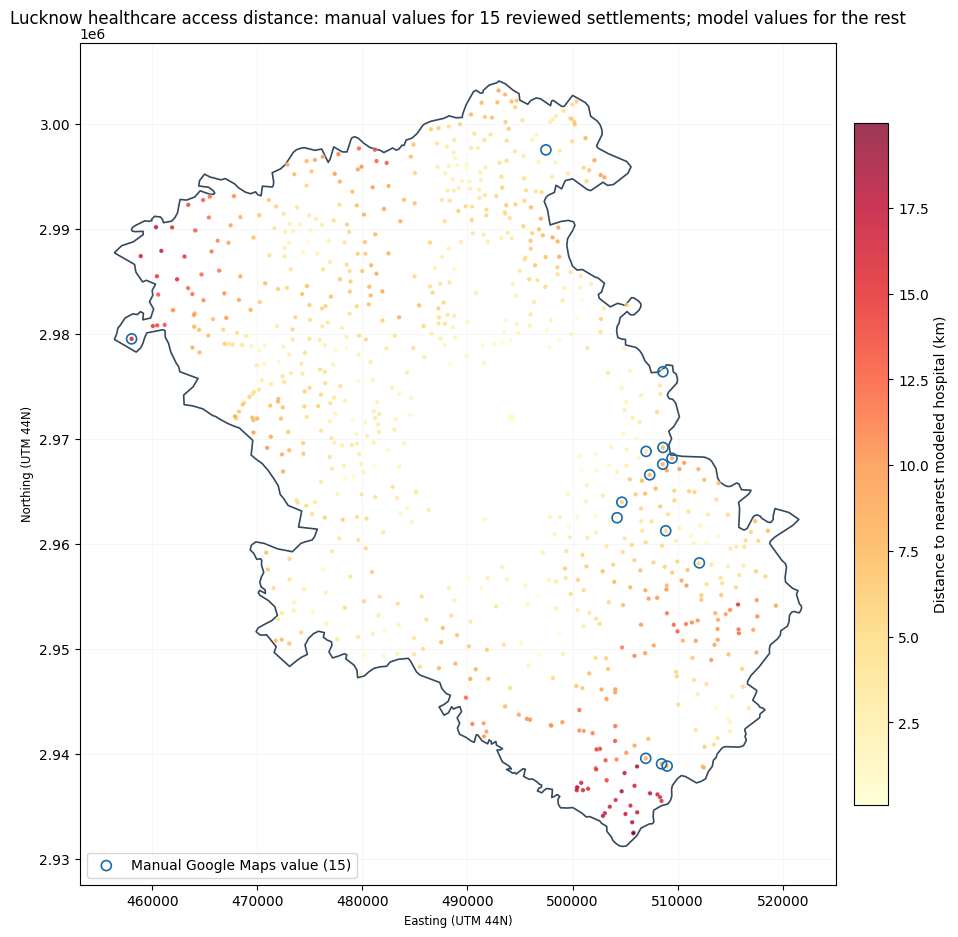

Mapped settlement points: 818 | manually reviewed points: 15
Saved separate map: /content/gdrive/MyDrive/lucknow_census_processed/lucknow_healthcare_access_blended_manual_v1_map.png


In [ ]:
import geopandas as gpd
import matplotlib.pyplot as plt
import numpy as np

map_df = pd.read_csv(os.path.join(base, 'lucknow_settlement_distance_blended_manual_v1.csv'))
map_df['origin_x'] = pd.to_numeric(map_df['origin_x'], errors='coerce')
map_df['origin_y'] = pd.to_numeric(map_df['origin_y'], errors='coerce')
map_df['distance_for_next_analysis_km'] = pd.to_numeric(map_df['distance_for_next_analysis_km'], errors='coerce')
map_df['population_corrected'] = pd.to_numeric(map_df['population_corrected'], errors='coerce').fillna(0)
map_df = map_df.dropna(subset=['origin_x','origin_y','distance_for_next_analysis_km']).copy()
points = gpd.GeoDataFrame(map_df, geometry=gpd.points_from_xy(map_df['origin_x'], map_df['origin_y']), crs='EPSG:32644')
boundary = gpd.read_file(os.path.join(base, 'lucknow_district_analytical.gpkg'), layer='district_boundary_2011').to_crs(points.crs)
manual_points = points[points['distance_for_next_analysis_source'].eq('manual_google_maps_value')]
fig, ax = plt.subplots(figsize=(10, 10))
boundary.boundary.plot(ax=ax, color='#34495e', linewidth=1.2, zorder=1)
size = 10 + 24 * np.sqrt(points['population_corrected'] / max(points['population_corrected'].max(), 1))
sc = ax.scatter(points.geometry.x, points.geometry.y, c=points['distance_for_next_analysis_km'], s=size, cmap='YlOrRd', alpha=0.78, edgecolors='white', linewidths=0.25, zorder=2)
ax.scatter(manual_points.geometry.x, manual_points.geometry.y, s=52, facecolors='none', edgecolors='#1769aa', linewidths=1.2, label='Manual Google Maps value (15)', zorder=3)
cb = fig.colorbar(sc, ax=ax, shrink=0.72, pad=0.02)
cb.set_label('Distance to nearest modeled hospital (km)')
ax.set_title('Lucknow healthcare access distance: manual values for 15 reviewed settlements; model values for the rest', fontsize=12, pad=14)
ax.set_xlabel('Easting (UTM 44N)')
ax.set_ylabel('Northing (UTM 44N)')
ax.set_aspect('equal')
ax.legend(loc='lower left', frameon=True)
ax.grid(alpha=0.15, linewidth=0.5)
plt.tight_layout()
map_path = os.path.join(base, 'lucknow_healthcare_access_blended_manual_v1_map.png')
plt.savefig(map_path, dpi=220, bbox_inches='tight')
plt.show()
print('Mapped settlement points:', len(points), '| manually reviewed points:', len(manual_points))
print('Saved separate map:', map_path)

Scenario comparison: top 10 for each method

Distance only


,tv_name,tehsil_name,population_corrected,distance_for_next_analysis_km,distance_for_next_analysis_source,distance_only_rank
0,Nadauli,Mohanlalganj,1511.0,19.988,model_road_distance,1.0
1,Khuddi Khera,Mohanlalganj,488.0,19.960,model_road_distance,2.0
2,Karan Pur,Mohanlalganj,1464.0,19.227,model_road_distance,3.0
3,Bhagwan Pur,Mohanlalganj,1331.0,19.023,model_road_distance,4.0
4,Puraheya,Mohanlalganj,2113.0,18.664,model_road_distance,5.0
5,Bairisal Pur,Mohanlalganj,1840.0,17.820,model_road_distance,6.0
6,Adhaeya,Mohanlalganj,1056.0,17.784,model_road_distance,7.0
7,Bhatwara,Mohanlalganj,603.0,17.575,model_road_distance,8.0
8,Ramdas Pur,Mohanlalganj,1375.0,17.570,model_road_distance,9.0
9,Ratana Pur,Mohanlalganj,909.0,17.502,model_road_distance,10.0



Population x distance exposure


,tv_name,tehsil_name,population_corrected,distance_for_next_analysis_km,distance_for_next_analysis_source,exposure_rank
0,Lucknow,Lucknow (Sadar),2817105.0,0.835,model_road_distance,1.0
1,Jindaur,Malihabad,12323.0,10.525,model_road_distance,2.0
2,Saspan,Malihabad,8378.0,12.776,model_road_distance,3.0
3,Bakshi Ka Talab,Bakshi Ka Talab,49166.0,2.141,model_road_distance,4.0
4,Utrawan,Mohanlalganj,8316.0,11.717,model_road_distance,5.0
5,Nigoha,Mohanlalganj,6474.0,14.202,model_road_distance,6.0
6,Natauli,Mohanlalganj,5380.0,16.844,model_road_distance,7.0
7,Dayal Pur,Mohanlalganj,4877.0,16.516,model_road_distance,8.0
8,Rusena,Malihabad,4615.0,17.307,model_road_distance,9.0
9,Kankaha,Mohanlalganj,6460.0,11.912,model_road_distance,10.0



Balanced equal-weight percentiles


,tv_name,tehsil_name,population_corrected,distance_for_next_analysis_km,distance_for_next_analysis_source,balanced_priority_rank
0,Natauli,Mohanlalganj,5380.0,16.844,model_road_distance,1.0
1,Nigoha,Mohanlalganj,6474.0,14.202,model_road_distance,2.0
2,Saspan,Malihabad,8378.0,12.776,model_road_distance,3.0
3,Rusena,Malihabad,4615.0,17.307,model_road_distance,4.0
4,Dayal Pur,Mohanlalganj,4877.0,16.516,model_road_distance,5.0
5,Utrawan,Mohanlalganj,8316.0,11.717,model_road_distance,6.0
6,Jindaur,Malihabad,12323.0,10.525,model_road_distance,7.0
7,Mavai Kalan,Malihabad,4433.0,16.700,manual_google_maps_value,8.0
8,Kankaha,Mohanlalganj,6460.0,11.912,model_road_distance,9.0
9,Sirsa,Mohanlalganj,4173.0,14.428,model_road_distance,10.0


Rankings saved: /content/gdrive/MyDrive/lucknow_census_processed/lucknow_priority_scenario_comparison_manual_blend_v1.csv
Balanced top-decile settlements: 82 of 819 | population: 306883
Tehsil summary for balanced ranking:


,tehsil_name,settlements,balanced_top_decile,median_distance_km,population
0,Mohanlalganj,232,41,7.44,480523.0
1,Malihabad,188,32,6.04,368453.0
2,Lucknow (Sadar),210,6,3.42,3391208.0
3,Bakshi Ka Talab,189,3,4.52,349654.0


/usr/local/lib/python3.13/dist-packages/pyogrio/raw.py:200: RuntimeWarning: Table/view villages_towns_2011_corrected is referenced in gpkg_contents, but does not exist
  return ogr_read(


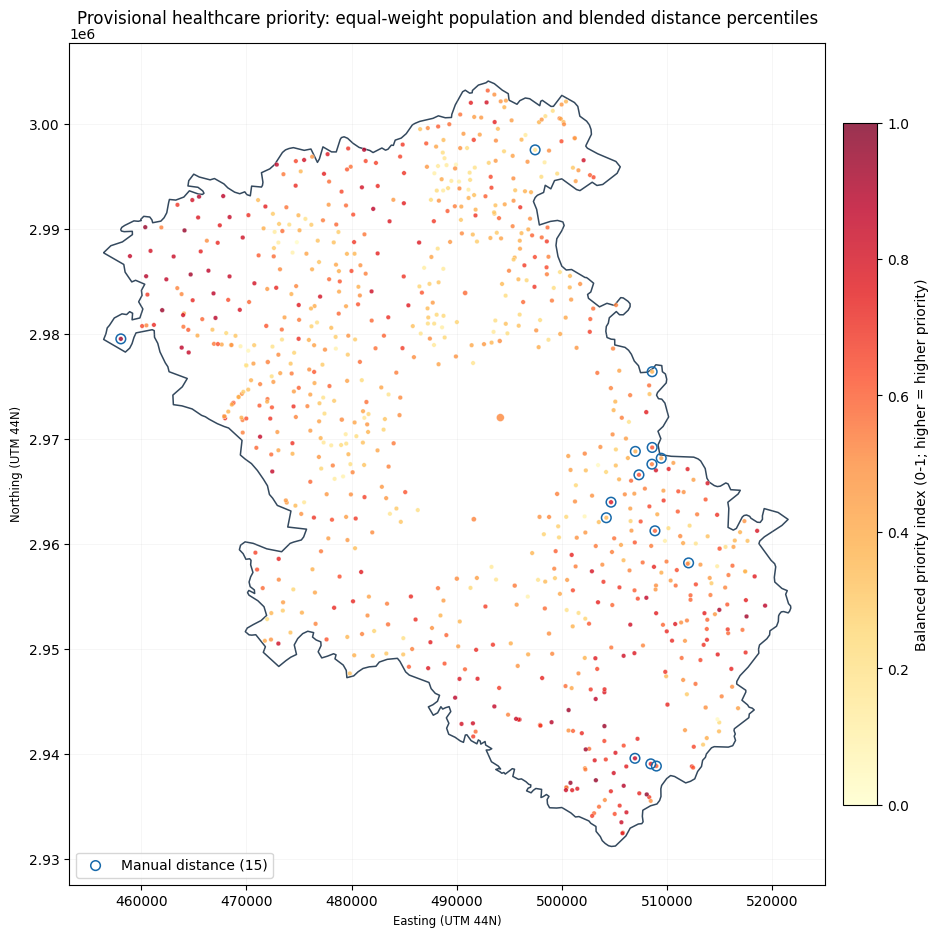

Mapped points: 818 | manually reviewed: 15
Provisional balanced map saved: /content/gdrive/MyDrive/lucknow_census_processed/lucknow_provisional_balanced_priority_manual_blend_v1_map.png
Original priority_score_v1 and priority_tier_v1 remain unchanged.


In [ ]:
import pandas as pd, os, numpy as np, geopandas as gpd, matplotlib.pyplot as plt
base = '/content/gdrive/MyDrive/lucknow_census_processed'
rank = pd.read_csv(os.path.join(base, 'lucknow_settlement_distance_blended_manual_v1.csv'))
for c in ['priority_score_v1','population_corrected','distance_for_next_analysis_km','origin_x','origin_y']:
    rank[c] = pd.to_numeric(rank[c], errors='coerce')
rank['original_v1_rank'] = rank['priority_score_v1'].rank(ascending=False, method='min')
rank['distance_only_rank'] = rank['distance_for_next_analysis_km'].rank(ascending=False, method='min')
rank['population_distance_exposure'] = rank['population_corrected'] * rank['distance_for_next_analysis_km']
rank['exposure_rank'] = rank['population_distance_exposure'].rank(ascending=False, method='min')
rank['population_percentile'] = rank['population_corrected'].rank(pct=True)
rank['distance_percentile'] = rank['distance_for_next_analysis_km'].rank(pct=True)
rank['balanced_priority_index'] = (rank['population_percentile'] + rank['distance_percentile']) / 2
rank['balanced_priority_rank'] = rank['balanced_priority_index'].rank(ascending=False, method='min')

print('Scenario comparison: top 10 for each method')
for label, col in [('Distance only','distance_only_rank'),('Population x distance exposure','exposure_rank'),('Balanced equal-weight percentiles','balanced_priority_rank')]:
    print('\n' + label)
    display(rank.sort_values(col).head(10)[['tv_name','tehsil_name','population_corrected','distance_for_next_analysis_km','distance_for_next_analysis_source',col]].round(3).reset_index(drop=True))

rank['priority_scenario'] = 'balanced_equal_weight_percentiles'
rank_path = os.path.join(base, 'lucknow_priority_scenario_comparison_manual_blend_v1.csv')
rank.to_csv(rank_path, index=False)
print('Rankings saved:', rank_path)

# Provisional summary: counts in the most urgent decile under balanced ranking.
cutoff = int(np.ceil(len(rank) * 0.10))
top_decile = rank[rank['balanced_priority_rank'] <= cutoff]
print('Balanced top-decile settlements:', len(top_decile), 'of', len(rank), '| population:', int(top_decile['population_corrected'].sum()))
by_tehsil = rank.groupby('tehsil_name').agg(settlements=('tv_name','count'), balanced_top_decile=('balanced_priority_rank', lambda s: int((s <= cutoff).sum())), median_distance_km=('distance_for_next_analysis_km','median'), population=('population_corrected','sum')).reset_index().sort_values(['balanced_top_decile','median_distance_km'], ascending=False)
print('Tehsil summary for balanced ranking:')
display(by_tehsil.round(2).reset_index(drop=True))

# Map settlement access locations by balanced index; blue outline denotes manually reviewed values.
map_df = rank.dropna(subset=['origin_x','origin_y','balanced_priority_index']).copy()
points = gpd.GeoDataFrame(map_df, geometry=gpd.points_from_xy(map_df['origin_x'], map_df['origin_y']), crs='EPSG:32644')
boundary = gpd.read_file(os.path.join(base, 'lucknow_district_analytical.gpkg'), layer='district_boundary_2011').to_crs(points.crs)
fig, ax = plt.subplots(figsize=(10,10))
boundary.boundary.plot(ax=ax, color='#34495e', linewidth=1.1, zorder=1)
size = 10 + 22*np.sqrt(points['population_corrected'].fillna(0) / max(points['population_corrected'].fillna(0).max(),1))
sc = ax.scatter(points.geometry.x, points.geometry.y, c=points['balanced_priority_index'], s=size, cmap='YlOrRd', vmin=0, vmax=1, alpha=0.8, edgecolors='white', linewidths=0.25, zorder=2)
manual = points[points['distance_for_next_analysis_source'].eq('manual_google_maps_value')]
ax.scatter(manual.geometry.x, manual.geometry.y, s=48, facecolors='none', edgecolors='#1769aa', linewidths=1.1, label='Manual distance (15)', zorder=3)
cb = fig.colorbar(sc, ax=ax, shrink=0.72, pad=0.02)
cb.set_label('Balanced priority index (0-1; higher = higher priority)')
ax.set_title('Provisional healthcare priority: equal-weight population and blended distance percentiles', fontsize=12, pad=14)
ax.set_xlabel('Easting (UTM 44N)'); ax.set_ylabel('Northing (UTM 44N)')
ax.set_aspect('equal'); ax.grid(alpha=0.15, linewidth=0.5); ax.legend(loc='lower left')
plt.tight_layout()
map_path = os.path.join(base, 'lucknow_provisional_balanced_priority_manual_blend_v1_map.png')
plt.savefig(map_path, dpi=220, bbox_inches='tight'); plt.show()
print('Mapped points:',len(points),'| manually reviewed:',len(manual))
print('Provisional balanced map saved:',map_path)
print('Original priority_score_v1 and priority_tier_v1 remain unchanged.')

In [ ]:
import os, ast, pandas as pd, numpy as np
base = "/content/gdrive/MyDrive/lucknow_census_processed"
rank_path = os.path.join(base, "lucknow_priority_scenario_comparison_manual_blend_v1.csv")
hospital_path = os.path.join(base, "lucknow_hospital_topology_snapping.csv")
rank = pd.read_csv(rank_path)
hosp = pd.read_csv(hospital_path)

# Resolve the nearest reachable facility name from the graph-node list.
node_to_names = {}
for _, h in hosp.iterrows():
    node = pd.to_numeric(h.get("nearest_graph_node"), errors="coerce")
    if pd.notna(node):
        node_to_names.setdefault(int(node), []).append(str(h.get("facility_name", "Unknown")))
def nearest_hospital_name(value):
    if pd.isna(value):
        return ""
    try:
        nodes = ast.literal_eval(value) if isinstance(value, str) else value
        if not isinstance(nodes, (list, tuple, set)):
            nodes = [nodes]
        for node in nodes:
            n = int(float(node))
            if n in node_to_names:
                return "; ".join(node_to_names[n][:3])
    except Exception:
        try:
            n = int(float(value))
            if n in node_to_names:
                return "; ".join(node_to_names[n][:3])
        except Exception:
            pass
    return "Name not matched"

rank["nearest_hospital_name"] = rank["nearest_hospital_graph_node"].apply(nearest_hospital_name) if "nearest_hospital_graph_node" in rank.columns else "Not available"
cutoff = int(np.ceil(len(rank) * 0.10))
shortlist = rank.loc[rank["balanced_priority_rank"] <= cutoff].copy()
shortlist["review_status"] = "Needs review"
shortlist["review_notes"] = ""
cols = [c for c in ["balanced_priority_rank", "balanced_priority_index", "pc11_tv_id", "tv_name", "tehsil_name", "population_corrected", "nearest_hospital_name", "nearest_hospital_distance_km", "distance_for_next_analysis_km", "distance_for_next_analysis_source", "priority_score_v1", "priority_tier_v1", "review_status", "review_notes"] if c in shortlist.columns]
shortlist = shortlist[cols].sort_values("balanced_priority_rank")
out_path = os.path.join(base, "lucknow_top_decile_balanced_priority_review_v1.csv")
shortlist.to_csv(out_path, index=False)
print(f"Saved separate review shortlist: {out_path}")
print(f"Rows: {len(shortlist)} of {len(rank)} | population represented: {int(shortlist['population_corrected'].sum()):,}")
print("Distance source counts:")
print(shortlist["distance_for_next_analysis_source"].value_counts(dropna=False).to_string())
print("\nFirst 25 rows:")
display(shortlist.head(25).round(3))
print("\nHospital-name match coverage:", (shortlist["nearest_hospital_name"] != "Name not matched").sum(), "of", len(shortlist))


Saved separate review shortlist: /content/gdrive/MyDrive/lucknow_census_processed/lucknow_top_decile_balanced_priority_review_v1.csv
Rows: 82 of 819 | population represented: 306,883
Distance source counts:
distance_for_next_analysis_source
model_road_distance         79
manual_google_maps_value     3

First 25 rows:


,balanced_priority_rank,balanced_priority_index,pc11_tv_id,tv_name,tehsil_name,population_corrected,nearest_hospital_name,nearest_hospital_distance_km,distance_for_next_analysis_km,distance_for_next_analysis_source,priority_score_v1,priority_tier_v1,review_status,review_notes
32,1.0,0.963,143788,Natauli,Mohanlalganj,5380.0,PHC Nagram,8.674,16.844,model_road_distance,72.377,High preliminary priority,Needs review,
18,2.0,0.957,143772,Nigoha,Mohanlalganj,6474.0,PHC Nagram,12.468,14.202,model_road_distance,86.738,Very high preliminary priority,Needs review,
355,3.0,0.957,142986,Saspan,Malihabad,8378.0,CHC Mall,10.244,12.776,model_road_distance,78.319,Very high preliminary priority,Needs review,
346,4.0,0.954,143068,Rusena,Malihabad,4615.0,CHC Mall,14.105,17.307,model_road_distance,92.937,Very high preliminary priority,Needs review,
803,5.0,0.951,143737,Dayal Pur,Mohanlalganj,4877.0,PHC Nagram,11.525,16.516,model_road_distance,83.172,Very high preliminary priority,Needs review,
49,6.0,0.949,143747,Utrawan,Mohanlalganj,8316.0,CHC Mohanlalganj,9.667,11.717,model_road_distance,76.135,Very high preliminary priority,Needs review,
342,7.0,0.946,143074,Jindaur,Malihabad,12323.0,CHC Malihabad,10.200,10.525,model_road_distance,78.156,Very high preliminary priority,Needs review,
306,8.0,0.944,143075,Mavai Kalan,Malihabad,4433.0,CHC Malihabad,12.656,16.700,manual_google_maps_value,87.451,Very high preliminary priority,Needs review,
782,9.0,0.943,143731,Kankaha,Mohanlalganj,6460.0,CHC Mohanlalganj,7.136,11.912,model_road_distance,66.555,High preliminary priority,Needs review,
806,10.0,0.929,143739,Sirsa,Mohanlalganj,4173.0,PHC Nagram,10.635,14.428,model_road_distance,79.802,Very high preliminary priority,Needs review,



Hospital-name match coverage: 82 of 82


In [ ]:
import os
base = "/content/gdrive/MyDrive/lucknow_census_processed"
print("Likely website/data outputs in project folder:")
for name in sorted(os.listdir(base)):
    low = name.lower()
    if any(k in low for k in ["website", "web", "site", "settlement", "priority", "accessible", "distance"]):
        print(name)


Likely website/data outputs in project folder:
hospital_settlement_spatial_join_audit.csv
lucknow_distance_threshold_sensitivity.csv
lucknow_district_priority_score_map.png
lucknow_manual_distance_verification_queue.csv
lucknow_manual_distance_verification_queue.gsheet
lucknow_priority_investigation_list_5km.csv
lucknow_priority_map_with_hospitals.png
lucknow_priority_population_exposure.csv
lucknow_priority_ranking_comparison_manual_blend_v1.csv
lucknow_priority_scenario_comparison_manual_blend_v1.csv
lucknow_priority_sensitivity_analysis.csv
lucknow_priority_threshold_tehsil_summary.csv
lucknow_provisional_balanced_priority_manual_blend_v1_map.png
lucknow_settlement_access_indicators_v1.csv
lucknow_settlement_distance_blended_manual_v1.csv
lucknow_settlement_graph_snapping.csv
lucknow_settlement_healthcare_indicators_v1.csv
lucknow_settlement_healthcare_indicators_v2.csv
lucknow_settlement_healthcare_indicators_v3.csv
lucknow_settlement_healthcare_integrated.csv
lucknow_settlement_he

In [ ]:
import os, pandas as pd
base = "/content/gdrive/MyDrive/lucknow_census_processed"
for name in sorted(os.listdir(base)):
    if name.lower().endswith(".csv") and any(k in name.lower() for k in ["settlement_healthcare", "settlement_access", "integrated", "priority_scores", "priority_mapping"]):
        try:
            df = pd.read_csv(os.path.join(base, name), nrows=2)
            cols = df.columns.tolist()
            dist = [c for c in cols if "distance" in c.lower()]
            print(f"{name} | columns={len(cols)} | rows(sample)={len(df)} | distance_cols={dist}")
        except Exception as e:
            print(name, "READ ERROR", e)


lucknow_settlement_access_indicators_v1.csv | columns=62 | rows(sample)=2 | distance_cols=['nearest_hospital_distance_km', 'distance_band']
lucknow_settlement_healthcare_indicators_v1.csv | columns=40 | rows(sample)=2 | distance_cols=[]
lucknow_settlement_healthcare_indicators_v2.csv | columns=43 | rows(sample)=2 | distance_cols=[]
lucknow_settlement_healthcare_indicators_v3.csv | columns=49 | rows(sample)=2 | distance_cols=[]
lucknow_settlement_healthcare_integrated.csv | columns=20 | rows(sample)=2 | distance_cols=[]
lucknow_settlement_healthcare_integrated_popcorrected.csv | columns=22 | rows(sample)=2 | distance_cols=[]
lucknow_settlement_healthcare_integrated_popcorrected_v2.csv | columns=23 | rows(sample)=2 | distance_cols=[]
lucknow_settlement_priority_scores_v1.csv | columns=74 | rows(sample)=2 | distance_cols=['nearest_hospital_distance_km', 'distance_band', 'distance_score']
lucknow_urban_healthcare_priority_scores.csv | columns=17 | rows(sample)=2 | distance_cols=['nearest_h

In [ ]:
import os, pandas as pd
base = "/content/gdrive/MyDrive/lucknow_census_processed"
for name in ["lucknow_settlement_access_indicators_v1.csv", "lucknow_settlement_priority_scores_v1.csv"]:
    df = pd.read_csv(os.path.join(base, name))
    print("\n", name, "shape", df.shape)
    print("keys:", [c for c in df.columns if "id" in c.lower() or "name" in c.lower()])
    print("distance/score/tier fields:", [c for c in df.columns if any(k in c.lower() for k in ["distance", "score", "tier", "priority"])])
    print(df.head(2).to_string(index=False, max_cols=15))



 lucknow_settlement_access_indicators_v1.csv shape (819, 62)
keys: ['pc11_tv_id', 'tv_name', 'tehsil_name', 'nearest_hospital_name', 'tv_name_indicator', 'tehsil_name_indicator', 'population_valid_for_rate', 'population_valid_for_access_rate']
distance/score/tier fields: ['nearest_hospital_distance_km', 'distance_band']
 pc11_tv_id tv_name  tehsil_name  is_town  nearest_hospital_distance_km   nearest_hospital_record_key nearest_hospital_name  ... population_below_500_flag  small_population_rate_caution distance_band no_local_hospital_record  no_local_public_hospital_record  preliminary_access_concern  population_valid_for_access_rate
     143753  Nagram Mohanlalganj    False                      2.044840 phc nagram||26.61872|81.14043            PHC Nagram  ...                     False                          False       >2–5 km                     True                             True                       False                              True
     143754 Karorwa Mohanlalganj    F

In [ ]:
import os, pandas as pd
base = "/content/gdrive/MyDrive/lucknow_census_processed"
df = pd.read_csv(os.path.join(base, "lucknow_settlement_access_indicators_v1.csv"))
print(df["distance_band"].value_counts(dropna=False).to_string())
print("\nAccess indicator has website distance rows:", len(df), "unique settlement IDs:", df["pc11_tv_id"].nunique())


distance_band
>2–5 km     368
>5–10 km    218
0–2 km      183
>10 km       50

Access indicator has website distance rows: 819 unique settlement IDs: 819


In [ ]:
import os, pandas as pd, numpy as np
base = "/content/gdrive/MyDrive/lucknow_census_processed"
website_path = os.path.join(base, "lucknow_settlement_access_indicators_v1.csv")
blend_path = os.path.join(base, "lucknow_settlement_distance_blended_manual_v1.csv")
access = pd.read_csv(website_path)
blend = pd.read_csv(blend_path)

# Join by settlement ID; preserve the existing website schema and its distance field name.
assert access["pc11_tv_id"].is_unique and blend["pc11_tv_id"].is_unique
assert set(access["pc11_tv_id"]) == set(blend["pc11_tv_id"]), "Settlement IDs do not match; no file written."
updates = blend[["pc11_tv_id", "distance_for_next_analysis_km", "distance_for_next_analysis_source", "road_distance_km"]].copy()
updates = updates.rename(columns={
    "distance_for_next_analysis_km": "website_distance_km",
    "distance_for_next_analysis_source": "website_distance_source",
    "road_distance_km": "osm_road_distance_km"
})
website = access.drop(columns=["website_distance_km", "website_distance_source", "osm_road_distance_km"], errors="ignore").merge(updates, on="pc11_tv_id", how="left", validate="one_to_one")
website["nearest_hospital_distance_km"] = website["website_distance_km"]
website["distance_band"] = pd.cut(
    website["nearest_hospital_distance_km"],
    bins=[-np.inf, 2, 5, 10, np.inf],
    labels=["0–2 km", ">2–5 km", ">5–10 km", ">10 km"],
    right=True
).astype("object")
assert website["nearest_hospital_distance_km"].notna().all()
assert len(website) == 819
out_path = os.path.join(base, "lucknow_settlement_access_indicators_osm_v1.csv")
website.to_csv(out_path, index=False)
print("Website-ready access data saved:", out_path)
print("Rows:", len(website), "| unique settlements:", website["pc11_tv_id"].nunique())
print("Replaced nearest_hospital_distance_km with the blended verified/manual + OSM road distance field.")
print("Distance sources:")
print(website["website_distance_source"].value_counts(dropna=False).to_string())
print("\nUpdated distance bands:")
print(website["distance_band"].value_counts().to_string())
print("\nDistance summary (km):")
print(website["nearest_hospital_distance_km"].describe().round(2).to_string())
print("\nPreview:")
display(website[["pc11_tv_id", "tv_name", "nearest_hospital_name", "nearest_hospital_distance_km", "website_distance_source", "osm_road_distance_km", "distance_band"]].head(10).round(3))
print("\nOriginal file preserved:", os.path.exists(website_path), "| versioned output separate:", out_path != website_path)


AssertionError: 

In [ ]:
import os, pandas as pd
base = "/content/gdrive/MyDrive/lucknow_census_processed"
b = pd.read_csv(os.path.join(base, "lucknow_settlement_distance_blended_manual_v1.csv"))
print("Blended shape:", b.shape)
print("Relevant columns:", [c for c in b.columns if "distance" in c.lower() or "source" in c.lower()])
print("Null counts:")
print(b[[c for c in ["pc11_tv_id", "distance_for_next_analysis_km", "distance_for_next_analysis_source", "road_distance_km"] if c in b.columns]].isna().sum().to_string())
print("Missing distance rows:")
print(b.loc[b["distance_for_next_analysis_km"].isna(), [c for c in ["pc11_tv_id", "tv_name", "road_distance_km", "distance_for_next_analysis_km", "distance_for_next_analysis_source"] if c in b.columns]].head(30).to_string(index=False))


Blended shape: (819, 22)
Relevant columns: ['nearest_hospital_distance_km', 'representative_to_road_distance_m', 'snap_distance_m', 'road_distance_m', 'road_distance_km', 'distance_difference_km', 'distance_for_next_analysis_km', 'distance_for_next_analysis_source']
Null counts:
pc11_tv_id                           0
distance_for_next_analysis_km        1
distance_for_next_analysis_source    0
road_distance_km                     1
Missing distance rows:
 pc11_tv_id   tv_name  road_distance_km  distance_for_next_analysis_km distance_for_next_analysis_source
     143406 Jaliyamau               NaN                            NaN               model_road_distance


In [ ]:
import os, pandas as pd, numpy as np
base = "/content/gdrive/MyDrive/lucknow_census_processed"
website_path = os.path.join(base, "lucknow_settlement_access_indicators_v1.csv")
blend_path = os.path.join(base, "lucknow_settlement_distance_blended_manual_v1.csv")
access = pd.read_csv(website_path)
blend = pd.read_csv(blend_path)
assert access["pc11_tv_id"].is_unique and blend["pc11_tv_id"].is_unique
assert set(access["pc11_tv_id"]) == set(blend["pc11_tv_id"]), "Settlement IDs do not match; no file written."
updates = blend[["pc11_tv_id", "distance_for_next_analysis_km", "distance_for_next_analysis_source", "road_distance_km"]].copy()
updates = updates.rename(columns={
    "distance_for_next_analysis_km": "website_distance_km",
    "distance_for_next_analysis_source": "website_distance_source",
    "road_distance_km": "osm_road_distance_km"
})
website = access.drop(columns=["website_distance_km", "website_distance_source", "osm_road_distance_km"], errors="ignore").merge(updates, on="pc11_tv_id", how="left", validate="one_to_one")
missing = website["website_distance_km"].isna()
website["nearest_hospital_distance_km_straight_line_previous"] = website["nearest_hospital_distance_km"]
# Preserve the prior straight-line value only where the road graph has no route.
website.loc[missing, "website_distance_km"] = website.loc[missing, "nearest_hospital_distance_km"]
website.loc[missing, "website_distance_source"] = "straight_line_fallback_no_osm_route"
website["nearest_hospital_distance_km"] = website["website_distance_km"]
website["distance_band"] = pd.cut(
    website["nearest_hospital_distance_km"],
    bins=[-np.inf, 2, 5, 10, np.inf],
    labels=["0–2 km", ">2–5 km", ">5–10 km", ">10 km"],
    right=True
).astype("object")
assert website["nearest_hospital_distance_km"].notna().all() and len(website) == 819
out_path = os.path.join(base, "lucknow_settlement_access_indicators_osm_v1.csv")
website.to_csv(out_path, index=False)
print("Website-ready data saved:", out_path)
print("Rows:", len(website), "| unique settlements:", website["pc11_tv_id"].nunique())
print("Distance source counts:")
print(website["website_distance_source"].value_counts(dropna=False).to_string())
print("Updated distance bands:")
print(website["distance_band"].value_counts().to_string())
print("\nDistance summary (km):")
print(website["nearest_hospital_distance_km"].describe().round(2).to_string())
print("\nFallback row(s):")
display(website.loc[missing, ["pc11_tv_id", "tv_name", "nearest_hospital_name", "nearest_hospital_distance_km_straight_line_previous", "nearest_hospital_distance_km", "website_distance_source"]])
print("\nPreview:")
display(website[["pc11_tv_id", "tv_name", "nearest_hospital_name", "nearest_hospital_distance_km", "website_distance_source", "osm_road_distance_km", "distance_band"]].head(10).round(3))
print("\nOriginal access-indicator CSV preserved:", os.path.exists(website_path))


Website-ready data saved: /content/gdrive/MyDrive/lucknow_census_processed/lucknow_settlement_access_indicators_osm_v1.csv
Rows: 819 | unique settlements: 819
Distance source counts:
website_distance_source
model_road_distance                    803
manual_google_maps_value                15
straight_line_fallback_no_osm_route      1
Updated distance bands:
distance_band
>5–10 km    334
>2–5 km     284
>10 km      103
0–2 km       98

Distance summary (km):
count    819.00
mean       5.91
std        3.82
min        0.09
25%        3.06
50%        5.26
75%        7.80
max       19.99

Fallback row(s):


,pc11_tv_id,tv_name,nearest_hospital_name,nearest_hospital_distance_km_straight_line_previous,nearest_hospital_distance_km,website_distance_source
259,143406,Jaliyamau,S F HOSPITAL,4.082478,4.082478,straight_line_fallback_no_osm_route



Preview:


,pc11_tv_id,tv_name,nearest_hospital_name,nearest_hospital_distance_km,website_distance_source,osm_road_distance_km,distance_band
0,143753,Nagram,PHC Nagram,2.464,model_road_distance,2.464,>2–5 km
1,143754,Karorwa,PHC Nagram,5.479,model_road_distance,5.479,>5–10 km
2,143756,Aslam Nagar,PHC Nagram,1.850,model_road_distance,1.850,0–2 km
3,800955,Nagram,PHC Nagram,0.386,model_road_distance,0.386,0–2 km
4,143757,Katra Nagram,PHC Nagram,1.517,model_road_distance,1.517,0–2 km
5,143758,Abbas Nagar,PHC Nagram,4.562,model_road_distance,4.562,>2–5 km
6,143759,Garna,PHC Nagram,2.743,model_road_distance,2.743,>2–5 km
7,143755,Amba Muratajapur,PHC Nagram,3.937,model_road_distance,3.937,>2–5 km
8,143782,Khuddi Khera,PHC Nagram,19.960,model_road_distance,19.960,>10 km
9,143784,Dakhena Sekhpur,PHC Nagram,17.419,model_road_distance,17.419,>10 km



Original access-indicator CSV preserved: True


In [ ]:
import os, pandas as pd
base = "/content/gdrive/MyDrive/lucknow_census_processed"
for n in sorted(os.listdir(base)):
    if "dashboard" in n.lower() or "website" in n.lower():
        print(n)
p = os.path.join(base, "lucknow_healthcare_dashboard_data.csv")
print("expected dashboard CSV exists:", os.path.exists(p))
if os.path.exists(p):
    d = pd.read_csv(p)
    print("shape", d.shape)
    print("columns", d.columns.tolist())
    print(d.head(3).to_string(index=False))


lucknow_healthcare_dashboard_data.csv
expected dashboard CSV exists: True
shape (819, 32)
columns ['settlement_code', 'settlement_name', 'tehsil', 'settlement_type', 'is_town', 'population_2011', 'area_km2', 'hospital_record_count', 'public_hospital_records', 'private_hospital_records', 'total_reported_beds', 'public_reported_beds', 'private_reported_beds', 'nearest_hospital_distance_km', 'nearest_hospital_name', 'nearest_hospital_ownership', 'nearest_hospital_beds', 'beds_per_1000_population', 'hospital_records_per_10000_population', 'has_public_hospital_record', 'has_private_hospital_record', 'priority_score', 'priority_rank', 'priority_tier', 'investigation_flag_5km', 'Primary Health Centre (Numbers)', 'Community Health Centre (Numbers)', 'Primary Heallth Sub Centre (Numbers)', 'Hospital Allopathic (Numbers)', 'census_healthcare_missing_count', 'population_zero_flag', 'small_population_rate_caution']
 settlement_code settlement_name       tehsil settlement_type  is_town  population_

In [ ]:
import os, pandas as pd, numpy as np
base = "/content/gdrive/MyDrive/lucknow_census_processed"
d = pd.read_csv(os.path.join(base, "lucknow_healthcare_dashboard_data.csv"))
p = pd.read_csv(os.path.join(base, "lucknow_settlement_priority_scores_v1.csv"))
cols = [c for c in p.columns if "score" in c.lower() or "gap" in c.lower()]
print("Priority source formula fields:", cols)
print(p[cols + ["priority_score_v1"]].head(5).to_string(index=False))
if "distance_score" in p.columns and "local_hospital_gap_score" in p.columns:
    candidate = 0.6*p["distance_score"] + 0.4*p["local_hospital_gap_score"]
    print("\nCandidate 60/40 formula max abs difference:", (candidate-p["priority_score_v1"]).abs().max())
print("\nDashboard score vs source priority score max abs difference:", (d["priority_score"]-p["priority_score_v1"]).abs().max())
print("\nFlag definition columns:", [c for c in d.columns if "hospital" in c.lower() or "flag" in c.lower()])
print("\nOriginal flag counts:", d["investigation_flag_5km"].value_counts(dropna=False).to_dict())


Priority source formula fields: ['distance_score', 'local_hospital_gap_score', 'public_hospital_gap_score', 'phc_gap', 'chc_gap', 'subcentre_gap', 'historical_primary_care_gap_score', 'historical_primary_care_score_unavailable', 'priority_score_v1']
 distance_score  local_hospital_gap_score  public_hospital_gap_score  phc_gap  chc_gap  subcentre_gap  historical_primary_care_gap_score  historical_primary_care_score_unavailable  priority_score_v1  priority_score_v1
     100.000000                       100                      100.0    100.0    100.0          100.0                              100.0                                      False         100.000000         100.000000
      95.627731                       100                      100.0    100.0    100.0          100.0                              100.0                                      False          97.376638          97.376638
      94.787691                       100                      100.0    100.0    100.0          

In [ ]:
dist = pd.to_numeric(d["nearest_hospital_distance_km"], errors="coerce")
for mode, score_dist in [("max scaled", dist / dist.max() * 100), ("min-max scaled", (dist-dist.min())/(dist.max()-dist.min())*100), ("rank percentile", dist.rank(pct=True)*100)]:
    formula = 0.6*score_dist + 40*d["hospital_record_count"].eq(0).astype(float)
    print(mode, "max abs error", round((formula-d["priority_score"]).abs().max(), 6), "mean abs error", round((formula-d["priority_score"]).abs().mean(), 6))
print("distance min/max", dist.min(), dist.max())


max scaled max abs error 0.453349 mean abs error 0.333301
min-max scaled max abs error 0.0 mean abs error 0.0
rank percentile max abs error 24.444292 mean abs error 14.164707
distance min/max 0.1206742544995477 15.97104236429598


In [ ]:
d["nearest_hospital_distance_km"] = pd.to_numeric(d["nearest_hospital_distance_km"], errors="coerce")
calc_flag = d["nearest_hospital_distance_km"].gt(5) & d["hospital_record_count"].eq(0)
print("Flag exact match old straight-line rule:", (calc_flag == d["investigation_flag_5km"]).all())
print("Score ranges by existing tier:")
print(d.groupby("priority_tier", dropna=False)["priority_score"].agg(["min","max","count"]).to_string())
print("\nScore unique rounded:", sorted(d["priority_score"].round(2).unique())[:15])


Flag exact match old straight-line rule: True
Score ranges by existing tier:
                                      min         max  count
priority_tier                                               
High preliminary priority       50.021640   74.921589    470
Lower preliminary priority       0.000000    7.486271     52
Moderate preliminary priority   41.255165   49.967884    239
Very high preliminary priority  75.141733  100.000000     58

Score unique rounded: [np.float64(0.0), np.float64(0.22), np.float64(0.31), np.float64(0.68), np.float64(0.73), np.float64(0.75), np.float64(0.82), np.float64(0.87), np.float64(0.93), np.float64(1.01), np.float64(1.32), np.float64(1.4), np.float64(1.51), np.float64(1.58), np.float64(1.63)]


In [ ]:
import os, pandas as pd
p = "/content/gdrive/MyDrive/lucknow_census_processed/lucknow_healthcare_dashboard_data.csv"
t = pd.read_csv(p)
print("Updated dashboard file exists:", os.path.exists(p), "shape:", t.shape)
print("priority rank fields:", [c for c in t.columns if "rank" in c])
print("source counts:", t["website_distance_source"].value_counts(dropna=False).to_dict())
print("null distance:", int(t["nearest_hospital_distance_km"].isna().sum()))
print(t[["settlement_code", "settlement_name", "nearest_hospital_distance_km", "priority_score", "priority_rank", "priority_tier", "investigation_flag_5km"]].head(3).to_string(index=False))


Updated dashboard file exists: True shape: (819, 35)
priority rank fields: ['priority_rank']
source counts: {'model_road_distance': 803, 'manual_google_maps_value': 15, 'straight_line_fallback_no_osm_route': 1}
null distance: 0
 settlement_code settlement_name  nearest_hospital_distance_km  priority_score  priority_rank                 priority_tier  investigation_flag_5km
          143753          Nagram                      2.464379       47.147549            672 Moderate preliminary priority                   False
          143754         Karorwa                      5.479220       56.240762            385     High preliminary priority                    True
          143756     Aslam Nagar                      1.849568       45.293187            720 Moderate preliminary priority                   False


In [ ]:
from google.colab import files
files.download("/content/gdrive/MyDrive/lucknow_census_processed/lucknow_healthcare_dashboard_data.csv")


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

In [ ]:
from IPython.display import FileLink, display
display(FileLink("/content/gdrive/MyDrive/lucknow_census_processed/lucknow_healthcare_dashboard_data.csv"))


/content/gdrive/MyDrive/lucknow_census_processed/lucknow_healthcare_dashboard_data.csv

In [ ]:
import os
base = "/content/gdrive/MyDrive/lucknow_census_processed"
required = [
    "lucknow_healthcare_dashboard_data.csv",
    "lucknow_settlement_priority_mapping_popcorrected.gpkg",
    "lucknow_hospital_master_cleaned.csv",
    "lucknow_urban_ward_healthcare_summary.csv",
    "lucknow_map_boundaries_with_demographics.gpkg",
    "lucknow_urban_healthcare_priority_scores_model_b.csv",
    "lucknow_urban_hospital_assignments.csv",
]
for name in required:
    p = os.path.join(base, name)
    print(f"{name}: {'FOUND' if os.path.isfile(p) else 'MISSING'}" + (f" ({os.path.getsize(p)/1024/1024:.2f} MB)" if os.path.isfile(p) else ""))


lucknow_healthcare_dashboard_data.csv: FOUND (0.23 MB)
lucknow_settlement_priority_mapping_popcorrected.gpkg: FOUND (1.75 MB)
lucknow_hospital_master_cleaned.csv: FOUND (0.08 MB)
lucknow_urban_ward_healthcare_summary.csv: FOUND (0.01 MB)
lucknow_map_boundaries_with_demographics.gpkg: FOUND (0.28 MB)
lucknow_urban_healthcare_priority_scores_model_b.csv: FOUND (0.02 MB)
lucknow_urban_hospital_assignments.csv: FOUND (0.09 MB)


In [ ]:
from google.colab import files
uploaded = files.upload()
print('Uploaded:', list(uploaded))


Saving lucknow_healthcare_website_osm_update.zip to lucknow_healthcare_website_osm_update.zip
Uploaded: ['lucknow_healthcare_website_osm_update.zip']


In [ ]:
import os, shutil, zipfile, tempfile
from pathlib import Path
b=Path('/content/gdrive/MyDrive/lucknow_census_processed')
src=Path('/content/lucknow_healthcare_website_osm_update.zip')
names=['lucknow_healthcare_dashboard_data.csv','lucknow_settlement_priority_mapping_popcorrected.gpkg','lucknow_hospital_master_cleaned.csv','lucknow_urban_ward_healthcare_summary.csv','lucknow_map_boundaries_with_demographics.gpkg','lucknow_urban_healthcare_priority_scores_model_b.csv','lucknow_urban_hospital_assignments.csv']
assert src.is_file() and all((b/n).is_file() for n in names)
w=Path(tempfile.mkdtemp()); site=w/'lucknow_healthcare_website'; site.mkdir()
with zipfile.ZipFile(src) as z:
    assert all(not Path(n).is_absolute() and '..' not in Path(n).parts for n in z.namelist())
    z.extractall(site)
d=site/'data'; d.mkdir(exist_ok=True)
for n in names: shutil.copy2(b/n,d/n)
out=b/'lucknow_healthcare_website_osm_full.zip'
if out.exists(): out=b/'lucknow_healthcare_website_osm_full_20261026.zip'
assert not out.exists()
with zipfile.ZipFile(out,'w',zipfile.ZIP_DEFLATED) as z:
    for f in site.rglob('*'):
        if f.is_file(): z.write(f,Path(site.name)/f.relative_to(site))
with zipfile.ZipFile(out) as z:
    entries=z.namelist()
    assert 'lucknow_healthcare_website/app.py' in entries
    assert all('lucknow_healthcare_website/data/'+n in entries for n in names)
    print('ZIP:',out,'size MB:',round(out.stat().st_size/1048576,2))
    print('Verified website files:',len(entries),'required data files:',len(names))
    print(entries)

ZIP: /content/gdrive/MyDrive/lucknow_census_processed/lucknow_healthcare_website_osm_full.zip size MB: 0.87
Verified website files: 12 required data files: 7
['lucknow_healthcare_website/requirements.txt', 'lucknow_healthcare_website/README.md', 'lucknow_healthcare_website/app.py', 'lucknow_healthcare_website/.gitignore', 'lucknow_healthcare_website/data/lucknow_hospital_master_cleaned.csv', 'lucknow_healthcare_website/data/lucknow_map_boundaries_with_demographics.gpkg', 'lucknow_healthcare_website/data/lucknow_urban_hospital_assignments.csv', 'lucknow_healthcare_website/data/lucknow_urban_healthcare_priority_scores_model_b.csv', 'lucknow_healthcare_website/data/lucknow_healthcare_dashboard_data.csv', 'lucknow_healthcare_website/data/lucknow_settlement_priority_mapping_popcorrected.gpkg', 'lucknow_healthcare_website/data/.gitkeep', 'lucknow_healthcare_website/data/lucknow_urban_ward_healthcare_summary.csv']


In [ ]:
# from google.colab import drive
# drive.mount('/content/gdrive')

import os
import pandas as pd

# Existing project folders
folders = [
    "/content/gdrive/MyDrive/Lucknow_Census_Raw",
    "/content/gdrive/MyDrive/lucknow_census_processed"
]

target_files = [
    "lucknow_district_prosperity_2012.csv",
    "lucknow_pincode_prosperity_2012.csv",
    "lucknow_tehsil_prosperity_2012.csv",
    "lucknow_ward_per_capita_income_2012.csv",
    "HLPCA-09157-2011_H14_census.xlsx"
]

# Locate the files
found_files = {}

for folder in folders:
    if os.path.exists(folder):
        for root, dirs, files in os.walk(folder):
            for filename in files:
                if filename in target_files:
                    found_files[filename] = os.path.join(root, filename)

print("FILE LOCATION CHECK")
print("=" * 60)

for filename in target_files:
    print(f"{filename}: {found_files.get(filename, 'NOT FOUND IN SEARCHED FOLDERS')}")

# Inspect file structure without modifying anything
print("\n\nSCHEMA AND SAMPLE DATA")
print("=" * 60)

for filename, path in found_files.items():
    print(f"\n{'=' * 60}\nFILE: {filename}")

    try:
        if filename.endswith(".csv"):
            df = pd.read_csv(path)
            print("Shape:", df.shape)
            print("Columns:", df.columns.tolist())
            print("\nData types:")
            print(df.dtypes.to_string())
            print("\nSample rows:")
            print(df.head(3).to_string(index=False))
        else:
            excel = pd.ExcelFile(path)
            print("Sheets:", excel.sheet_names)

            for sheet in excel.sheet_names:
                df = pd.read_excel(path, sheet_name=sheet, nrows=5)
                print(f"\nSheet: {sheet}")
                print("Columns:", df.columns.tolist())
                print(df.head(3).to_string(index=False))

    except Exception as e:
        print("Inspection error:", repr(e))

FILE LOCATION CHECK
lucknow_district_prosperity_2012.csv: /content/gdrive/MyDrive/Lucknow_Census_Raw/lucknow_district_prosperity_2012.csv
lucknow_pincode_prosperity_2012.csv: /content/gdrive/MyDrive/Lucknow_Census_Raw/lucknow_pincode_prosperity_2012.csv
lucknow_tehsil_prosperity_2012.csv: /content/gdrive/MyDrive/Lucknow_Census_Raw/lucknow_tehsil_prosperity_2012.csv
lucknow_ward_per_capita_income_2012.csv: /content/gdrive/MyDrive/Lucknow_Census_Raw/lucknow_ward_per_capita_income_2012.csv
HLPCA-09157-2011_H14_census.xlsx: /content/gdrive/MyDrive/Lucknow_Census_Raw/HLPCA-09157-2011_H14_census.xlsx


SCHEMA AND SAMPLE DATA

FILE: HLPCA-09157-2011_H14_census.xlsx
Sheets: ['Sheet1', 'Sheet2', 'Sheet3']

Sheet: Sheet1
Columns: ['HOUSELISTING & HOUSING CENSUS, 2011', 'Unnamed: 1', 'Unnamed: 2', 'Unnamed: 3', 'Unnamed: 4', 'Unnamed: 5', 'Unnamed: 6', 'Unnamed: 7', 'Unnamed: 8', 'Unnamed: 9', 'Unnamed: 10', 'Unnamed: 11', 'Unnamed: 12', 'Unnamed: 13', 'Unnamed: 14', 'Unnamed: 15', 'Unnamed: 16',